# Project 3: Personalised Workout and Meal Recommendation App

**Course:** 297.201  

## Project Overview

This project builds a personalised app that predicts calories burned for a planned workout and recommends suitable meals based on the predicted calorie expenditure and user preferences.

The **gym dataset** is used to:
- predict calories burned,
- analyse workout patterns,
- group users into fitness profiles.

The **meal dataset** is used as a recommendation database to:
- recommend suitable meals based on predicted calorie burn,

## Research Questions
1. Can user physical attributes and workout characteristics predict calories burned during exercise?
2. Can workout records be grouped into meaningful fitness profiles?
3. Can predicted calorie burn to recommend suitable meals?

# 1. Import Libraries

In [77]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from pylab import rcParams
import requests                
from bs4 import BeautifulSoup  
import json
from time import sleep
from datetime import datetime
import statsmodels.formula.api as smf
import statsmodels.api as sm
from statsmodels.sandbox.regression.predstd import wls_prediction_std
from sklearn import neighbors
from sklearn.neighbors import KNeighborsClassifier
from sklearn import preprocessing
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsRegressor

pd.set_option('display.max_columns', 100)
pd.set_option('display.max_rows', 100)

rcParams['figure.dpi'] = 150
rcParams['lines.linewidth'] = 2
rcParams['axes.facecolor'] = 'white'
rcParams['patch.edgecolor'] = 'white'
rcParams['font.family'] = 'StixGeneral'
rcParams['figure.figsize'] = 15, 10
rcParams['font.size'] = 20

%matplotlib inline
plt.style.use('ggplot')

# 2. Load Datasets

In [78]:
gym_df1 = pd.read_csv("data/gym_members_exercise_tracking.csv")
gym_df2 = pd.read_csv("data/Fitness Tracker Dataset.csv")
print(gym_df1.columns)
print(gym_df2.columns)
gym_df1.head()
gym_df2.head()

Index(['Age', 'Gender', 'Weight (kg)', 'Height (m)', 'Max_BPM', 'Avg_BPM',
       'Resting_BPM', 'Session_Duration (hours)', 'Calories_Burned',
       'Workout_Type', 'Fat_Percentage', 'Water_Intake (liters)',
       'Workout_Frequency (days/week)', 'Experience_Level', 'BMI'],
      dtype='object')
Index(['Age', 'Gender', 'Weight (kg)', 'Height (m)', 'Max_BPM', 'Avg_BPM',
       'Resting_BPM', 'Session_Duration (hours)', 'Calories_Burned',
       'Workout_Type', 'Fat_Percentage', 'Water_Intake (liters)',
       'Workout_Frequency (days/week)', 'Experience_Level', 'BMI'],
      dtype='object')


,Age,Gender,Weight (kg),Height (m),Max_BPM,Avg_BPM,Resting_BPM,Session_Duration (hours),Calories_Burned,Workout_Type,Fat_Percentage,Water_Intake (liters),Workout_Frequency (days/week),Experience_Level,BMI
0,34.0,Female,86.7,1.86,174,152.0,74.0,1.12,712.0,Strength,12.8,2.4,5.0,2.0,14.31
1,26.0,Female,84.7,1.83,166,156.0,73.0,1.00,833.0,Strength,27.9,2.8,5.0,2.0,33.49
2,22.0,Male,64.8,1.85,187,166.0,64.0,1.24,1678.0,Cardio,28.7,1.9,3.0,2.0,12.73
3,54.0,Female,75.3,1.82,187,169.0,58.0,1.45,628.0,Cardio,31.8,2.4,4.0,1.0,20.37
4,34.0,Female,52.8,1.74,177,169.0,66.0,1.60,1286.0,Strength,26.4,3.2,4.0,2.0,20.83


Two fitness-related datasets were loaded for this project. 
Both datasets contain similar workout and body-related variables.

# 3. Initial Data Understanding

In [79]:
display(gym_df1.describe())

,Age,Weight (kg),Height (m),Max_BPM,Avg_BPM,Resting_BPM,Session_Duration (hours),Calories_Burned,Fat_Percentage,Water_Intake (liters),Workout_Frequency (days/week),Experience_Level,BMI
count,973.000000,973.000000,973.00000,973.000000,973.000000,973.000000,973.000000,973.000000,973.000000,973.000000,973.000000,973.000000,973.000000
mean,38.683453,73.854676,1.72258,179.883864,143.766701,62.223022,1.256423,905.422405,24.976773,2.626619,3.321686,1.809866,24.912127
std,12.180928,21.207500,0.12772,11.525686,14.345101,7.327060,0.343033,272.641516,6.259419,0.600172,0.913047,0.739693,6.660879
min,18.000000,40.000000,1.50000,160.000000,120.000000,50.000000,0.500000,303.000000,10.000000,1.500000,2.000000,1.000000,12.320000
25%,28.000000,58.100000,1.62000,170.000000,131.000000,56.000000,1.040000,720.000000,21.300000,2.200000,3.000000,1.000000,20.110000
50%,40.000000,70.000000,1.71000,180.000000,143.000000,62.000000,1.260000,893.000000,26.200000,2.600000,3.000000,2.000000,24.160000
75%,49.000000,86.000000,1.80000,190.000000,156.000000,68.000000,1.460000,1076.000000,29.300000,3.100000,4.000000,2.000000,28.560000
max,59.000000,129.900000,2.00000,199.000000,169.000000,74.000000,2.000000,1783.000000,35.000000,3.700000,5.000000,3.000000,49.840000


In [80]:
display(gym_df2.describe())

,Age,Weight (kg),Height (m),Avg_BPM,Resting_BPM,Session_Duration (hours),Calories_Burned,Fat_Percentage,Water_Intake (liters),Workout_Frequency (days/week),Experience_Level,BMI
count,1790.000000,1778.000000,1774.000000,1770.000000,1781.000000,1777.000000,1777.000000,1784.000000,1776.000000,1742.000000,1743.000000,1770.000000
mean,34.475419,67.606637,1.739233,146.259322,63.951151,1.391598,1033.698931,23.509361,2.706644,3.339265,1.823867,19.957774
std,12.315728,19.861408,0.123892,15.219516,7.936502,0.372342,328.049662,5.865557,0.710224,0.947955,0.746568,6.573175
min,18.000000,40.000000,1.500000,120.000000,50.000000,0.500000,303.000000,10.000000,1.500000,2.000000,1.000000,12.320000
25%,23.000000,52.300000,1.650000,133.250000,57.000000,1.130000,794.000000,20.500000,2.100000,3.000000,1.000000,14.780000
50%,33.000000,65.300000,1.730000,146.000000,65.000000,1.370000,1030.000000,24.300000,2.800000,3.000000,2.000000,18.690000
75%,45.000000,80.100000,1.820000,160.000000,72.000000,1.640000,1249.000000,27.500000,3.400000,4.000000,2.000000,23.517500
max,59.000000,129.900000,2.000000,169.000000,74.000000,2.000000,1783.000000,35.000000,3.700000,5.000000,3.000000,49.840000


The summary statistics show the basic distribution of the numerical variables, these values appear reasonable for gym workout records, so there are no obvious extreme errors in this dataset. The mean calories burned is around 1000 kcal, and the mean workout duration is around 1.3 hours. This suggests that the dataset mainly contains moderate to relatively intensive workout sessions.

# 4. Data Cleaning

In [81]:
cols = [
    "Age",
    "Weight (kg)",
    "Height (m)",
    "Max_BPM",
    "Avg_BPM",
    "Resting_BPM",
    "Session_Duration (hours)",
    "Calories_Burned",
    "Fat_Percentage",
    "Water_Intake (liters)",
    "Workout_Frequency (days/week)",
    "Experience_Level",
    "BMI"
]
for col in cols:
    gym_df2[col] = pd.to_numeric( gym_df2[col], errors="coerce")
for col in cols:
    gym_df1[col] = pd.to_numeric( gym_df1[col], errors="coerce")
print(gym_df1[cols].dtypes)
print(gym_df2[cols].dtypes)

Age                                int64
Weight (kg)                      float64
Height (m)                       float64
Max_BPM                            int64
Avg_BPM                            int64
Resting_BPM                        int64
Session_Duration (hours)         float64
Calories_Burned                  float64
Fat_Percentage                   float64
Water_Intake (liters)            float64
Workout_Frequency (days/week)      int64
Experience_Level                   int64
BMI                              float64
dtype: object
Age                              float64
Weight (kg)                      float64
Height (m)                       float64
Max_BPM                          float64
Avg_BPM                          float64
Resting_BPM                      float64
Session_Duration (hours)         float64
Calories_Burned                  float64
Fat_Percentage                   float64
Water_Intake (liters)            float64
Workout_Frequency (days/week)    float64
Ex

In [82]:
for df in [gym_df1, gym_df2]:
    df["Gender"] = df["Gender"].astype(str).str.strip()
    df["Workout_Type"] = df["Workout_Type"].astype(str).str.strip()
    print(df["Gender"].value_counts())
    print(df["Workout_Type"].value_counts())

Gender
Male      511
Female    462
Name: count, dtype: int64
Workout_Type
Strength    258
Cardio      255
Yoga        239
HIIT        221
Name: count, dtype: int64
Gender
Female    872
Male      857
nan        71
Name: count, dtype: int64
Workout_Type
Strength      464
Cardio        428
Yoga          425
HIIT          389
nan            61
\nStrength     12
\tCardio       11
\tYoga         10
Name: count, dtype: int64


In [83]:
gym_df2 = gym_df2[gym_df2["Gender"] != "nan"]
gym_df2 = gym_df2[
    (gym_df2["Workout_Type"] != "nan") &
    (gym_df2["Workout_Type"] != "\\nStrength") &
    (gym_df2["Workout_Type"] != "\\tYoga") &
    (gym_df2["Workout_Type"] != "\\tCardio")
]
for df in [gym_df1, gym_df2]:
    print(df["Gender"].value_counts())
    print(df["Workout_Type"].value_counts())

Gender
Male      511
Female    462
Name: count, dtype: int64
Workout_Type
Strength    258
Cardio      255
Yoga        239
HIIT        221
Name: count, dtype: int64
Gender
Female    824
Male      816
Name: count, dtype: int64
Workout_Type
Strength    446
Yoga        412
Cardio      403
HIIT        379
Name: count, dtype: int64


In [84]:
for df in [gym_df1, gym_df2]:
    df["BMI_check"] = (df["Weight (kg)"] / (df["Height (m)"] ** 2)).round(2)
    df["BMI"] = df["BMI"].round(2)
gym_df1_diff_BMI = (gym_df1["BMI_check"] != gym_df1["BMI"]).sum()
gym_df2_diff_BMI = (gym_df2["BMI_check"] != gym_df2["BMI"]).sum()

print("gym_df1 BMI inconsistent rows:", gym_df1_diff_BMI)
print("gym_df2 BMI inconsistent rows:", gym_df2_diff_BMI)

gym_df1 BMI inconsistent rows: 3
gym_df2 BMI inconsistent rows: 1640


gym_df1 has a few inconsistencies, so the inconsistent parts in gym_df1 are deleted. However, gym_df2 has 1324 rows of inconsistent BMI, which cannot be deleted, otherwise too much data will be lost. Therefore, the BMI is recalculated.

In [85]:
gym_df1 = gym_df1[gym_df1["BMI_check"] == gym_df1["BMI"]]
gym_df2["BMI"] = (gym_df2["Weight (kg)"] / (gym_df2["Height (m)"] ** 2)).round(2)
gym_df1 = gym_df1.drop(columns=["BMI_check"])
gym_df2 = gym_df2.drop(columns=["BMI_check"])

In [86]:
print("gym_df1 missing values:")
print(gym_df1.isna().sum())
print("\n gym_df2 missing values:")
print(gym_df2.isna().sum())

gym_df1 missing values:
Age                              0
Gender                           0
Weight (kg)                      0
Height (m)                       0
Max_BPM                          0
Avg_BPM                          0
Resting_BPM                      0
Session_Duration (hours)         0
Calories_Burned                  0
Workout_Type                     0
Fat_Percentage                   0
Water_Intake (liters)            0
Workout_Frequency (days/week)    0
Experience_Level                 0
BMI                              0
dtype: int64

 gym_df2 missing values:
Age                              10
Gender                            0
Weight (kg)                      21
Height (m)                       26
Max_BPM                          25
Avg_BPM                          27
Resting_BPM                      17
Session_Duration (hours)         20
Calories_Burned                  20
Workout_Type                      0
Fat_Percentage                   15
Water_Intake (li

The original dataset was large enough and the missing data ratio was very small, so it was deleted.

In [87]:
gym_df2= gym_df2.dropna()
print(gym_df2[cols].isna().sum())

Age                              0
Weight (kg)                      0
Height (m)                       0
Max_BPM                          0
Avg_BPM                          0
Resting_BPM                      0
Session_Duration (hours)         0
Calories_Burned                  0
Fat_Percentage                   0
Water_Intake (liters)            0
Workout_Frequency (days/week)    0
Experience_Level                 0
BMI                              0
dtype: int64


In [88]:
gym_df = pd.concat([gym_df1,gym_df2], ignore_index=True)
print(gym_df1.shape)
print(gym_df2.shape)
print(gym_df.shape)
print(gym_df.duplicated().sum())
gym_df.head()
gym_df.info()
gym_df.describe()

(970, 15)
(1349, 15)
(2319, 15)
0
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2319 entries, 0 to 2318
Data columns (total 15 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   Age                            2319 non-null   float64
 1   Gender                         2319 non-null   object 
 2   Weight (kg)                    2319 non-null   float64
 3   Height (m)                     2319 non-null   float64
 4   Max_BPM                        2319 non-null   float64
 5   Avg_BPM                        2319 non-null   float64
 6   Resting_BPM                    2319 non-null   float64
 7   Session_Duration (hours)       2319 non-null   float64
 8   Calories_Burned                2319 non-null   float64
 9   Workout_Type                   2319 non-null   object 
 10  Fat_Percentage                 2319 non-null   float64
 11  Water_Intake (liters)          2319 non-null   float64
 12  Workout_Freque

,Age,Weight (kg),Height (m),Max_BPM,Avg_BPM,Resting_BPM,Session_Duration (hours),Calories_Burned,Fat_Percentage,Water_Intake (liters),Workout_Frequency (days/week),Experience_Level,BMI
count,2319.000000,2319.000000,2319.000000,2319.000000,2319.000000,2319.000000,2319.000000,2319.000000,2319.000000,2319.000000,2319.000000,2319.000000,2319.000000
mean,36.288918,70.320009,1.732113,180.132816,145.130660,63.176800,1.334657,980.836999,24.100819,2.687365,3.340233,1.820181,23.688952
std,12.387900,20.668370,0.125387,11.506180,15.008991,7.693534,0.366184,309.131159,6.078433,0.667720,0.936407,0.741363,7.345554
min,18.000000,40.000000,1.500000,160.000000,120.000000,50.000000,0.500000,303.000000,10.000000,1.500000,2.000000,1.000000,10.000000
25%,25.000000,55.300000,1.640000,170.000000,132.000000,56.000000,1.090000,760.000000,20.800000,2.100000,3.000000,1.000000,18.295000
50%,35.000000,67.400000,1.730000,181.000000,144.000000,64.000000,1.320000,963.000000,25.000000,2.700000,3.000000,2.000000,22.760000
75%,47.000000,82.950000,1.820000,190.000000,158.000000,70.000000,1.550000,1180.000000,28.300000,3.300000,4.000000,2.000000,27.965000
max,59.000000,129.900000,2.000000,199.000000,169.000000,74.000000,2.000000,1783.000000,35.000000,3.700000,5.000000,3.000000,53.380000


# 5. Feature Engineering

In [89]:
gym_df["Session_Duration_Minutes"] = (gym_df["Session_Duration (hours)"] * 60).round(2)

In [90]:
gym_df["BPM_Increase"] = gym_df["Avg_BPM"] - gym_df["Resting_BPM"]

In [91]:
met_map = {
    "Yoga": 3.0,
    "Strength": 5.0,
    "Cardio": 7.0,
    "HIIT": 8.5
}
gym_df["MET"] = gym_df["Workout_Type"].map(met_map)

An approximate MET value was assigned based on workout type. This was used as a exercise intensity feature.  they help the model include the general intensity difference between workout types.

In [92]:
cols_to_drop = [
    "Session_Duration (hours)",
    "Calories_Burned(perminute)",
    "BMI_check",
    "Water_Intake (liters)",
    "Resting_BPM"
]
gym_df = gym_df.drop(columns=cols_to_drop, errors="ignore")
gym_df.head()

,Age,Gender,Weight (kg),Height (m),Max_BPM,Avg_BPM,Calories_Burned,Workout_Type,Fat_Percentage,Workout_Frequency (days/week),Experience_Level,BMI,Session_Duration_Minutes,BPM_Increase,MET
0,56.0,Male,88.3,1.71,180.0,157.0,1313.0,Yoga,12.6,4.0,3.0,30.20,101.4,97.0,3.0
1,46.0,Female,74.9,1.53,179.0,151.0,883.0,HIIT,33.9,4.0,2.0,32.00,78.0,85.0,8.5
2,32.0,Female,68.1,1.66,167.0,122.0,677.0,Cardio,33.4,4.0,2.0,24.71,66.6,68.0,7.0
3,25.0,Male,53.2,1.70,190.0,164.0,532.0,Strength,28.8,3.0,1.0,18.41,35.4,108.0,5.0
4,38.0,Male,46.1,1.79,188.0,158.0,556.0,Strength,29.2,3.0,1.0,14.39,38.4,90.0,5.0


The dataset contains personal, physiological, and workout-related variables that can be used to predict calories burned during a planned workout. Age represents the gym member’s age, while Gender indicates whether the member is male or female. Weight (kg) and Height (m) describe the user’s body measurements, and BMI represents Body Mass Index, which is calculated from weight and height.
Max_BPM is the maximum heart rate recorded during the workout, Avg_BPM is the average heart rate during the session. BPM_Increase by subtracting resting heart rate from average workout heart rate, which represent how much the heart rate increased during exercise.
Session_Duration_Minutes measures how long the workout lasted in minutes. Workout_Type describes the type of exercise, such as Cardio, Strength, Yoga, or HIIT. Workout_Frequency (days/week) shows how many days per week the member usually exercises, and Experience_Level represents the member’s fitness experience level. MET is an estimated intensity value assigned based on workout type, where higher MET values indicate higher exercise intensity.
Fat_Percentage represents the member’s body fat percentage. Calories_Burned is the target variable in this project, representing the number of calories burned during the workout session. 

# 6. Exploratory Data Analysis

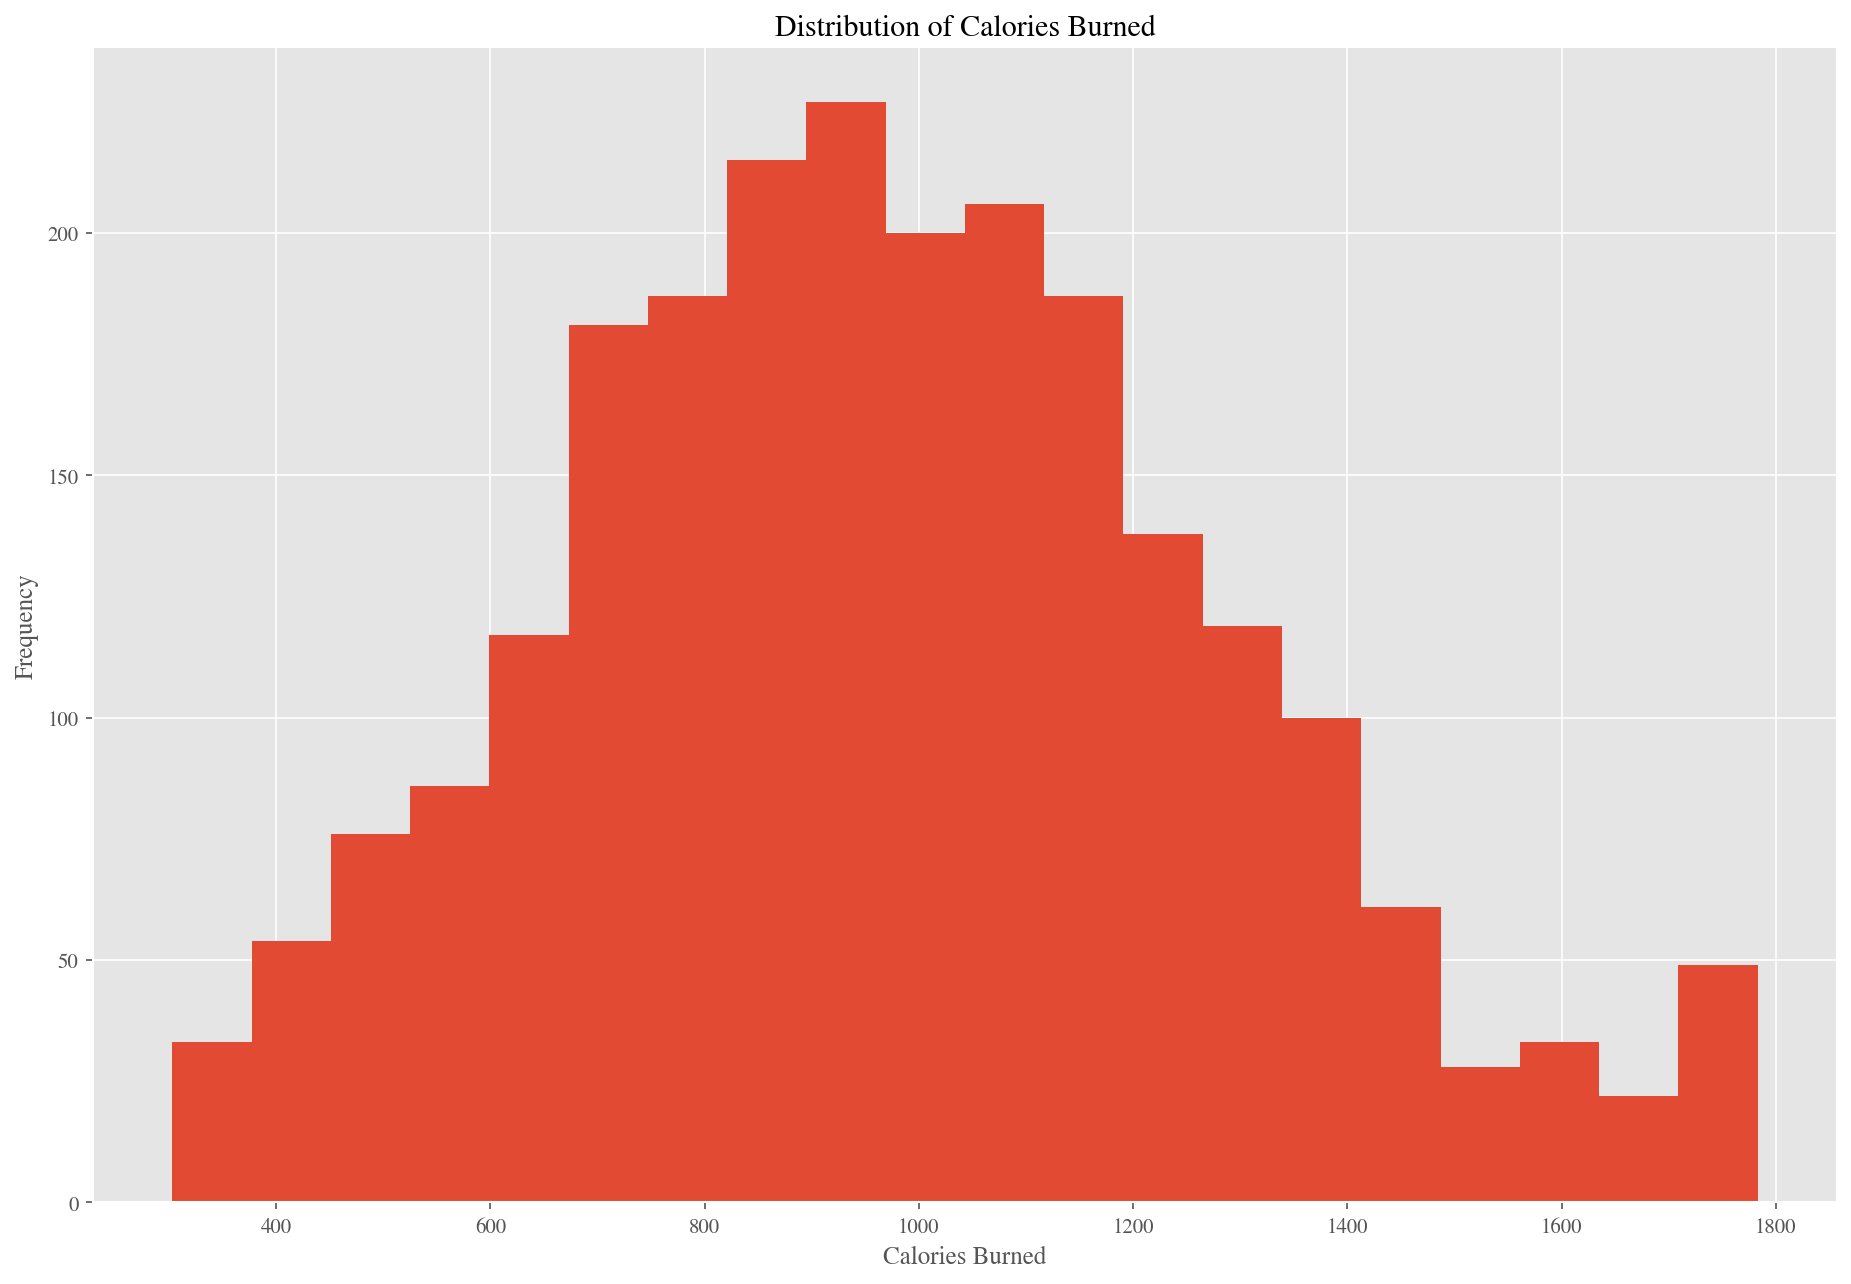

In [93]:
plt.hist(gym_df["Calories_Burned"], bins=20)
plt.xlabel("Calories Burned")
plt.ylabel("Frequency")
plt.title("Distribution of Calories Burned")
plt.show()

The histogram shows the distribution of calories burned . Most workout records are concentrated in the middle range,

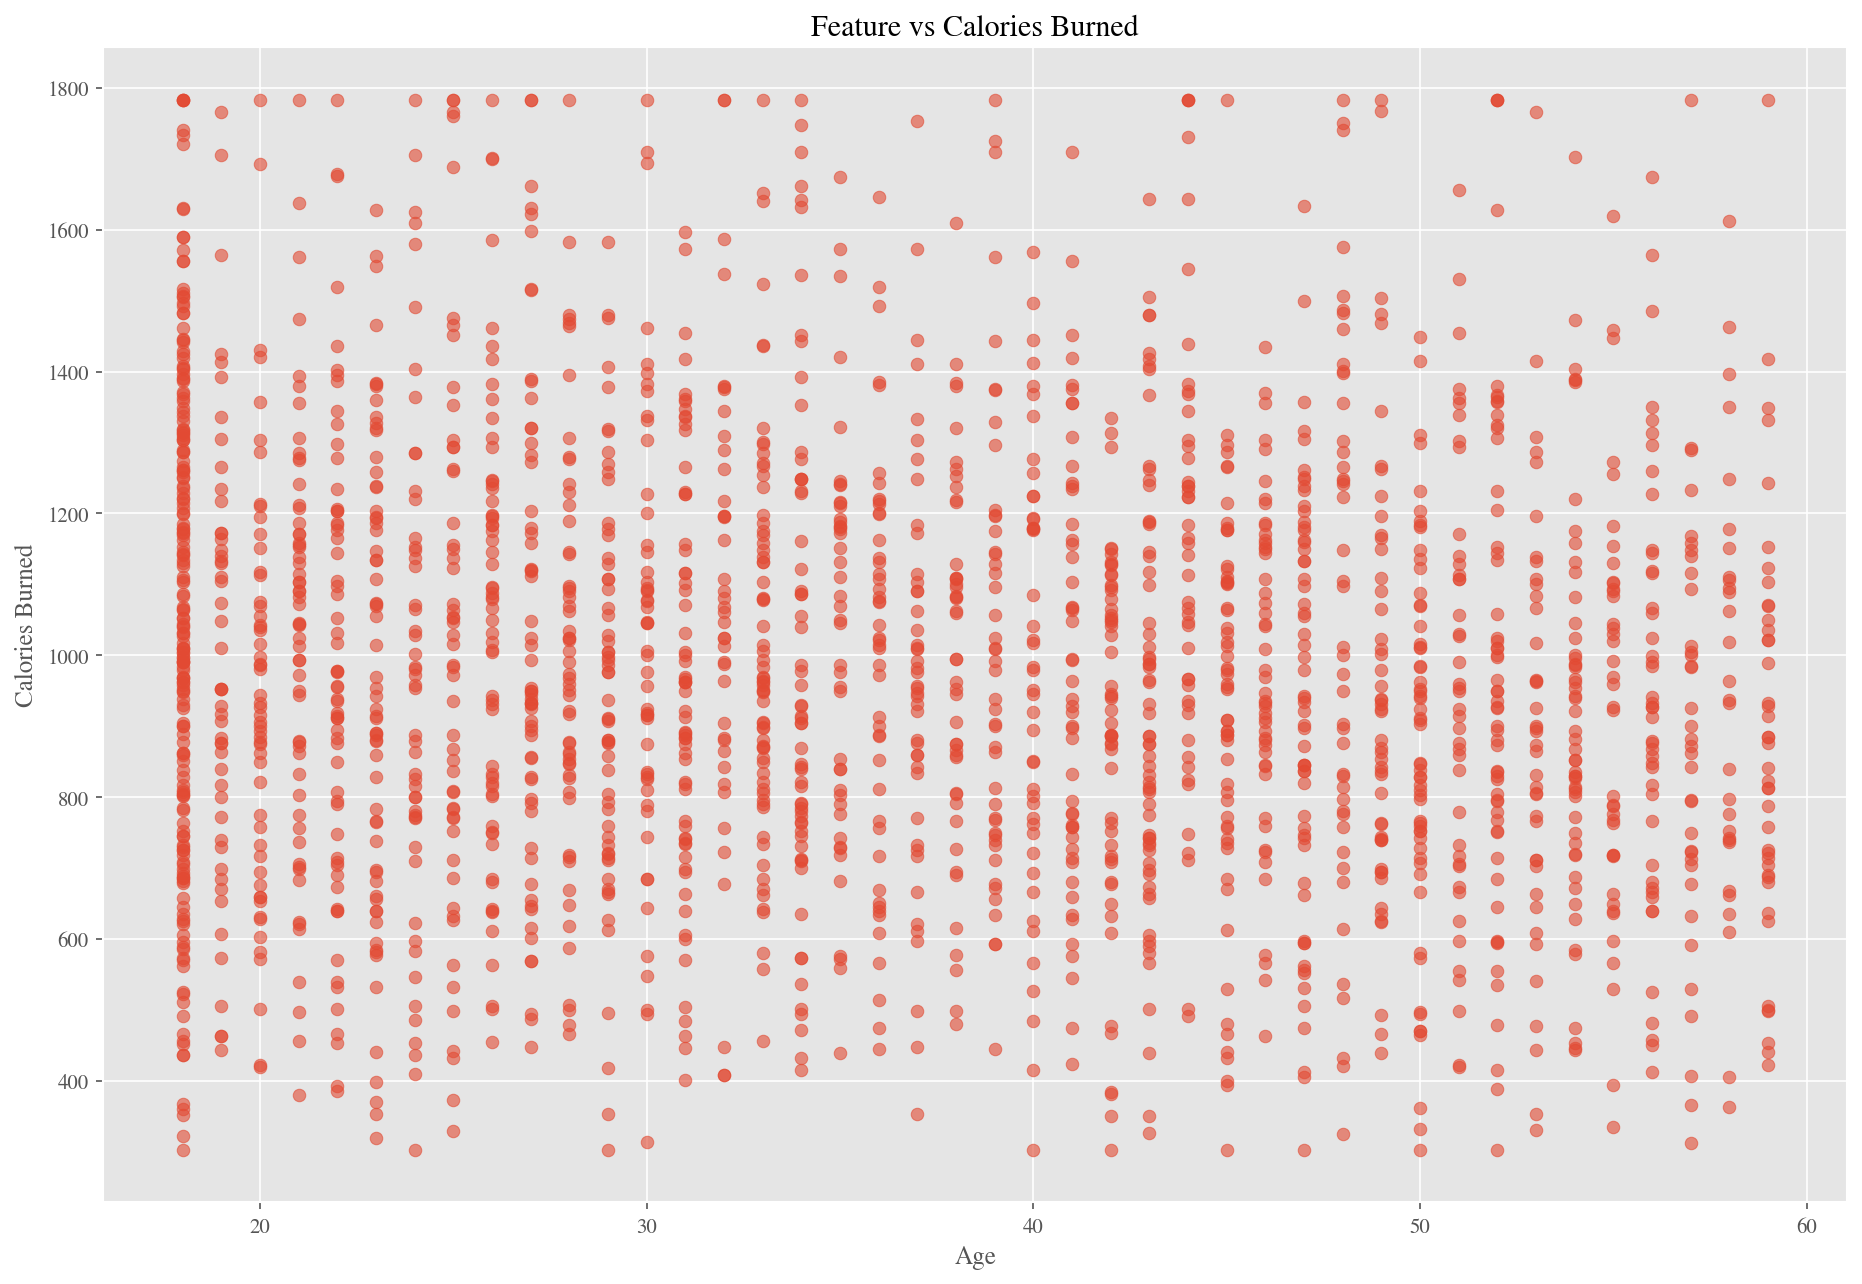

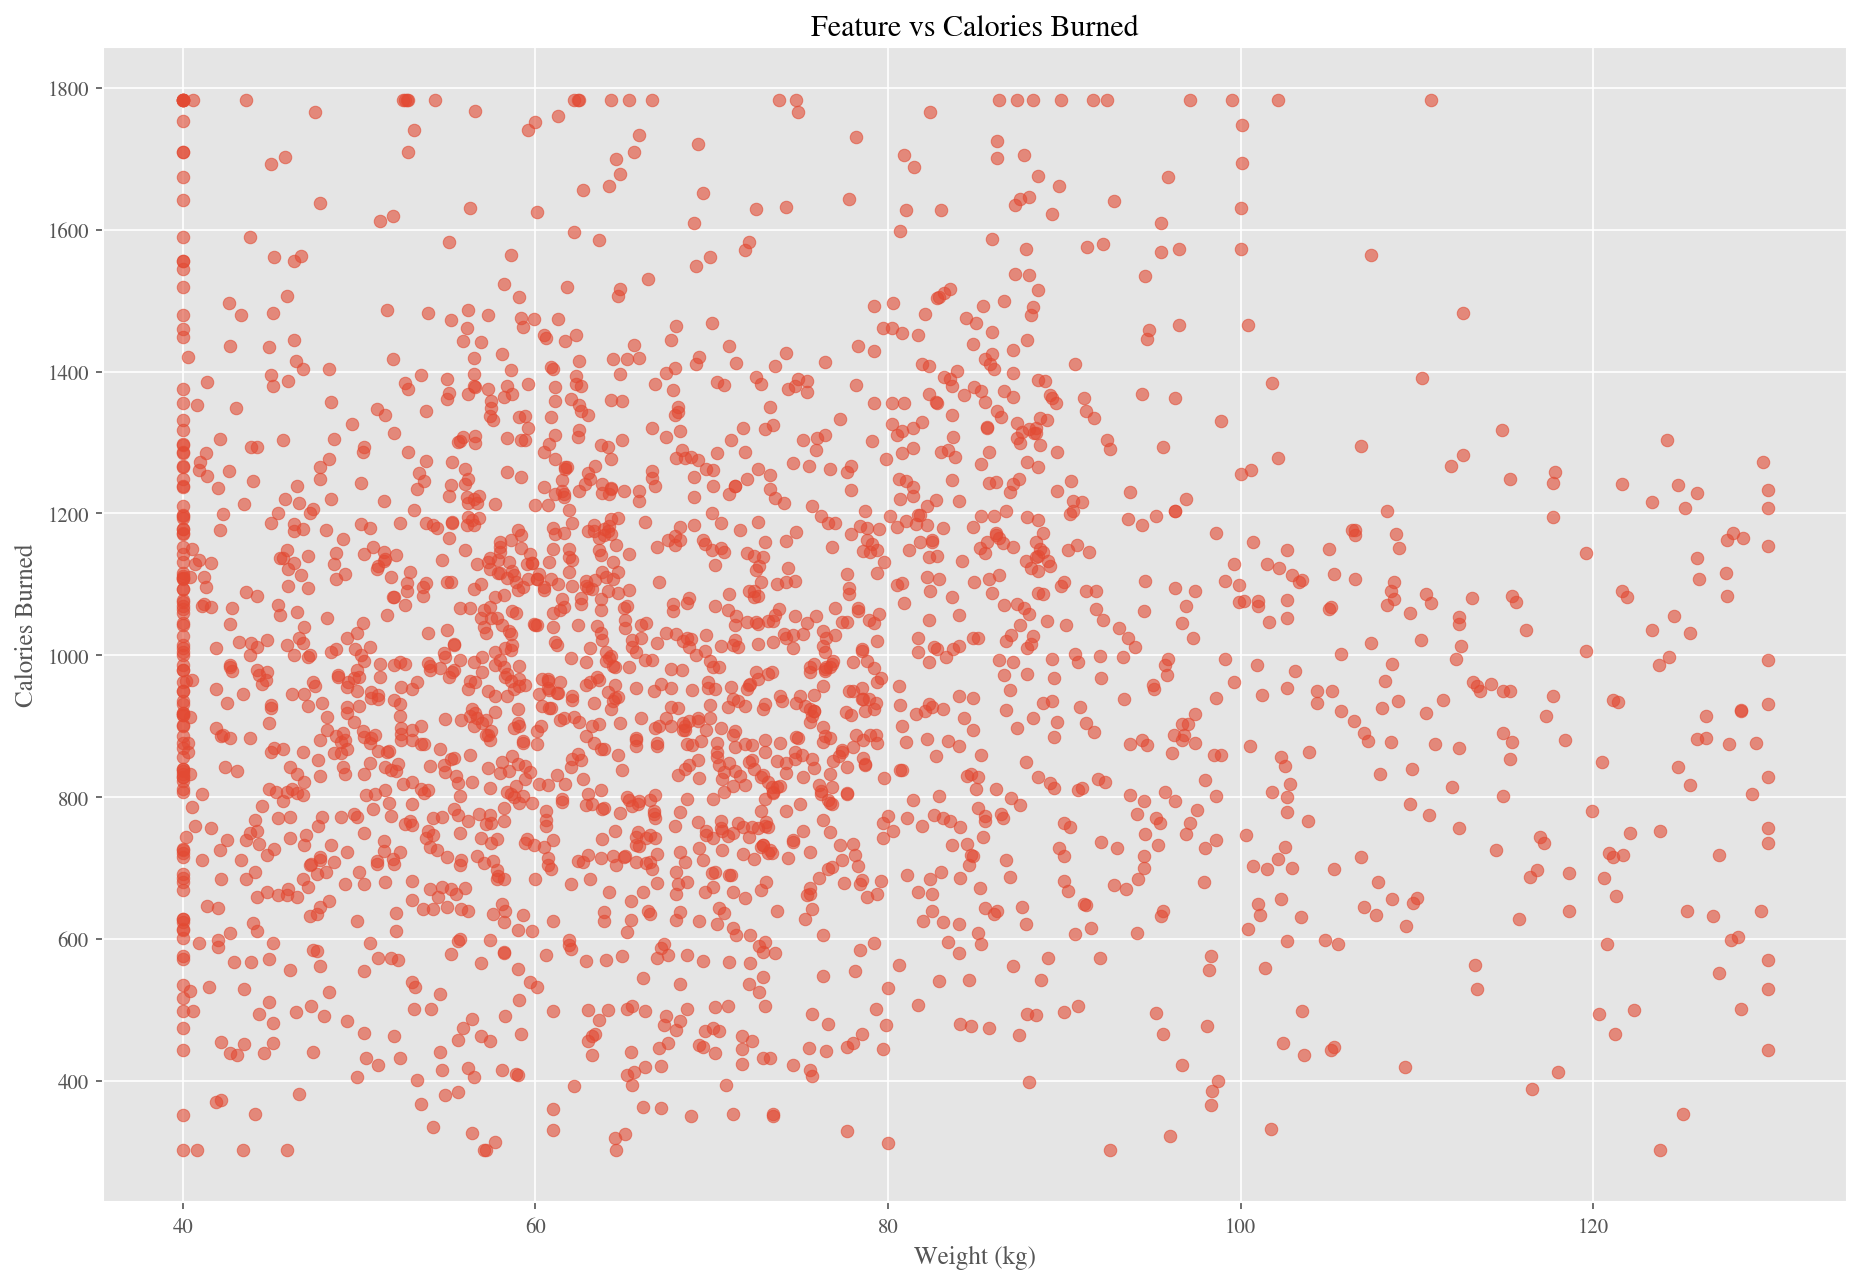

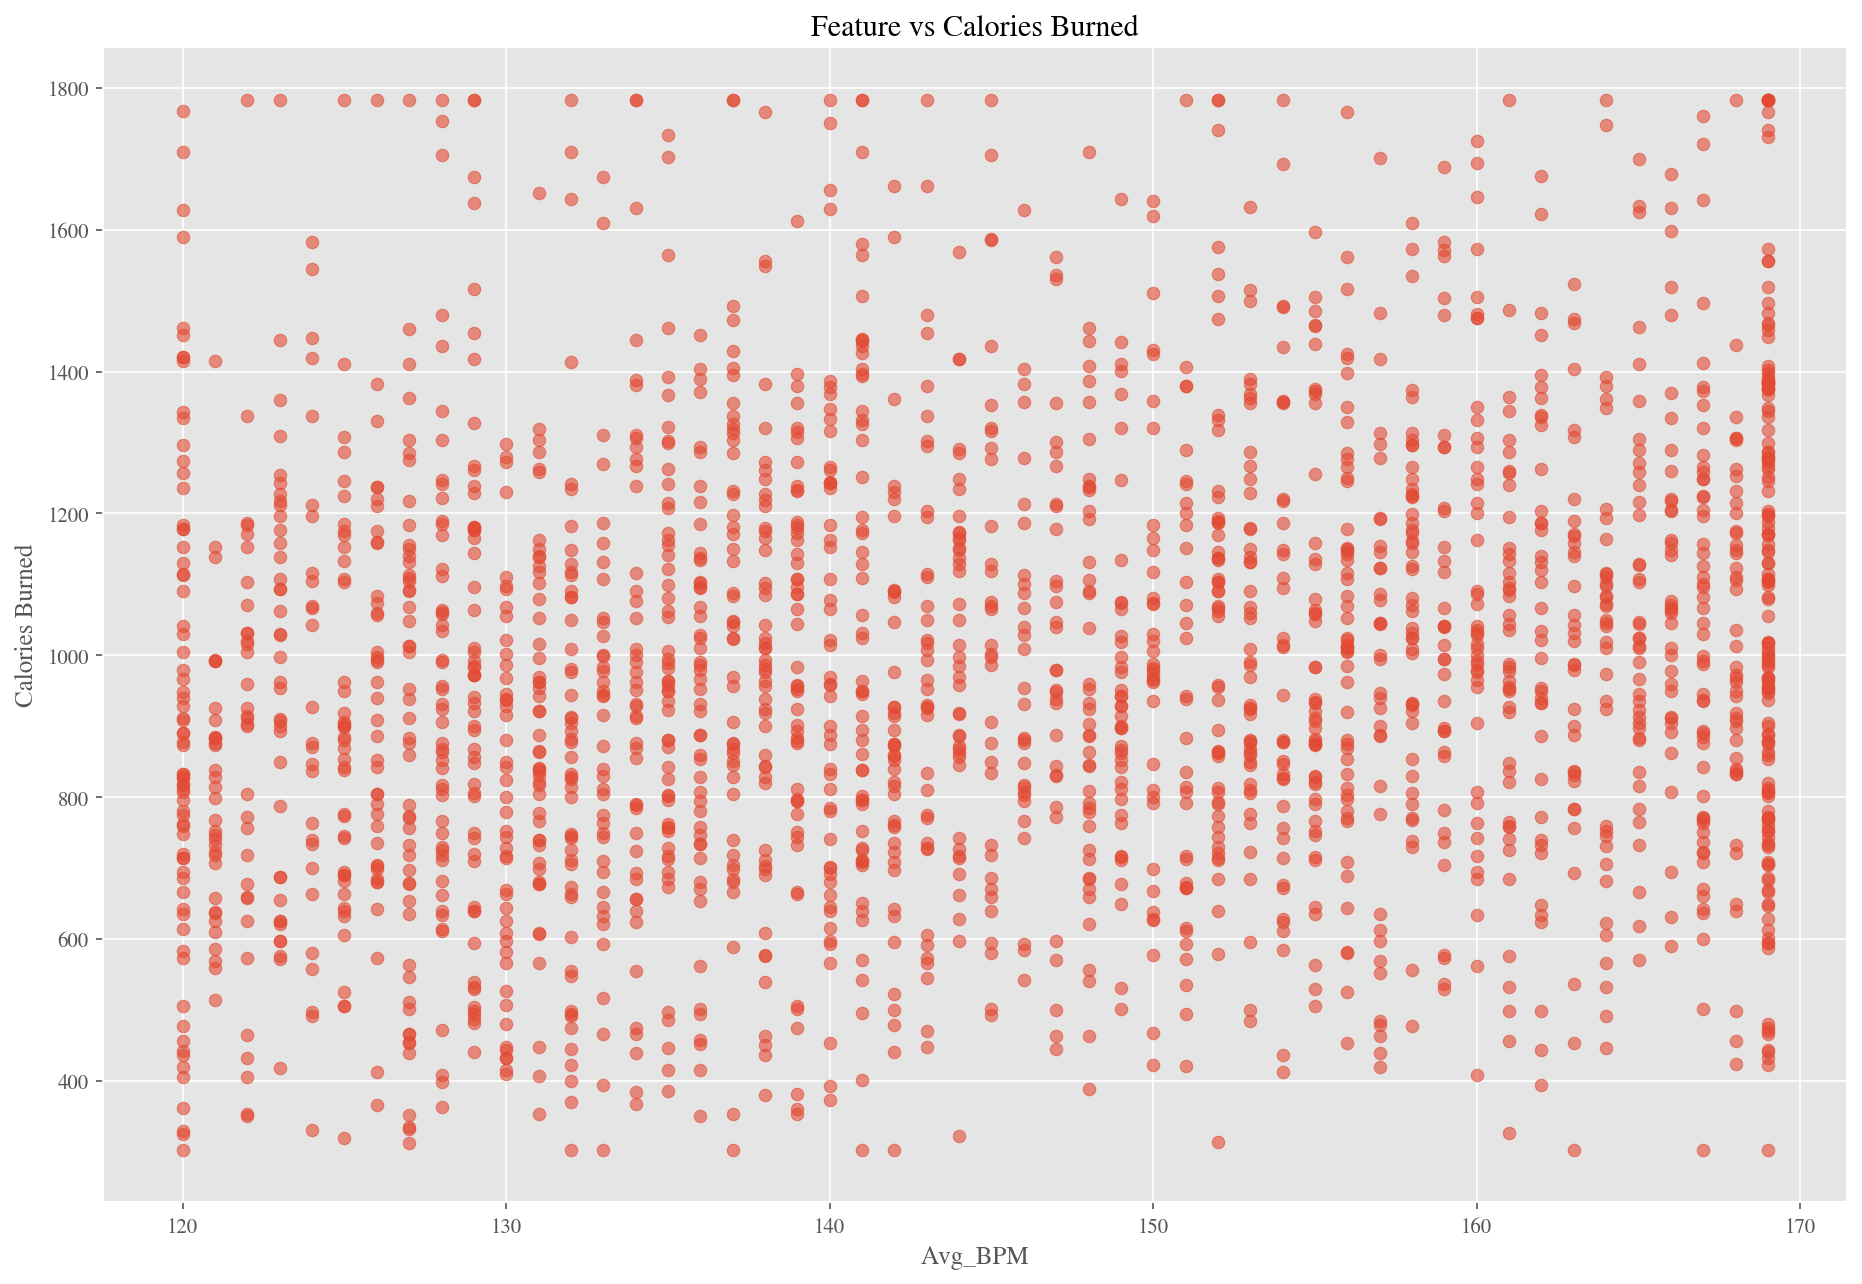

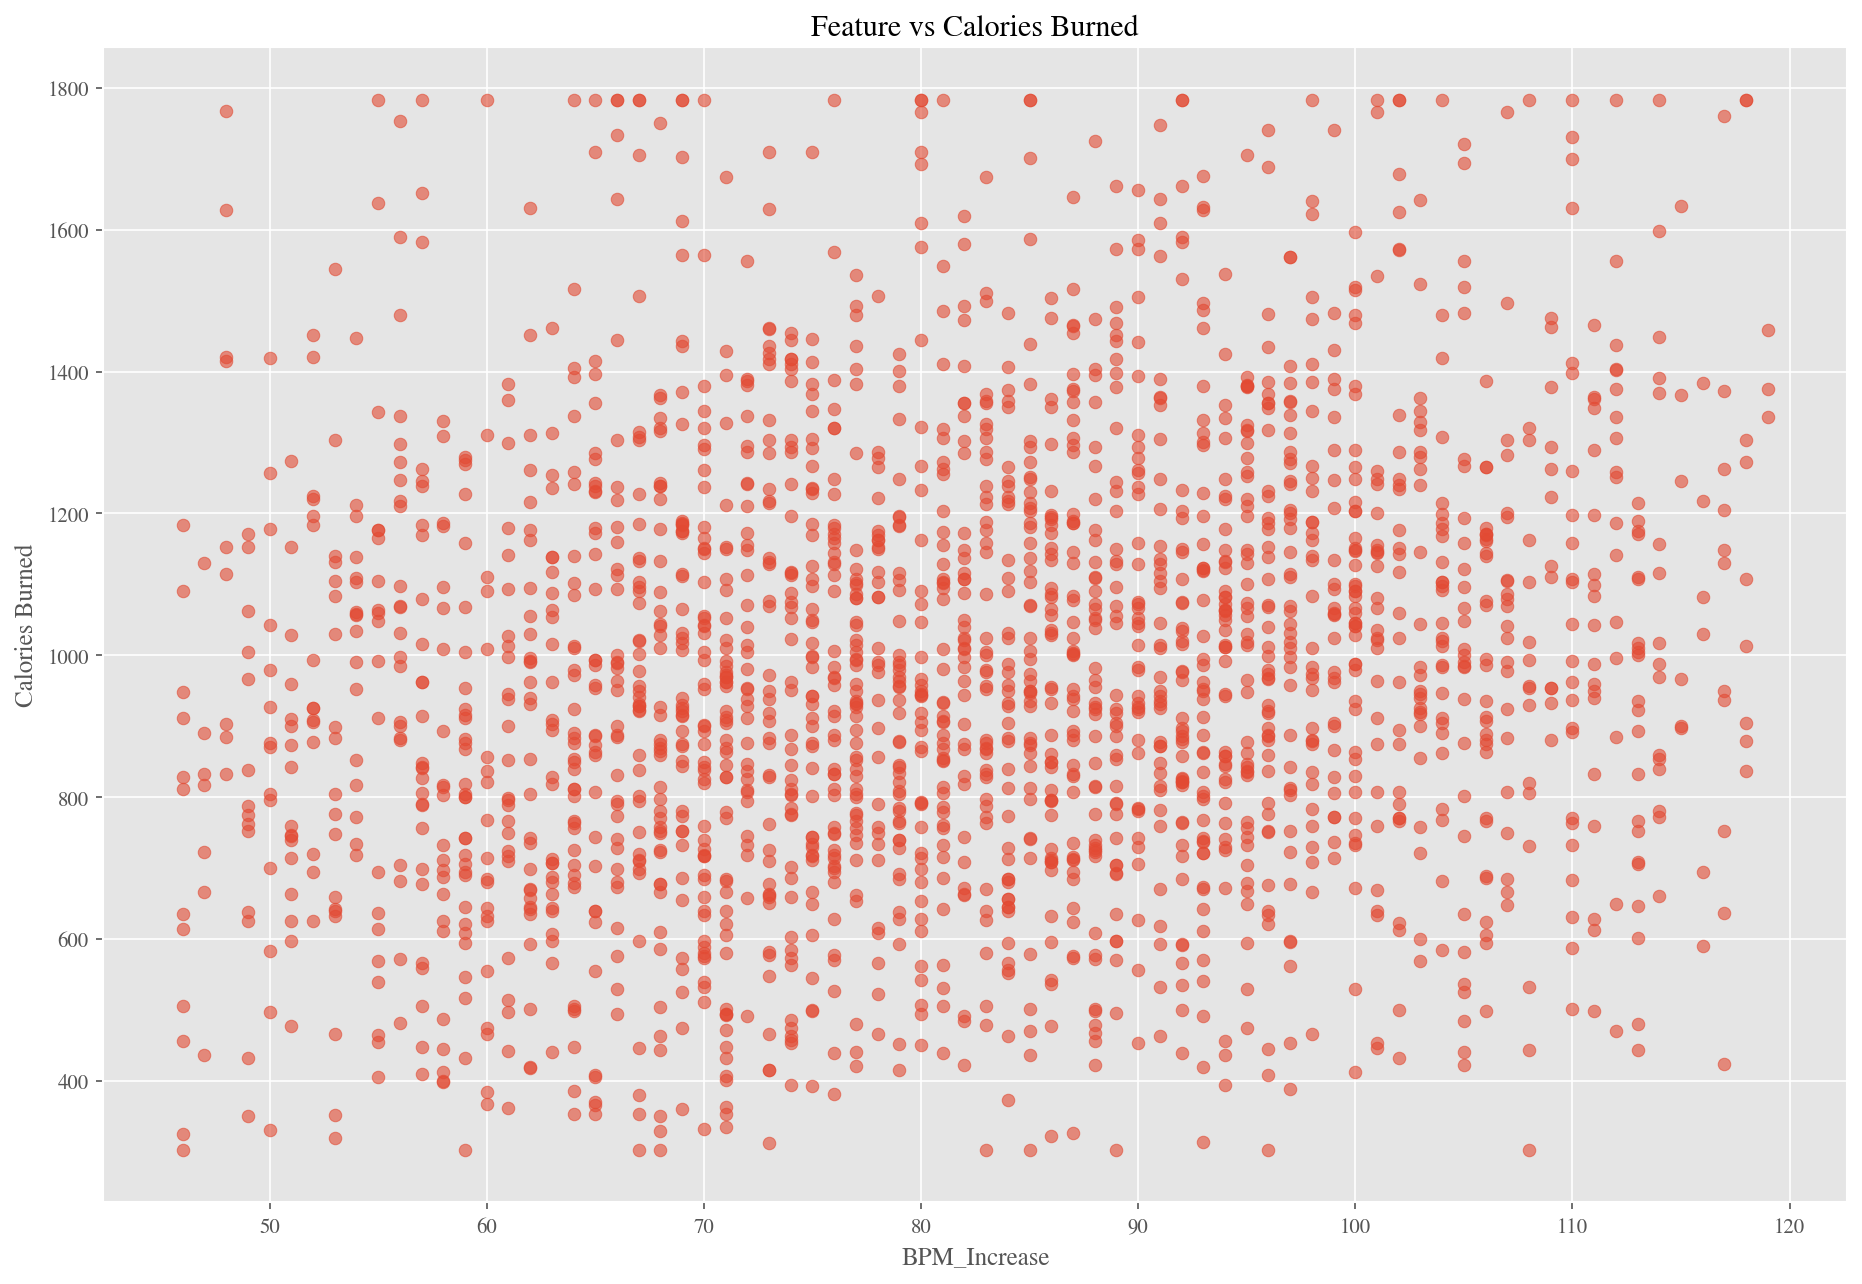

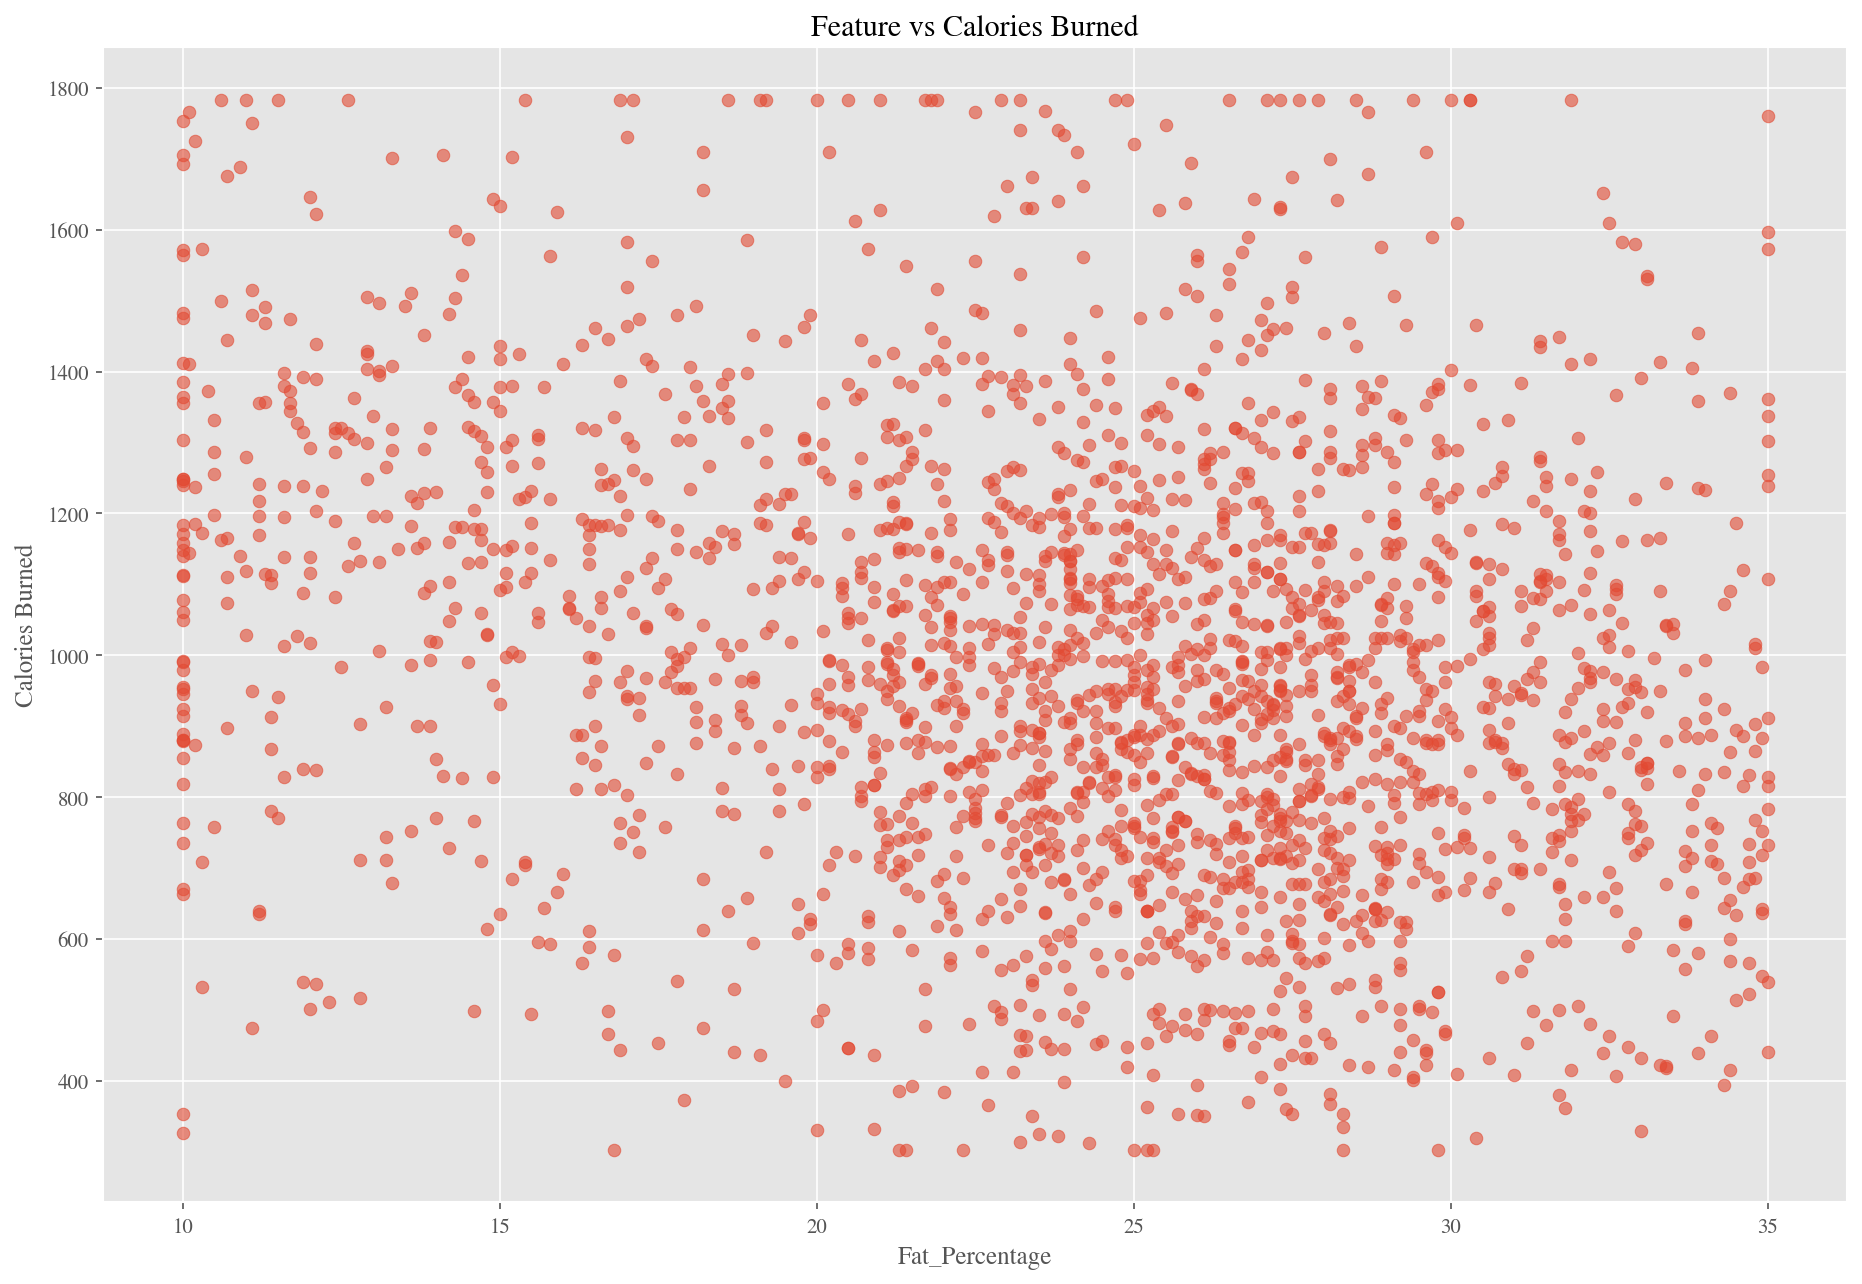

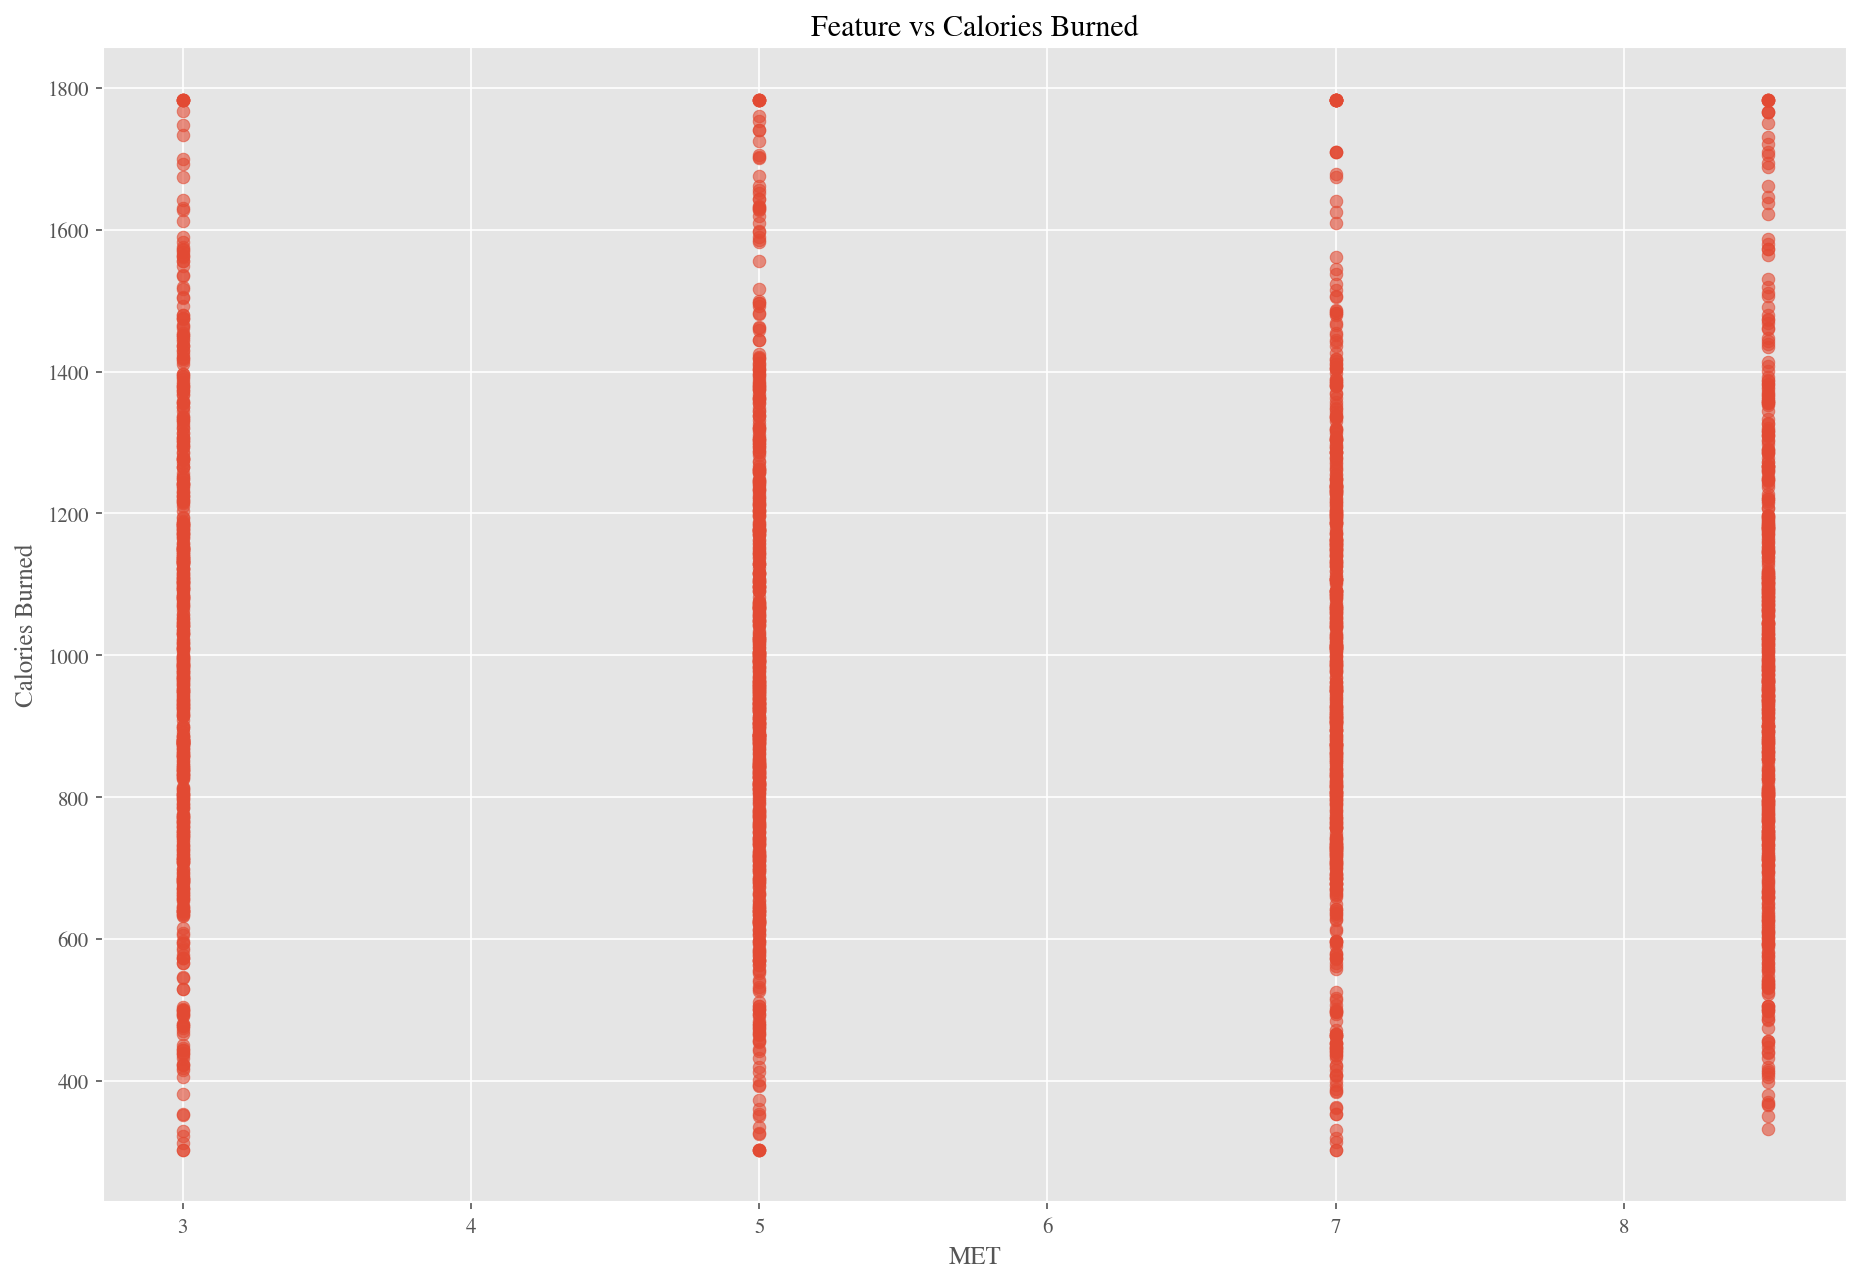

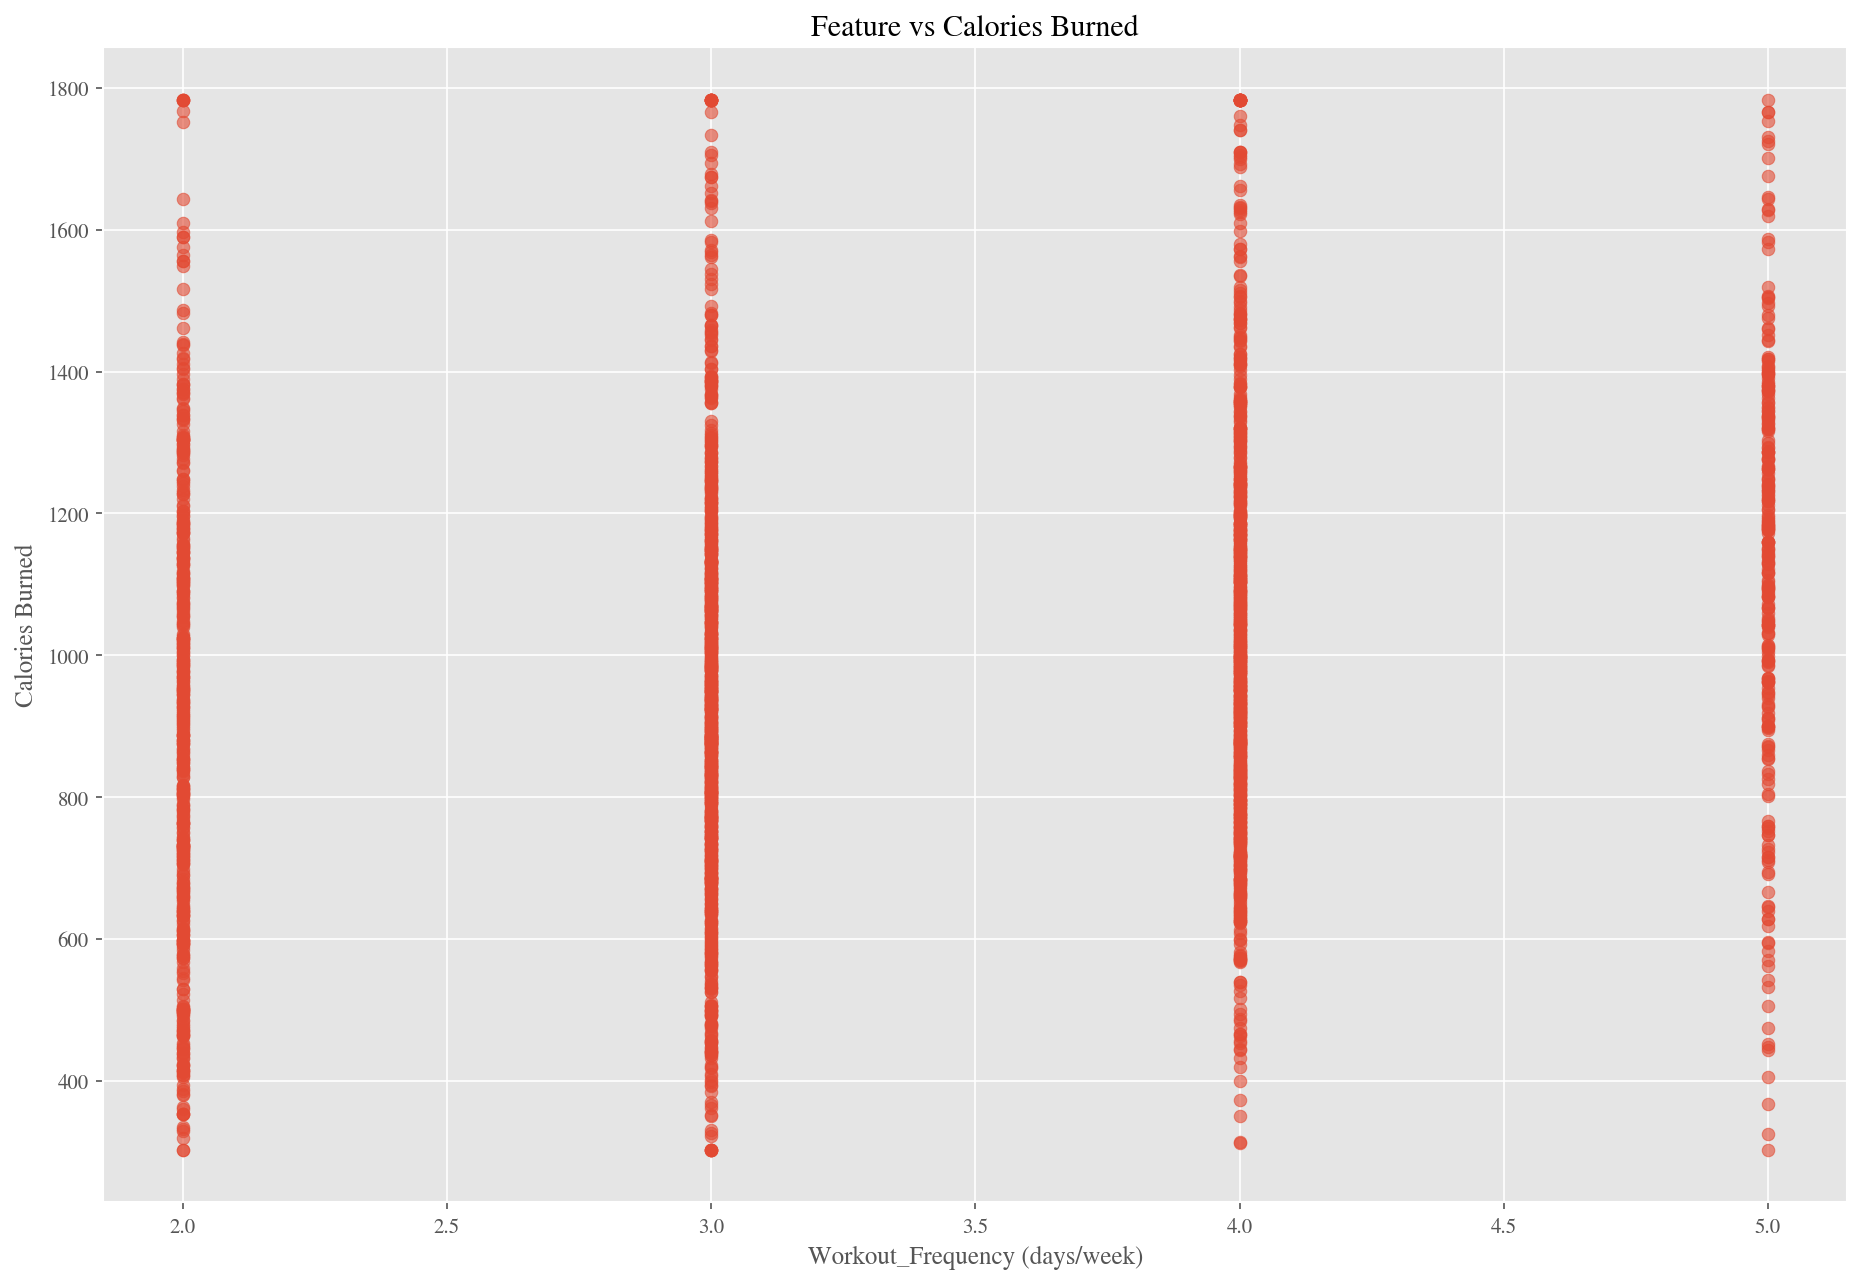

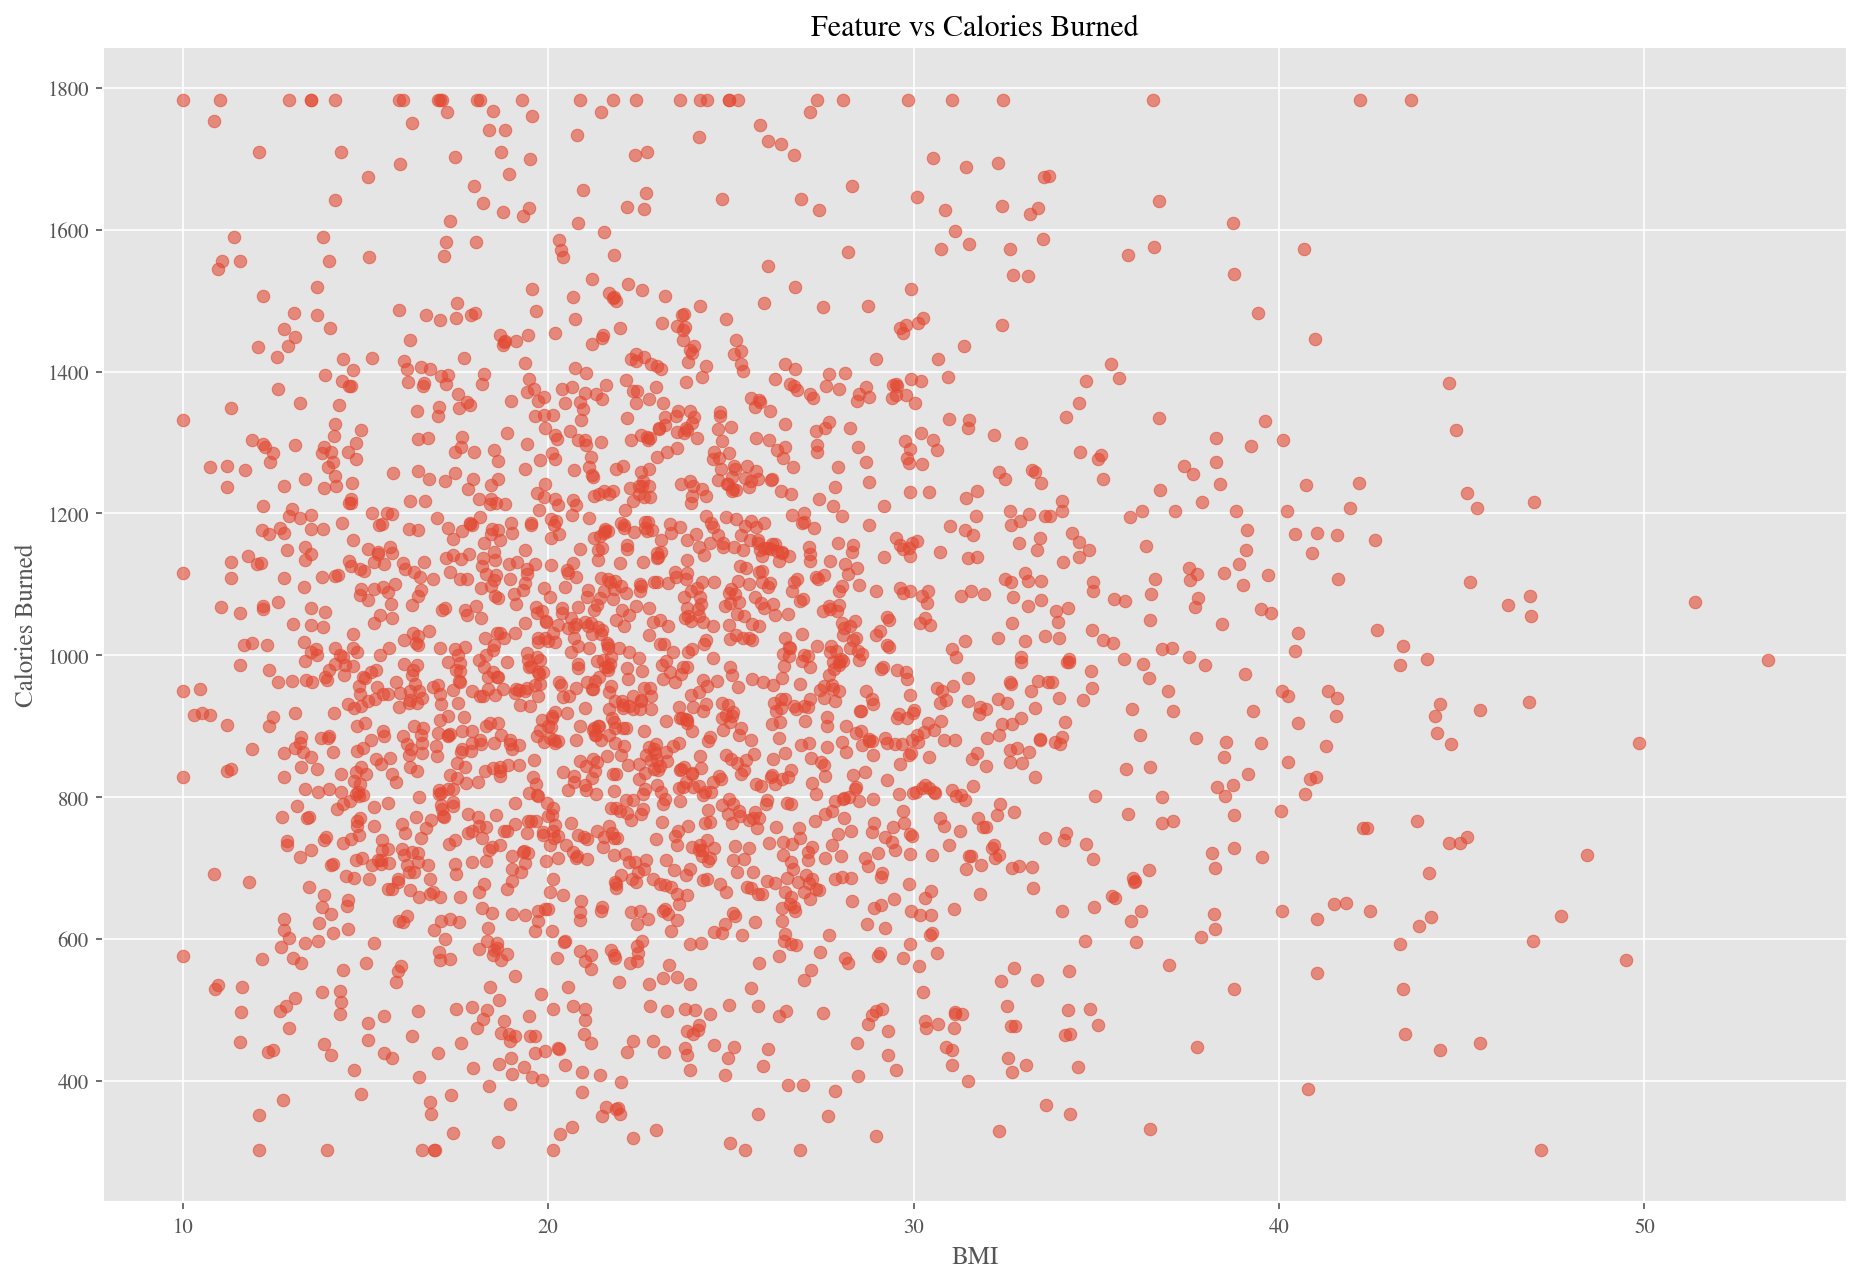

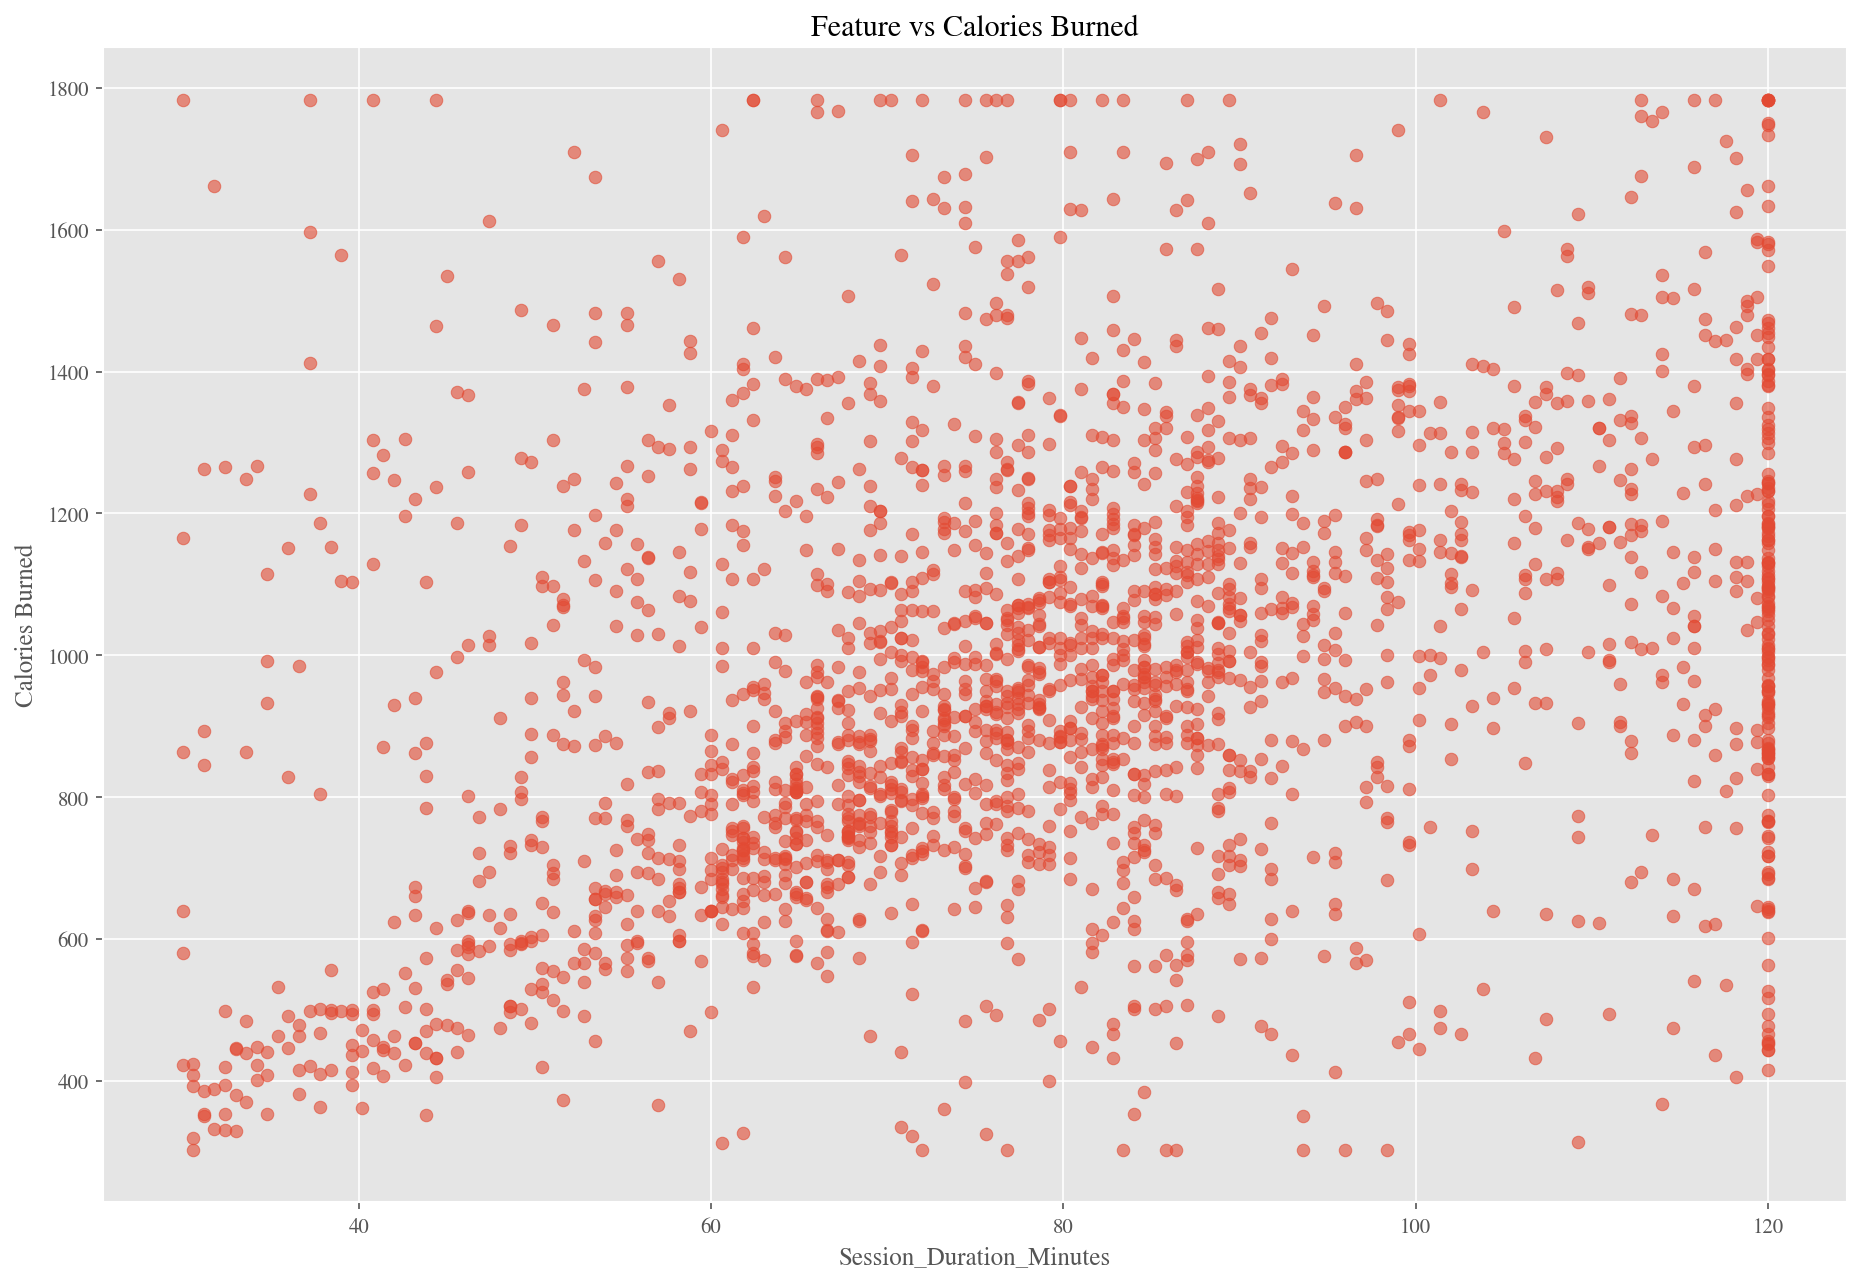

In [94]:
numeric_features = [
    "Age",
    "Weight (kg)",
    "Avg_BPM",
    "BPM_Increase",
    "Fat_Percentage",
    "MET",
    "Workout_Frequency (days/week)",
    "BMI",
    "Session_Duration_Minutes"
]

for col in numeric_features:
    plt.scatter(data=gym_df, x=col, y="Calories_Burned", alpha=0.6)
    plt.title("Feature vs Calories Burned")
    plt.xlabel(col)
    plt.ylabel("Calories Burned")
    plt.show()

These scatter plots show the relationship between each numerical feature and calories burned. Some variables, such as Session_Duration_Minutes, BPM_Increase appear more directly related to calories burned. Other variables, such as Age or Avg_BPM, may not show a strong individual linear relationship.

The distribution of MET and Workout_Frequency (days/week) looks like this because the feature values are discrete rather than continuous. Calories burned still vary a lot even within the same category, which means other variables may also strongly affect calorie burn. This suggests that using only MET or Workout_Frequency (days/week) may not be sufficient for prediction.

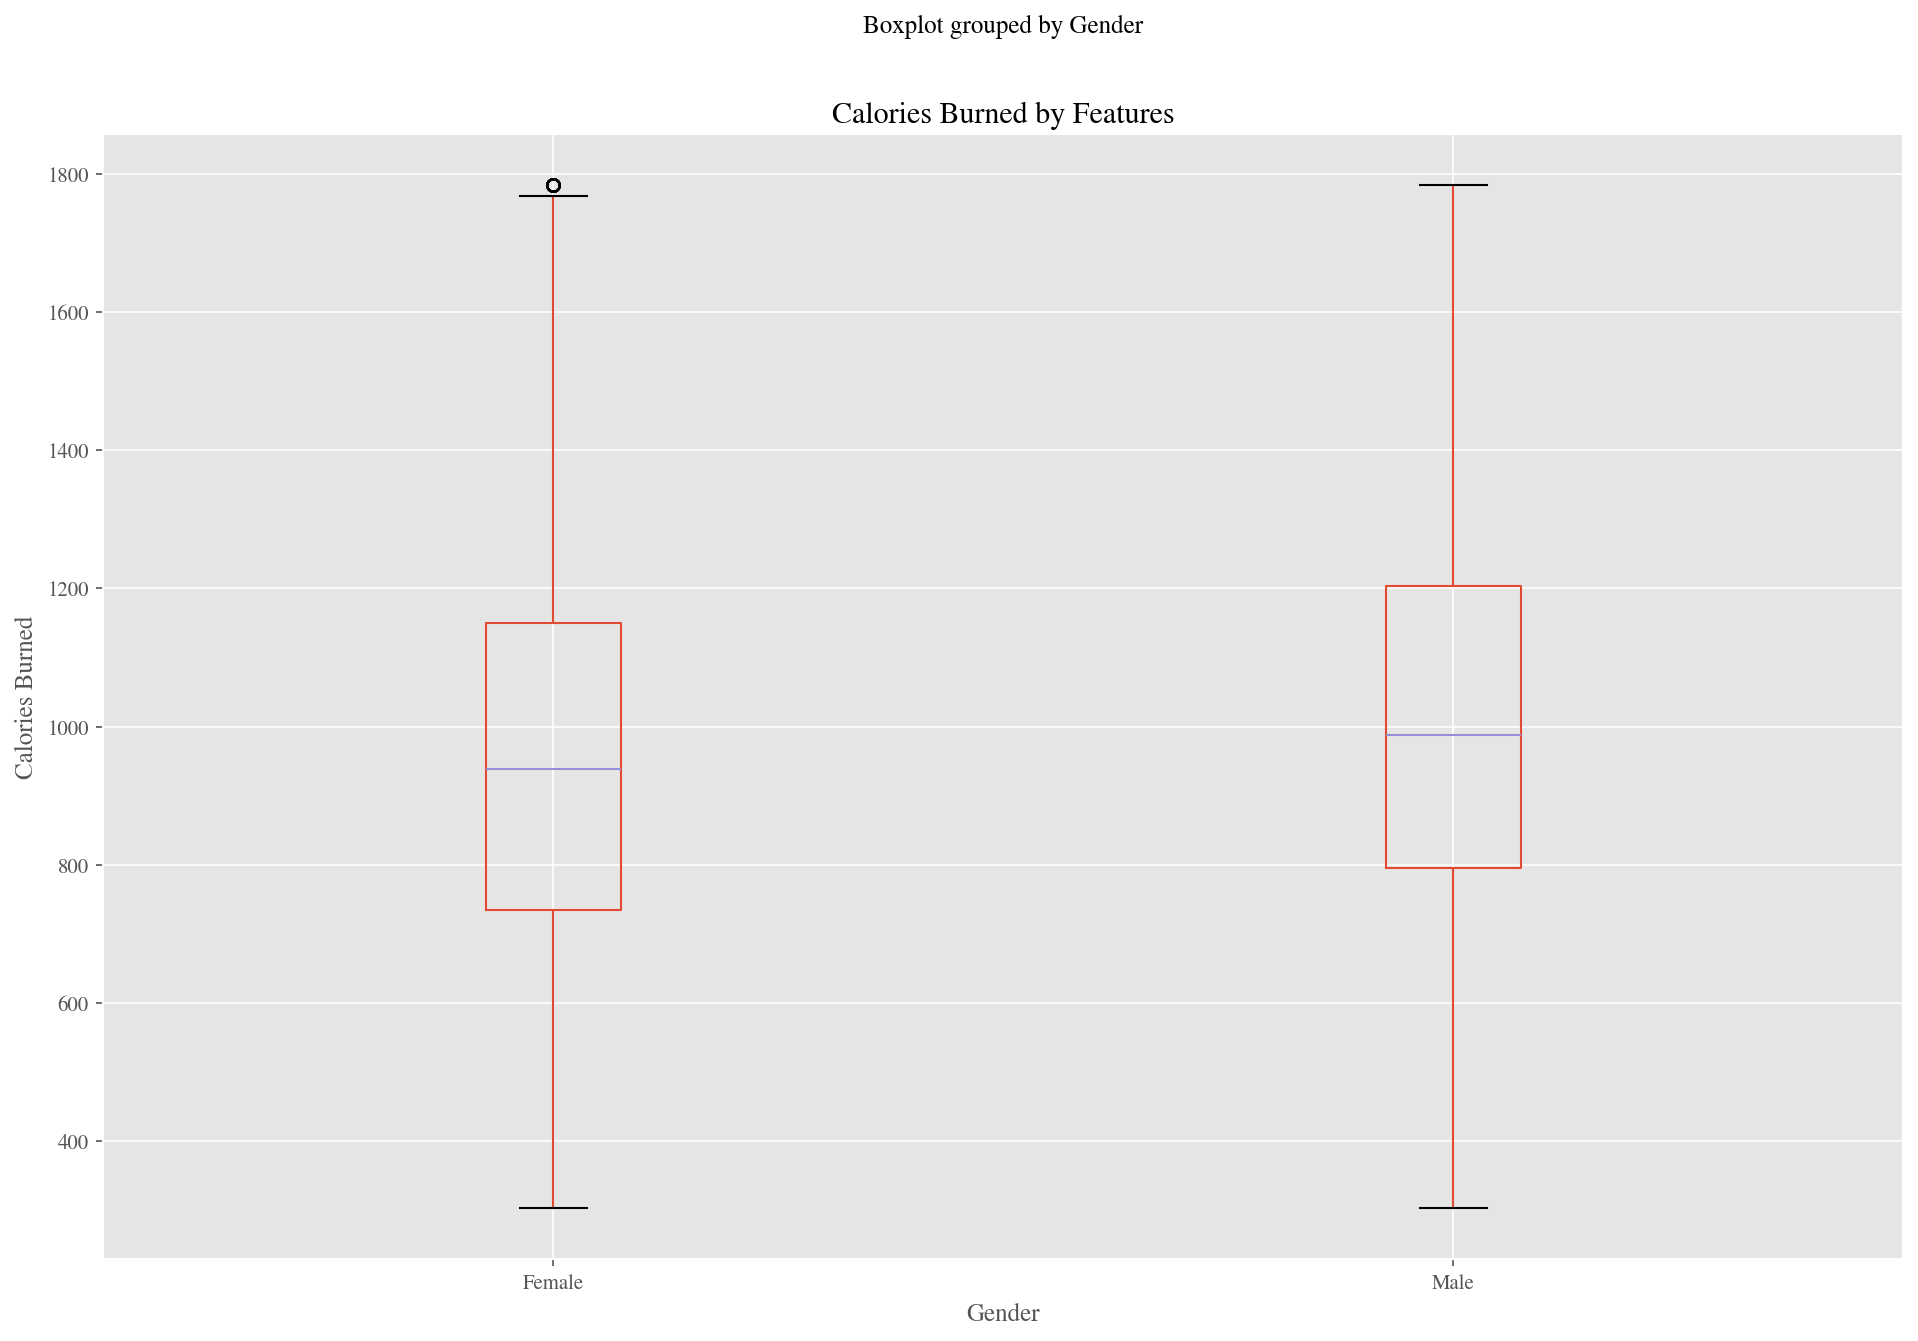

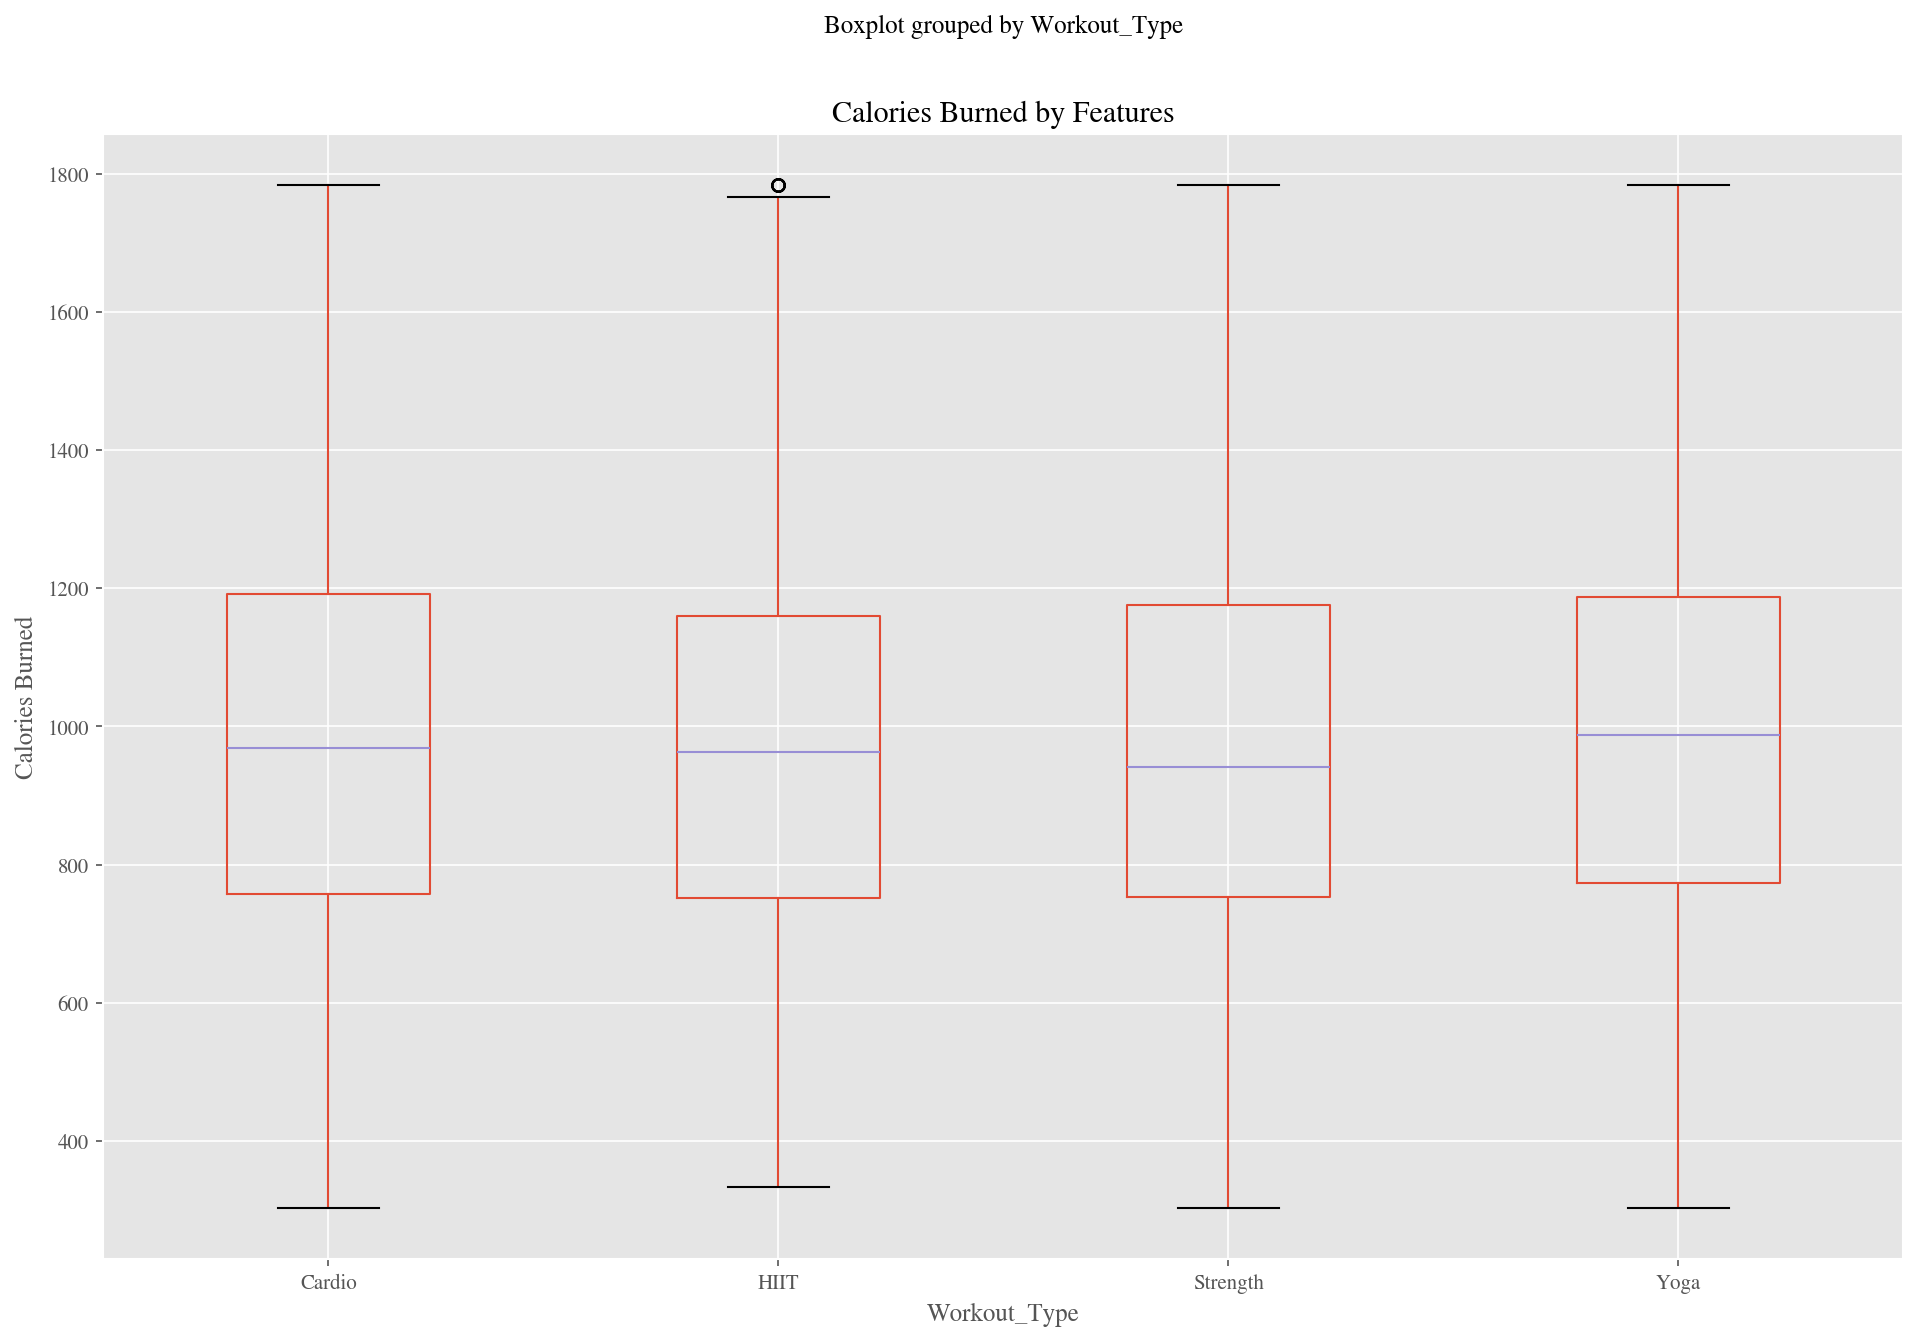

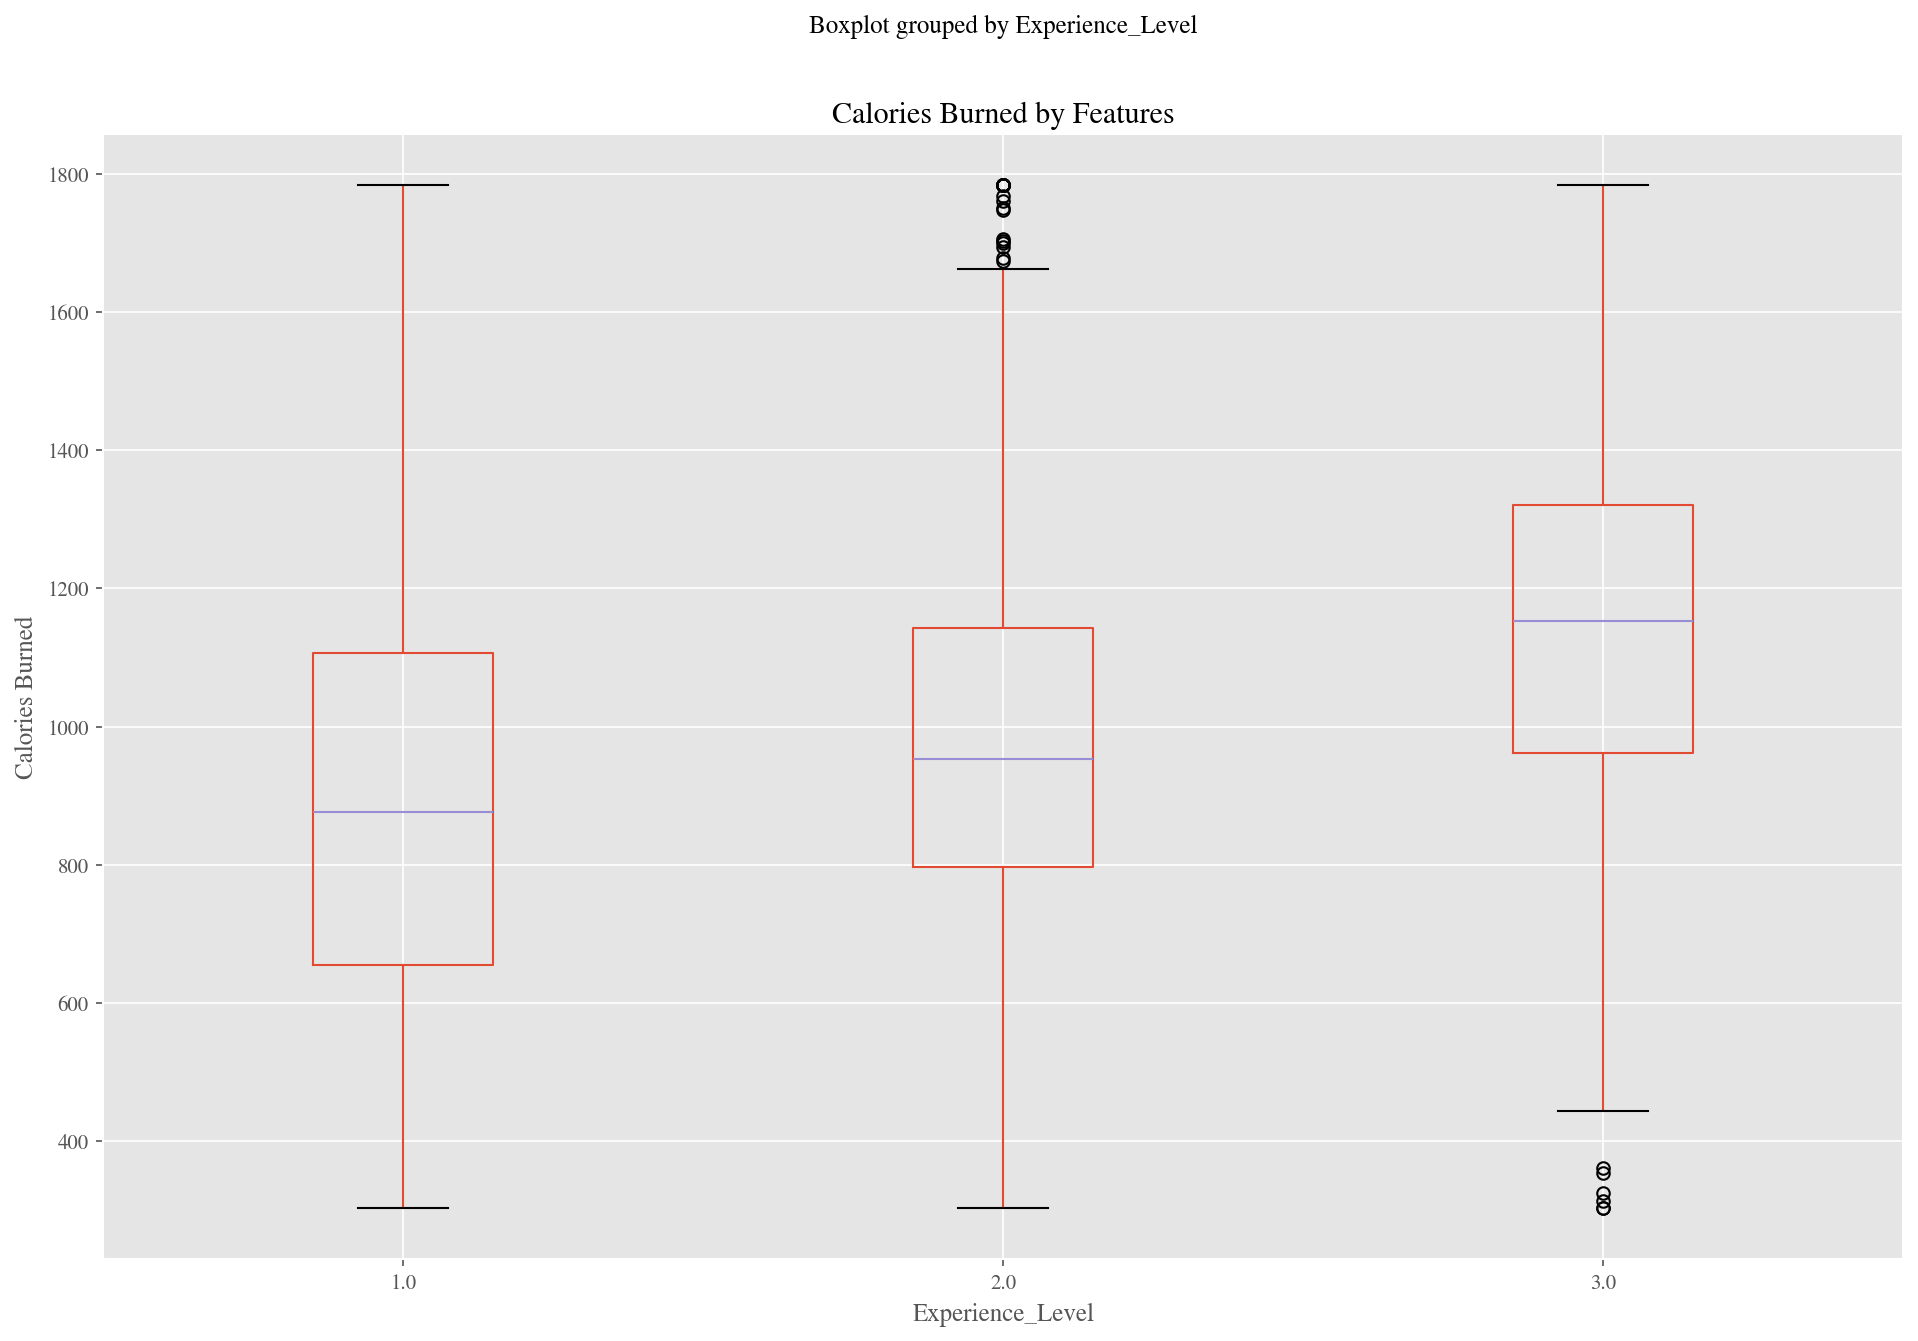

In [95]:
categorical_features = [
    "Gender",
    "Workout_Type",
    "Experience_Level"
]

for col in categorical_features:
    gym_df.boxplot(column="Calories_Burned", by=col)
    plt.title("Calories Burned by Features")
    plt.xlabel(col)
    plt.ylabel("Calories Burned")
    plt.show()

These boxplots compare calories burned across categorical variables.

The boxplot shows that Calories_Burned differs noticeably across Experience_Level groups. Users with higher experience levels tend to burn more calories. 

# 7. Prepare Data for Modelling

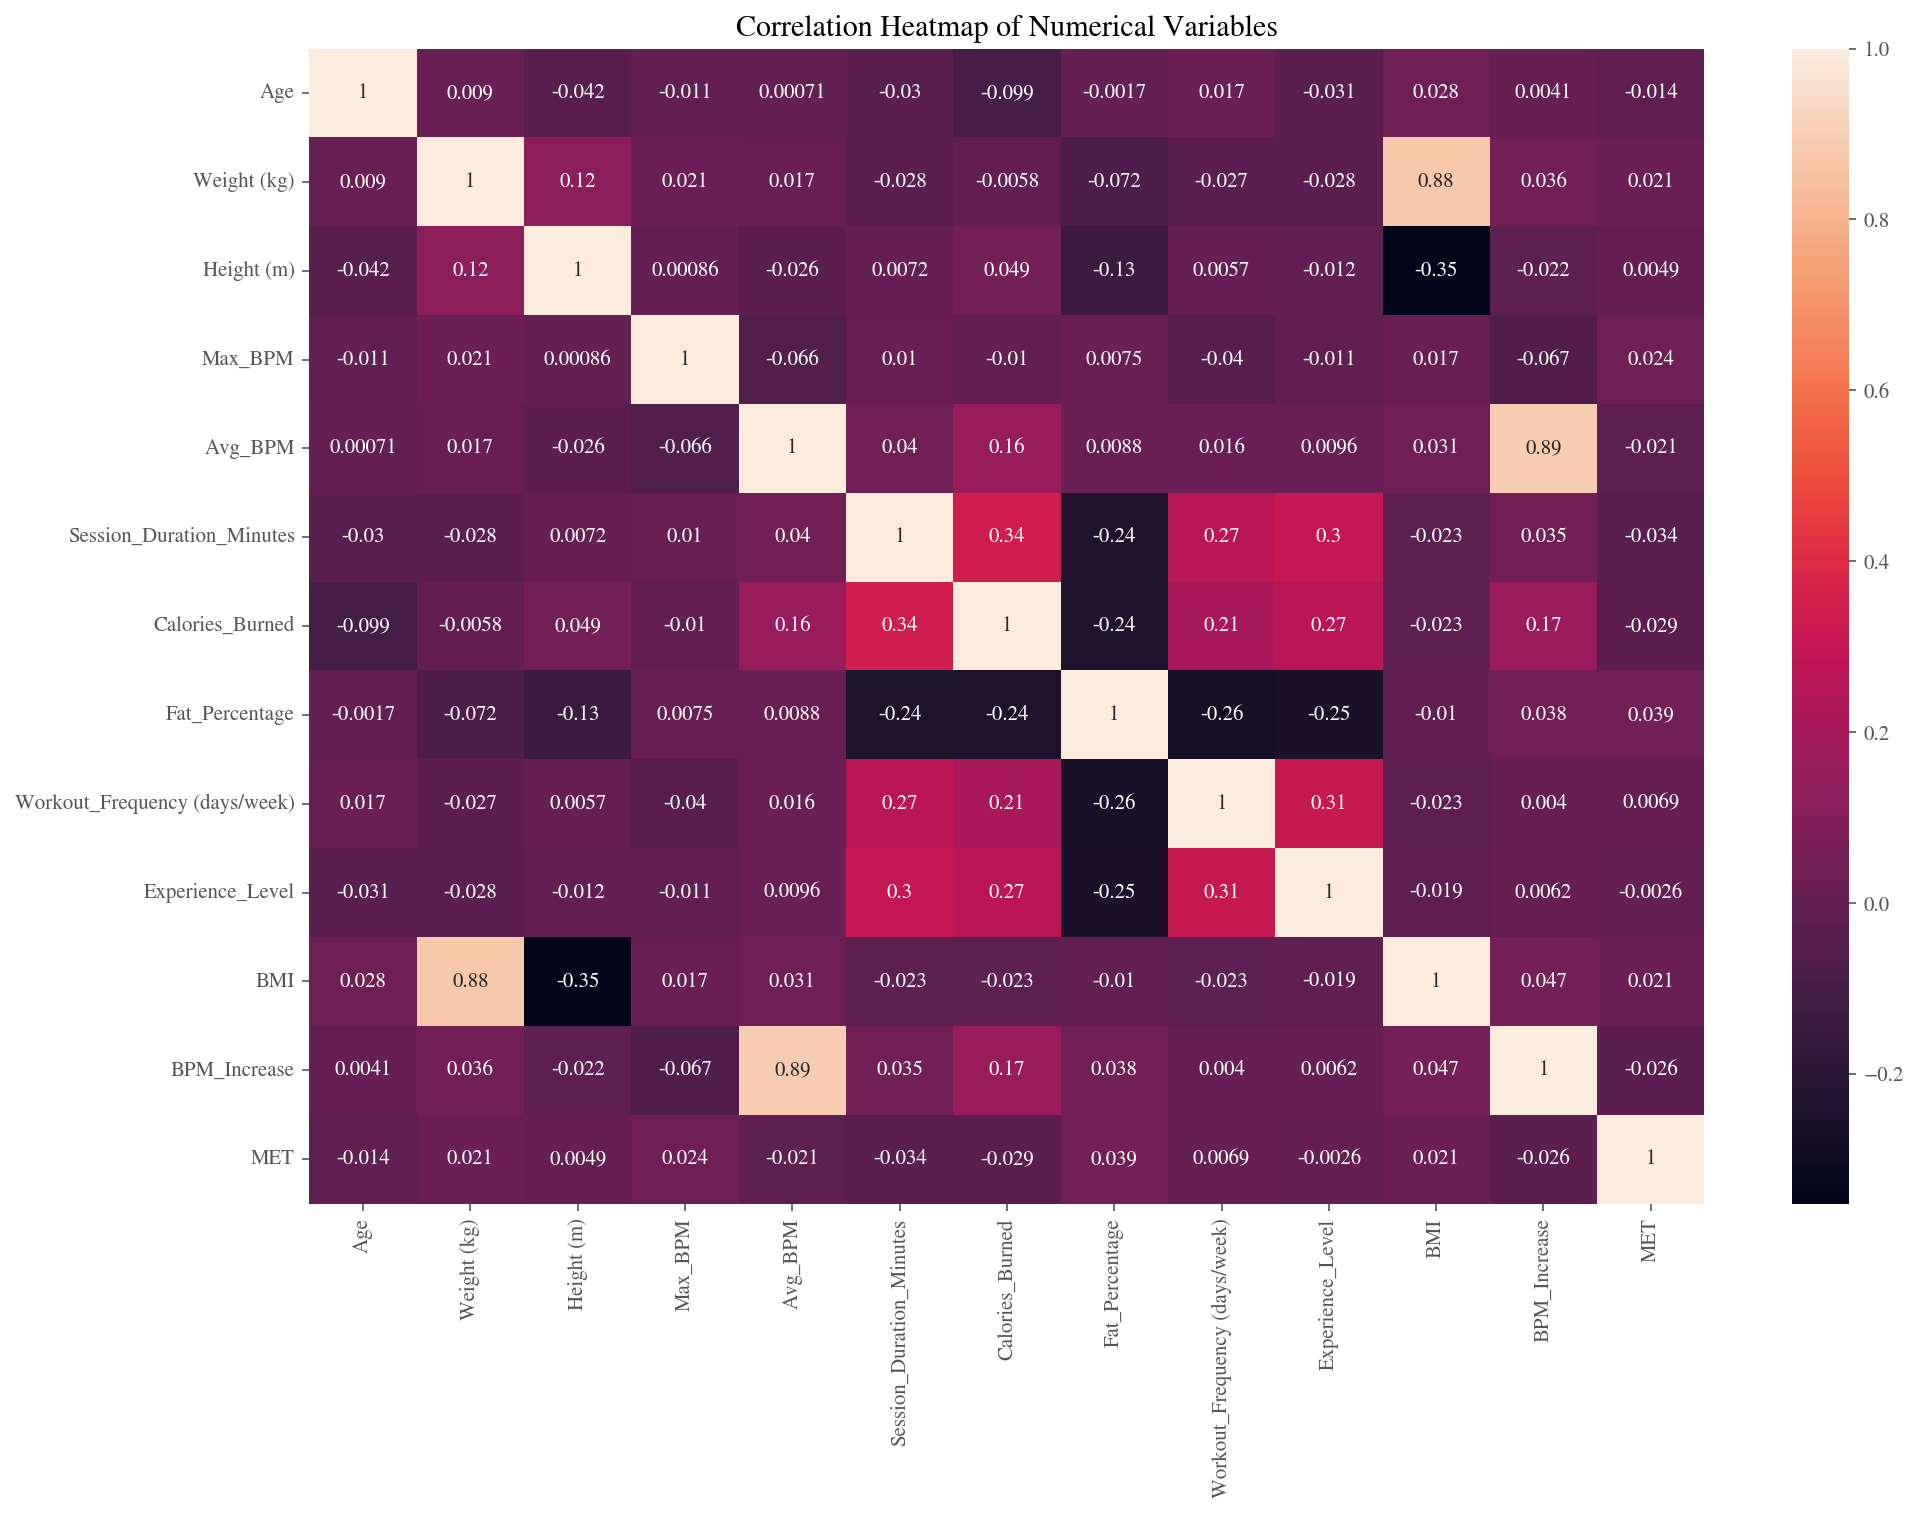

In [96]:
numeric_cols = [
    "Age",
    "Weight (kg)",
    "Height (m)",
    "Max_BPM",
    "Avg_BPM",
    "Session_Duration_Minutes",
    "Calories_Burned",
    "Fat_Percentage",
    "Workout_Frequency (days/week)",
    "Experience_Level",
    "BMI",
    "BPM_Increase",
    "MET"
]

corr_df = gym_df[numeric_cols].corr()
sns.heatmap(corr_df, annot=True)
plt.title("Correlation Heatmap of Numerical Variables")
plt.show()

The correlation heatmap was used to examine the linear relationships between numerical variables. Calories_Burned appears to be more related to variables such as Session_Duration_Minutes,BPM_Increase, Experience_Level, Workout_Frequency (days/week). 

In [97]:
gym_df = pd.get_dummies(gym_df, dtype=int)
gym_df.head()

,Age,Weight (kg),Height (m),Max_BPM,Avg_BPM,Calories_Burned,Fat_Percentage,Workout_Frequency (days/week),Experience_Level,BMI,Session_Duration_Minutes,BPM_Increase,MET,Gender_Female,Gender_Male,Workout_Type_Cardio,Workout_Type_HIIT,Workout_Type_Strength,Workout_Type_Yoga
0,56.0,88.3,1.71,180.0,157.0,1313.0,12.6,4.0,3.0,30.20,101.4,97.0,3.0,0,1,0,0,0,1
1,46.0,74.9,1.53,179.0,151.0,883.0,33.9,4.0,2.0,32.00,78.0,85.0,8.5,1,0,0,1,0,0
2,32.0,68.1,1.66,167.0,122.0,677.0,33.4,4.0,2.0,24.71,66.6,68.0,7.0,1,0,1,0,0,0
3,25.0,53.2,1.70,190.0,164.0,532.0,28.8,3.0,1.0,18.41,35.4,108.0,5.0,0,1,0,0,1,0
4,38.0,46.1,1.79,188.0,158.0,556.0,29.2,3.0,1.0,14.39,38.4,90.0,5.0,0,1,0,0,1,0


In [98]:
train_df = gym_df.sample(frac=0.7, random_state=0)
test_df = gym_df.drop(train_df.index)
train_df.head()
test_df.head()

,Age,Weight (kg),Height (m),Max_BPM,Avg_BPM,Calories_Burned,Fat_Percentage,Workout_Frequency (days/week),Experience_Level,BMI,Session_Duration_Minutes,BPM_Increase,MET,Gender_Female,Gender_Male,Workout_Type_Cardio,Workout_Type_HIIT,Workout_Type_Strength,Workout_Type_Yoga
0,56.0,88.3,1.71,180.0,157.0,1313.0,12.6,4.0,3.0,30.20,101.4,97.0,3.0,0,1,0,0,0,1
3,25.0,53.2,1.70,190.0,164.0,532.0,28.8,3.0,1.0,18.41,35.4,108.0,5.0,0,1,0,0,1,0
7,40.0,69.7,1.51,189.0,141.0,895.0,30.6,3.0,2.0,30.57,76.2,77.0,7.0,1,0,1,0,0,0
21,38.0,71.9,1.77,197.0,142.0,875.0,25.7,2.0,1.0,22.95,67.2,70.0,7.0,0,1,1,0,0,0
24,39.0,64.3,1.69,190.0,148.0,925.0,26.9,4.0,2.0,22.51,75.0,90.0,8.5,1,0,0,1,0,0


One limitation is that the models were evaluated using a single train-test split. In future work, k-fold cross-validation could be used to obtain a more stable estimate of model performance.

# 8. Model Building and Evaluation

## 8.1 Linear Regression

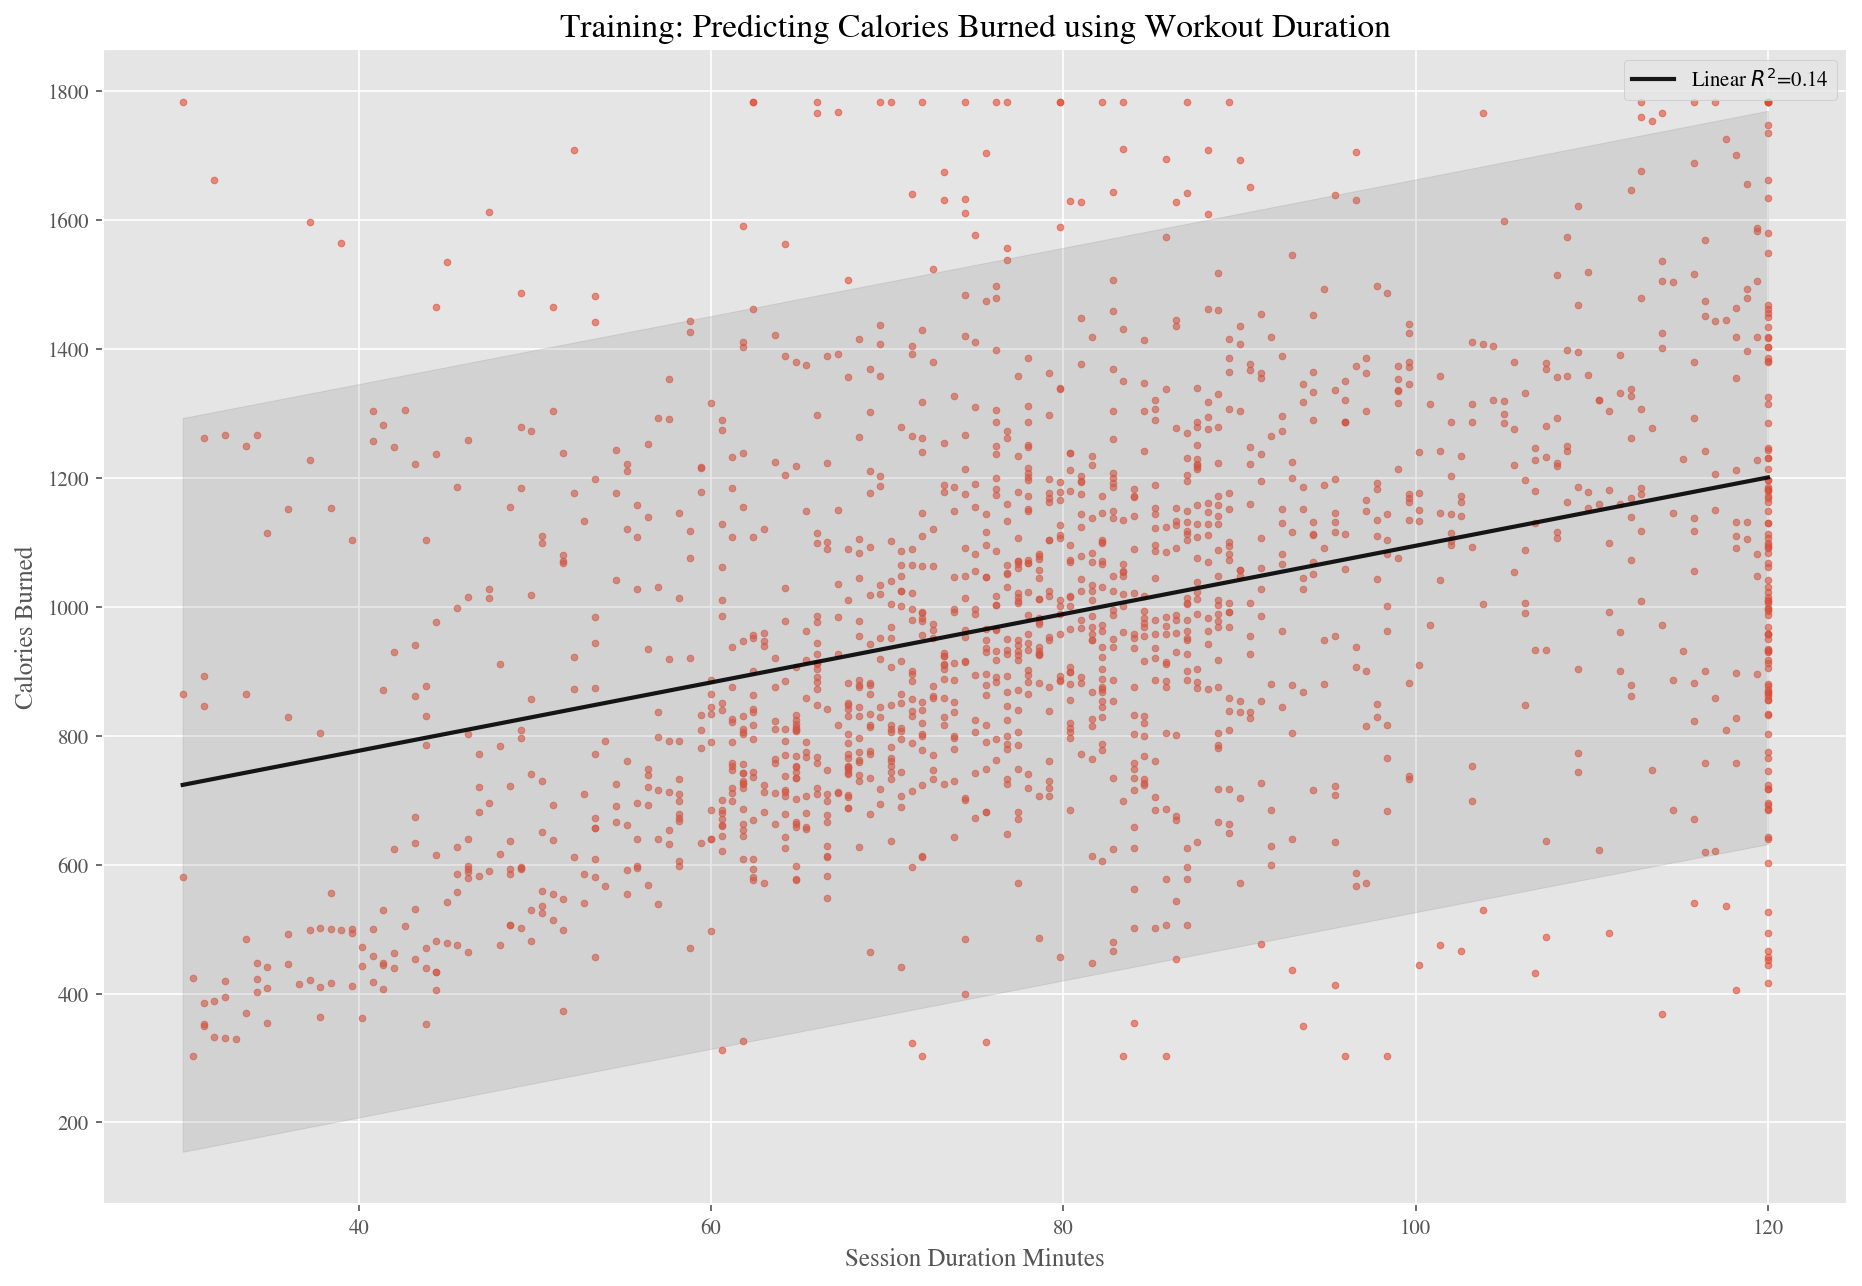

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:        Calories_Burned   R-squared:                       0.137
Model:                            OLS   Adj. R-squared:                  0.137
Method:                 Least Squares   F-statistic:                     257.9
Date:                Tue, 24 Nov 2026   Prob (F-statistic):           5.66e-54
Time:                        10:51:11   Log-Likelihood:                -11502.
No. Observations:                1623   AIC:                         2.301e+04
Df Residuals:                    1621   BIC:                         2.302e+04
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
============================================================================================
                               coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------------
Intercept                  564.6077     27.305     20.678      0.000     511.051     618.165
Session_Duration_Minutes     5.2985      0.330     16.060      0.000       4.651       5.946
==============================================================================
Omnibus:                       42.349   Durbin-Watson:                   2.042
Prob(Omnibus):                  0.000   Jarque-Bera (JB):               46.413
Skew:                           0.369   Prob(JB):                     8.35e-11
Kurtosis:                       3.377   Cond. No.                         314.
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [99]:
x = np.linspace(train_df["Session_Duration_Minutes"].min(),train_df["Session_Duration_Minutes"].max(),len(train_df))
x_rf = pd.DataFrame({"Session_Duration_Minutes": x})
x_pred = sm.add_constant(x_rf)
modRG = smf.ols(formula="Calories_Burned ~ 1 + Session_Duration_Minutes",data=train_df).fit()
sdev, lower, upper = wls_prediction_std(modRG,exog=x_pred,alpha=0.05)
plt.scatter(train_df["Session_Duration_Minutes"],train_df["Calories_Burned"],s=10,alpha=0.6)
plt.fill_between(x,lower,upper,color="#888888",alpha=0.2)
plt.plot( x, modRG.predict(x_rf),"k-",label="Linear $R^2$=%.2f" % modRG.rsquared,alpha=0.9)
plt.xlabel("Session Duration Minutes")
plt.ylabel("Calories Burned")
plt.title("Training: Predicting Calories Burned using Workout Duration", fontsize=16)
plt.legend()
plt.show()
modRG.summary()

The simple linear regression model shows a positive relationship between workout duration and calories burned. The coefficient for Session_Duration_Minutes is about 5.30.

However, the R² value is only 0.137. This means that workout duration alone explains about 13.7% of the variation in calories burned. Therefore, workout duration is useful, but it is not enough by itself. 

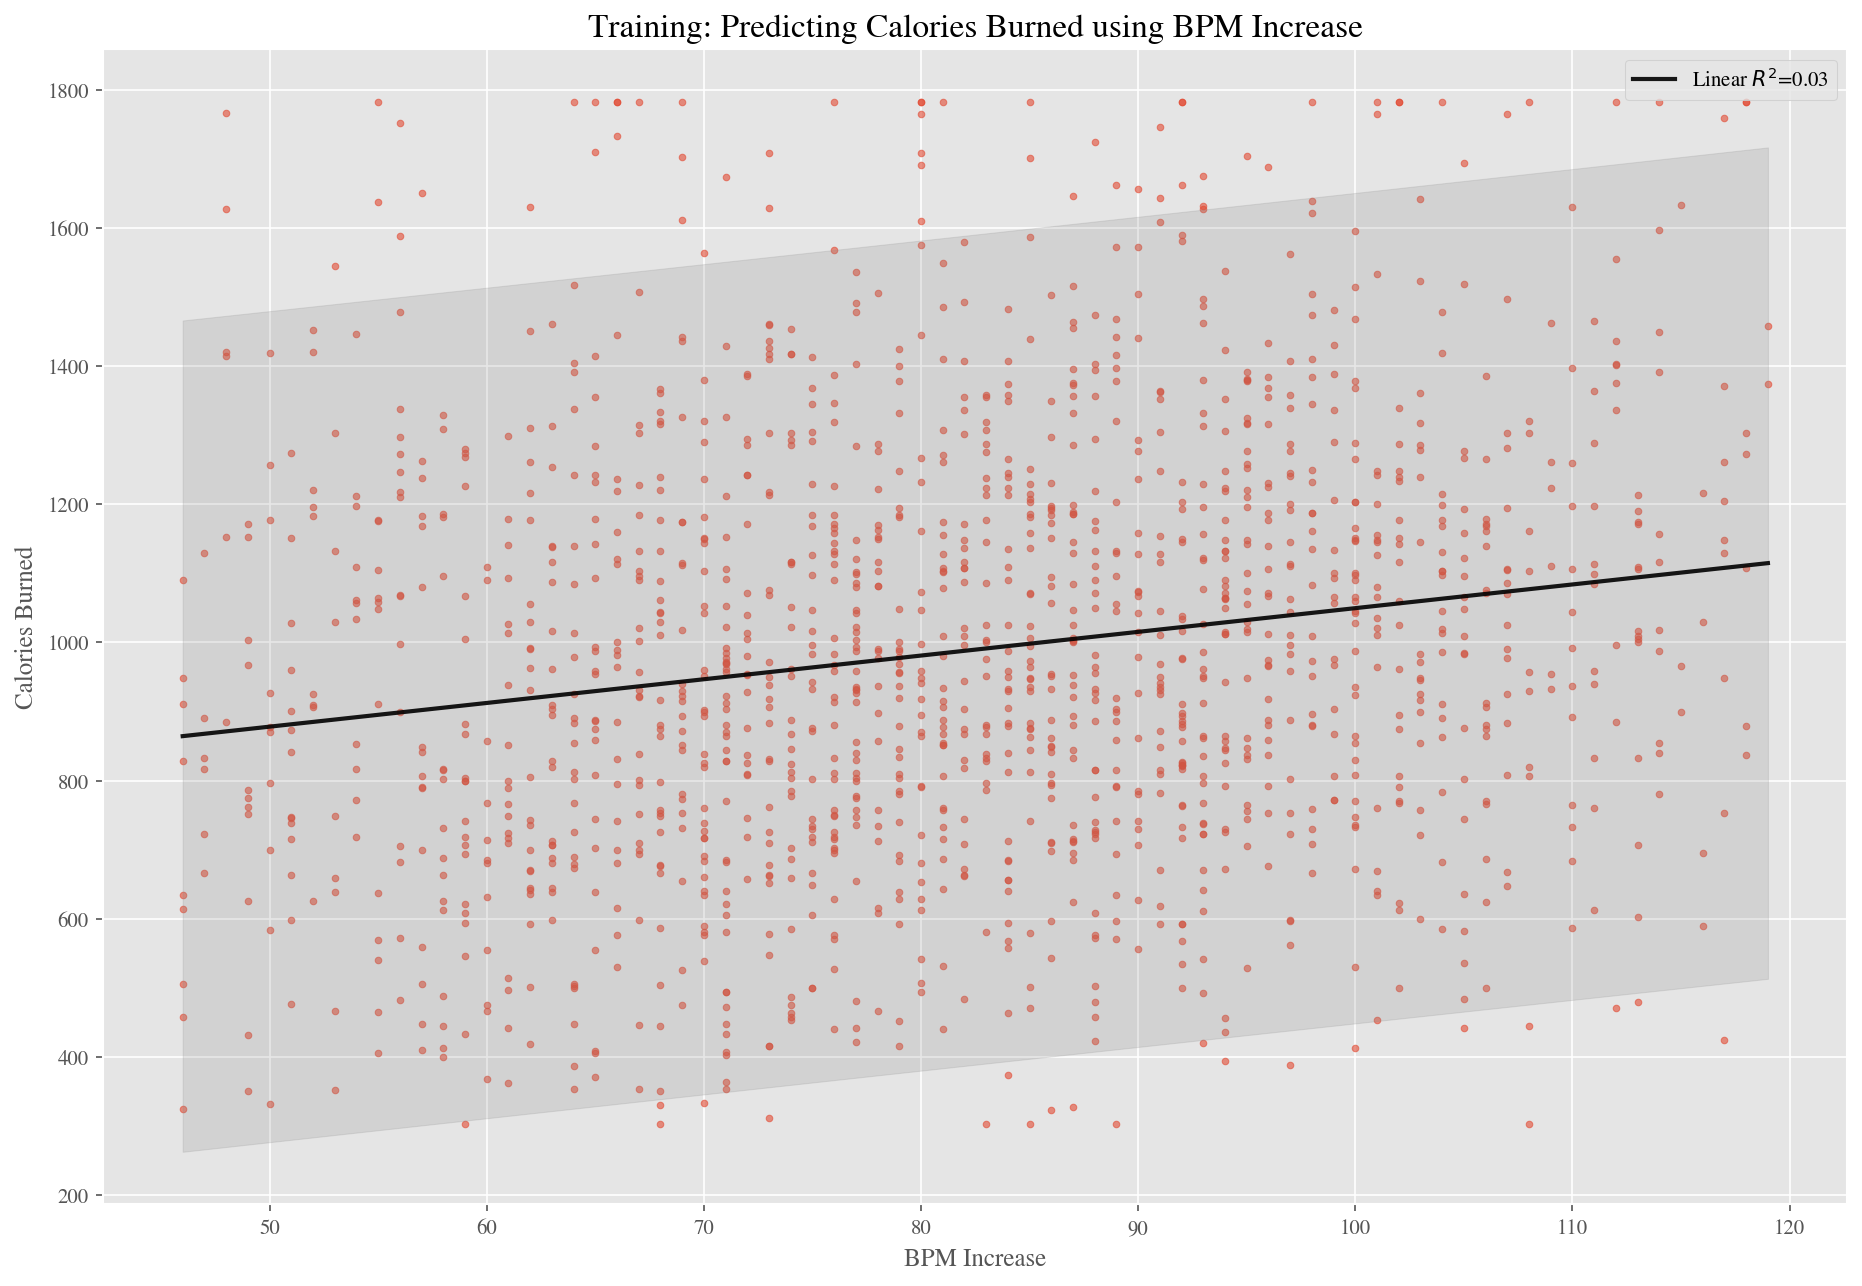

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:        Calories_Burned   R-squared:                       0.034
Model:                            OLS   Adj. R-squared:                  0.034
Method:                 Least Squares   F-statistic:                     57.25
Date:                Tue, 24 Nov 2026   Prob (F-statistic):           6.38e-14
Time:                        10:51:11   Log-Likelihood:                -11593.
No. Observations:                1623   AIC:                         2.319e+04
Df Residuals:                    1621   BIC:                         2.320e+04
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
================================================================================
                   coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------
Intercept      706.4421     37.935     18.622      0.000     632.035     780.850
BPM_Increase     3.4326      0.454      7.567      0.000       2.543       4.322
==============================================================================
Omnibus:                       27.101   Durbin-Watson:                   2.002
Prob(Omnibus):                  0.000   Jarque-Bera (JB):               28.093
Skew:                           0.315   Prob(JB):                     7.94e-07
Kurtosis:                       2.865   Cond. No.                         417.
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [100]:
x = np.linspace(train_df["BPM_Increase"].min(),train_df["BPM_Increase"].max(),len(train_df))
x_rf = pd.DataFrame({"BPM_Increase": x})
x_pred = sm.add_constant(x_rf)
modRG_bpm = smf.ols(formula="Calories_Burned ~ 1 + BPM_Increase",data=train_df).fit()
sdev, lower, upper = wls_prediction_std(modRG_bpm,exog=x_pred,alpha=0.05)
plt.scatter(train_df["BPM_Increase"],train_df["Calories_Burned"],s=10,alpha=0.6)
plt.fill_between(x,lower,upper,color="#888888",alpha=0.2)
plt.plot(x,modRG_bpm.predict(x_rf),"k-",label="Linear $R^2$=%.2f" % modRG_bpm.rsquared,alpha=0.9)
plt.xlabel("BPM Increase")
plt.ylabel("Calories Burned")
plt.title("Training: Predicting Calories Burned using BPM Increase", fontsize=16)
plt.legend()
plt.show()
modRG_bpm.summary()

The regression result shows the coefficient for BPM_Increase is about 3.43.

The R² value is only 0.034, meaning that BPM_Increase alone explains about 3.4% of the variation in calories burned. The p-value is very small and the relationship is statistically significant, but this model has weak predictive power by itself.

Workout duration is a stronger single predictor of calories burned than BPM_Increase in this dataset.

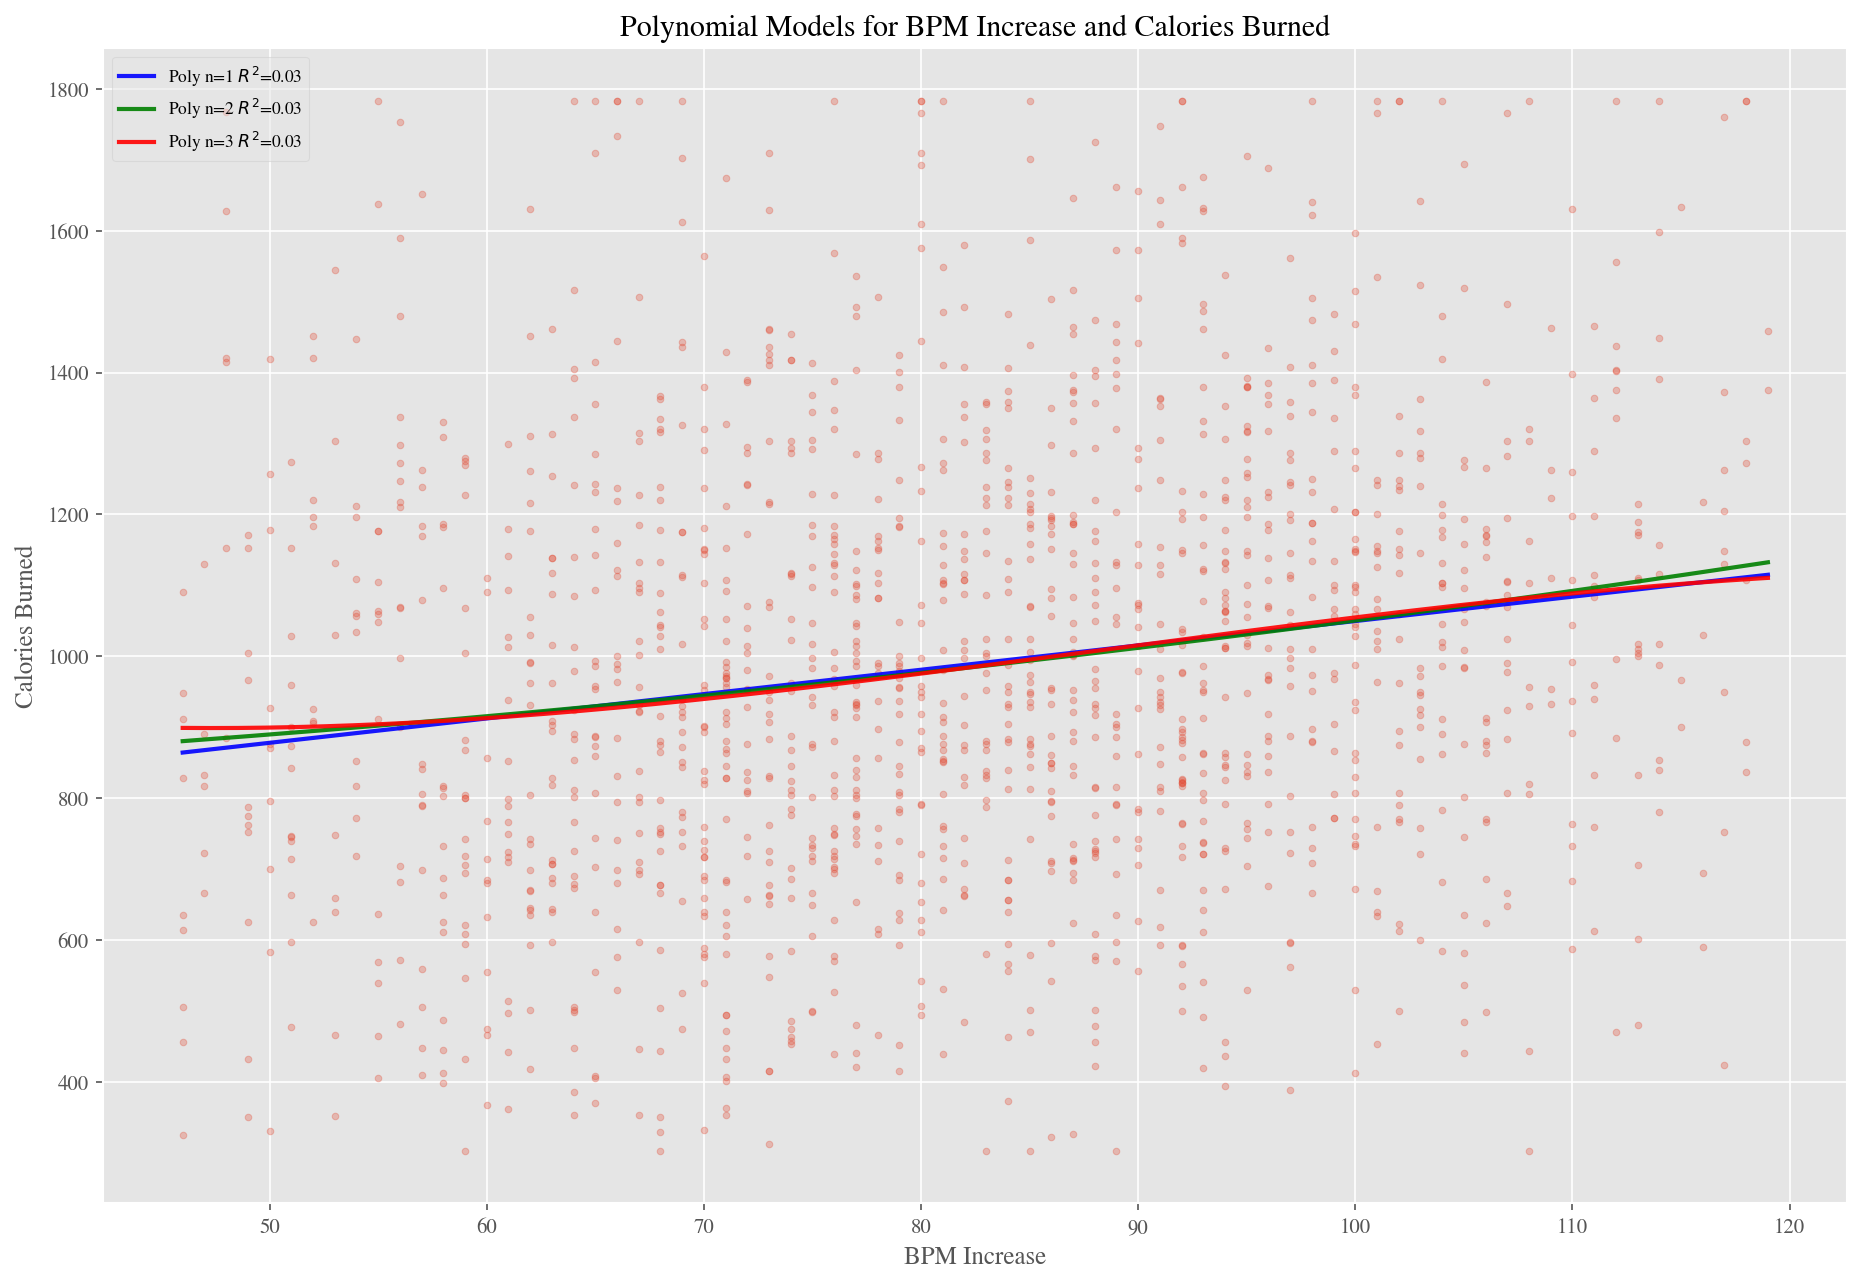

In [101]:
plt.scatter(train_df["BPM_Increase"],train_df["Calories_Burned"],s=10,alpha=0.3)
plt.xlabel("BPM Increase")
plt.ylabel("Calories Burned")
xpoly = pd.DataFrame({"BPM_Increase": np.linspace(train_df["BPM_Increase"].min(),train_df["BPM_Increase"].max(),len(train_df))})

poly_1 = smf.ols(formula="Calories_Burned ~ 1 + BPM_Increase",data=train_df).fit()
plt.plot(xpoly["BPM_Increase"],poly_1.predict(xpoly),"b-",label="Poly n=1 $R^2$=%.2f" % poly_1.rsquared,alpha=0.9)

poly_2 = smf.ols(formula="Calories_Burned ~ 1 + BPM_Increase + I(BPM_Increase ** 2.0)",data=train_df).fit()
plt.plot(xpoly["BPM_Increase"],poly_2.predict(xpoly),"g-",label="Poly n=2 $R^2$=%.2f" % poly_2.rsquared,alpha=0.9)

poly_3 = smf.ols(formula="Calories_Burned ~ 1 + BPM_Increase + I(BPM_Increase ** 2.0) + I(BPM_Increase ** 3.0)",data=train_df).fit()
plt.plot(xpoly["BPM_Increase"],poly_3.predict(xpoly),"r-",label="Poly n=3 $R^2$=%.2f" % poly_3.rsquared,alpha=0.9)

plt.legend(loc="upper left", framealpha=0.5, prop={"size": "small"})
plt.title("Polynomial Models for BPM Increase and Calories Burned")
plt.show()

The polynomial curves are very close to each other. This suggests that BPM_Increase alone does not strongly explain Calories_Burned, even when a non-linear relationship is considered. 

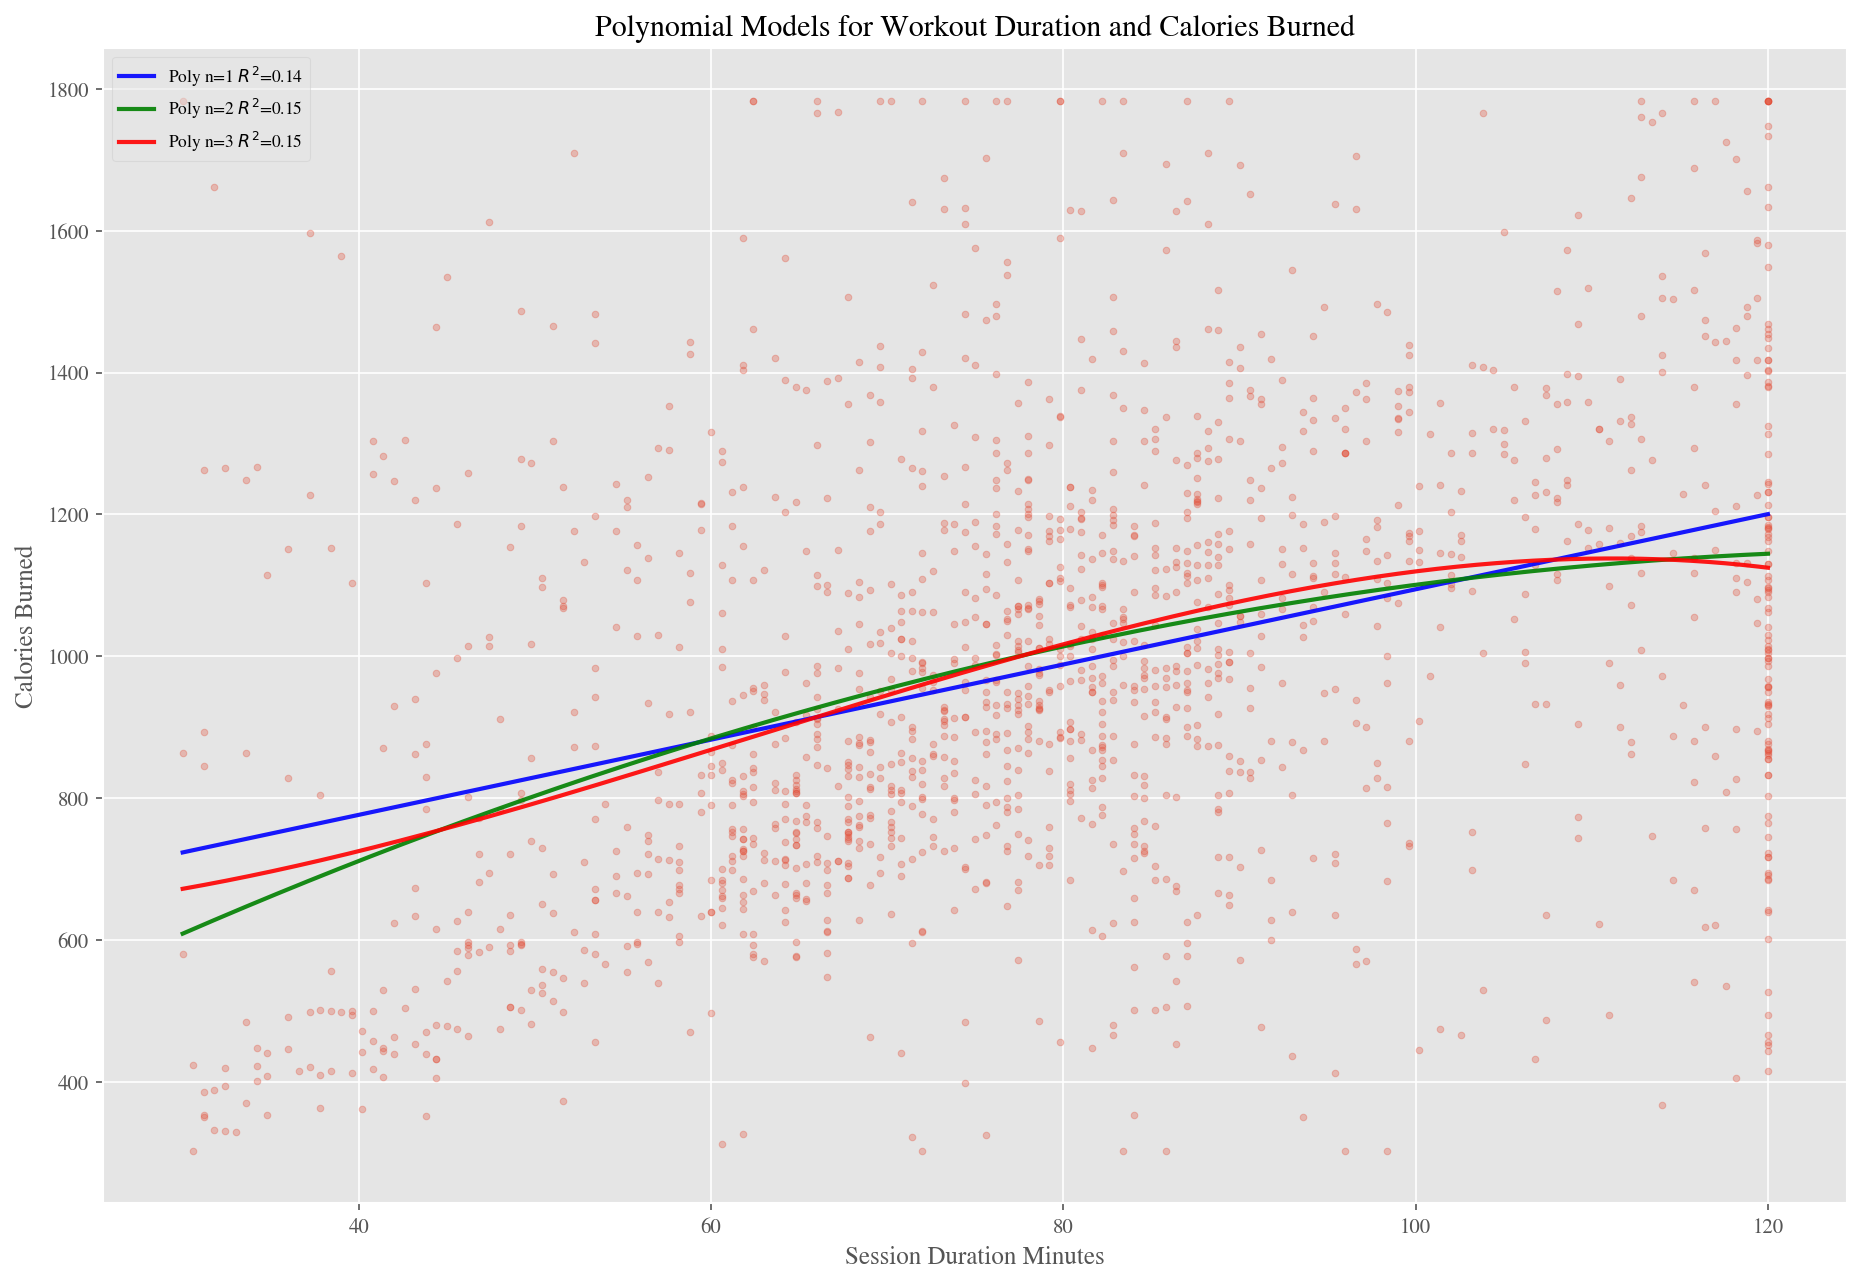

In [102]:
plt.scatter(train_df["Session_Duration_Minutes"],train_df["Calories_Burned"],s=10,alpha=0.3)
plt.xlabel("Session Duration Minutes")
plt.ylabel("Calories Burned")

xpoly = pd.DataFrame({"Session_Duration_Minutes": np.linspace(train_df["Session_Duration_Minutes"].min(),train_df["Session_Duration_Minutes"].max(),len(train_df))})
poly_1 = smf.ols(formula="Calories_Burned ~ 1 + Session_Duration_Minutes",data=train_df).fit()
plt.plot(xpoly["Session_Duration_Minutes"],poly_1.predict(xpoly),"b-",label="Poly n=1 $R^2$=%.2f" % poly_1.rsquared,alpha=0.9)

poly_2 = smf.ols(formula="Calories_Burned ~ 1 + Session_Duration_Minutes + I(Session_Duration_Minutes ** 2.0)",data=train_df).fit()
plt.plot(xpoly["Session_Duration_Minutes"],poly_2.predict(xpoly),"g-",label="Poly n=2 $R^2$=%.2f" % poly_2.rsquared,alpha=0.9)

poly_3 = smf.ols(formula="Calories_Burned ~ 1 + Session_Duration_Minutes + I(Session_Duration_Minutes ** 2.0) + I(Session_Duration_Minutes ** 3.0)",data=train_df).fit()
plt.plot(xpoly["Session_Duration_Minutes"],poly_3.predict(xpoly),"r-",label="Poly n=3 $R^2$=%.2f" % poly_3.rsquared,alpha=0.9)
plt.legend(loc="upper left", framealpha=0.5, prop={"size": "small"})
plt.title("Polynomial Models for Workout Duration and Calories Burned")
plt.show()

The polynomial models show that the degree 2 and degree 3 curves are slightly different from the linear model, but the improvement appears small. This suggests that workout duration is useful for predicting calories burned, but using workout duration alone is still limited. 

In [103]:
y_test_actual = test_df["Calories_Burned"]
y_test_pred_1 = poly_1.predict(test_df[["Session_Duration_Minutes"]])
ss_total = np.sum((y_test_actual - np.mean(y_test_actual)) ** 2)
ss_residual_1 = np.sum((y_test_actual - y_test_pred_1) ** 2)
r2_manual_poly1 = 1 - (ss_residual_1 / ss_total)
rmse_manual_poly1 = np.sqrt(np.mean((y_test_actual - y_test_pred_1) ** 2))
y_test_pred_2 = poly_2.predict(test_df[["Session_Duration_Minutes"]])
ss_residual_2 = np.sum((y_test_actual - y_test_pred_2) ** 2)
r2_manual_poly2 = 1 - (ss_residual_2 / ss_total)
rmse_manual_poly2 = np.sqrt(np.mean((y_test_actual - y_test_pred_2) ** 2))
y_test_pred_3 = poly_3.predict(test_df[["Session_Duration_Minutes"]])
ss_residual_3 = np.sum((y_test_actual - y_test_pred_3) ** 2)
r2_manual_poly3 = 1 - (ss_residual_3 / ss_total)
rmse_manual_poly3 = np.sqrt(np.mean((y_test_actual - y_test_pred_3) ** 2))
print(f"Poly1 - Test R²: {r2_manual_poly1:.3f}, Test RMSE: {rmse_manual_poly1:.3f}")
print(f"Poly2 - Test R²: {r2_manual_poly2:.3f}, Test RMSE: {rmse_manual_poly2:.3f}")
print(f"Poly3 - Test R²: {r2_manual_poly3:.3f}, Test RMSE: {rmse_manual_poly3:.3f}")

Poly1 - Test R²: 0.064, Test RMSE: 292.798
Poly2 - Test R²: 0.077, Test RMSE: 290.785
Poly3 - Test R²: 0.071, Test RMSE: 291.709


Among the three polynomial models, the degree 2 model was the best polynomial model.  It had the highest test R² value and the lowest test RMSE. However, the improvement was small, and the R² values were still low overall.

In [104]:
mod_multi = smf.ols(formula='Calories_Burned ~ 1 + Session_Duration_Minutes+ BPM_Increase + Q("Workout_Frequency (days/week)")+Experience_Level',data=train_df).fit()
mod_multi.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:        Calories_Burned   R-squared:                       0.198
Model:                            OLS   Adj. R-squared:                  0.196
Method:                 Least Squares   F-statistic:                     99.73
Date:                Tue, 24 Nov 2026   Prob (F-statistic):           5.99e-76
Time:                        10:51:12   Log-Likelihood:                -11443.
No. Observations:                1623   AIC:                         2.290e+04
Df Residuals:                    1618   BIC:                         2.292e+04
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
======================================================================================================
                                         coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------------------------
Intercept                            197.8677     46.304      4.273      0.000     107.046     288.690
Session_Duration_Minutes               4.2220      0.340     12.409      0.000       3.555       4.889
BPM_Increase                           3.0807      0.415      7.432      0.000       2.268       3.894
Q("Workout_Frequency (days/week)")    23.8857      8.044      2.970      0.003       8.109      39.663
Experience_Level                      66.1533     10.241      6.459      0.000      46.066      86.241
==============================================================================
Omnibus:                       65.965   Durbin-Watson:                   2.035
Prob(Omnibus):                  0.000   Jarque-Bera (JB):               82.257
Skew:                           0.431   Prob(JB):                     1.37e-18
Kurtosis:                       3.687   Cond. No.                         777.
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [105]:
y_test_predicted_multi = mod_multi.predict(test_df)
ss_total = np.sum((y_test_actual - np.mean(y_test_actual)) ** 2)
ss_residual_multi = np.sum((y_test_actual - y_test_predicted_multi) ** 2)
r2_manual_multi = 1 - (ss_residual_multi / ss_total)
rmse_manual_multi = np.sqrt(np.mean((y_test_actual - y_test_predicted_multi) ** 2))

print(f"Test R² for multiple regression model: {r2_manual_multi:.3f}")
print(f"Test RMSE for multiple regression model: {rmse_manual_multi:.3f}")

Test R² for multiple regression model: 0.122
Test RMSE for multiple regression model: 283.535


The multiple linear regression model was evaluated on the test set. The test R² was 0.122, which means the model explains about 12.2% of the variation in calories burned in the test data. The test RMSE was 283.535, meaning the model's typical prediction error was around 284 calories.

In [106]:
mod_multi = smf.ols(
    formula='Calories_Burned ~ 1 + Session_Duration_Minutes + Avg_BPM + BPM_Increase + MET + BMI + Experience_Level + Q("Workout_Frequency (days/week)")',
    data=train_df).fit()
mod_multi.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:        Calories_Burned   R-squared:                       0.199
Model:                            OLS   Adj. R-squared:                  0.195
Method:                 Least Squares   F-statistic:                     57.29
Date:                Tue, 24 Nov 2026   Prob (F-statistic):           1.65e-73
Time:                        10:51:12   Log-Likelihood:                -11441.
No. Observations:                1623   AIC:                         2.290e+04
Df Residuals:                    1615   BIC:                         2.294e+04
Df Model:                           7                                         
Covariance Type:            nonrobust                                         
======================================================================================================
                                         coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------------------------
Intercept                             96.7603     98.555      0.982      0.326     -96.549     290.070
Session_Duration_Minutes               4.2115      0.341     12.368      0.000       3.544       4.879
Avg_BPM                                1.4512      1.017      1.427      0.154      -0.544       3.446
BPM_Increase                           1.9438      0.903      2.152      0.032       0.172       3.715
MET                                   -0.9763      3.421     -0.285      0.775      -7.687       5.735
BMI                                   -0.3591      0.945     -0.380      0.704      -2.212       1.494
Experience_Level                      66.1927     10.245      6.461      0.000      46.098      86.287
Q("Workout_Frequency (days/week)")    23.4618      8.052      2.914      0.004       7.668      39.255
==============================================================================
Omnibus:                       66.939   Durbin-Watson:                   2.039
Prob(Omnibus):                  0.000   Jarque-Bera (JB):               84.540
Skew:                           0.431   Prob(JB):                     4.39e-19
Kurtosis:                       3.712   Cond. No.                     2.67e+03
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
[2] The condition number is large, 2.67e+03. This might indicate that there are
strong multicollinearity or other numerical problems.
"""

In [107]:
y_test_predicted_multi = mod_multi.predict(test_df)
ss_total = np.sum((y_test_actual - np.mean(y_test_actual)) ** 2)
ss_residual_multi = np.sum((y_test_actual - y_test_predicted_multi) ** 2)
r2_manual_multi = 1 - (ss_residual_multi / ss_total)
rmse_manual_multi = np.sqrt(np.mean((y_test_actual - y_test_predicted_multi) ** 2))

print(f"Test R² for multiple regression model: {r2_manual_multi:.3f}")
print(f"Test RMSE for multiple regression model: {rmse_manual_multi:.3f}")

Test R² for multiple regression model: 0.123
Test RMSE for multiple regression model: 283.401


The test R² was 0.123 and the test RMSE was 283.401. This is only a small improvement compared with the previous multiple regression model.

## 8.2 kNN Regression

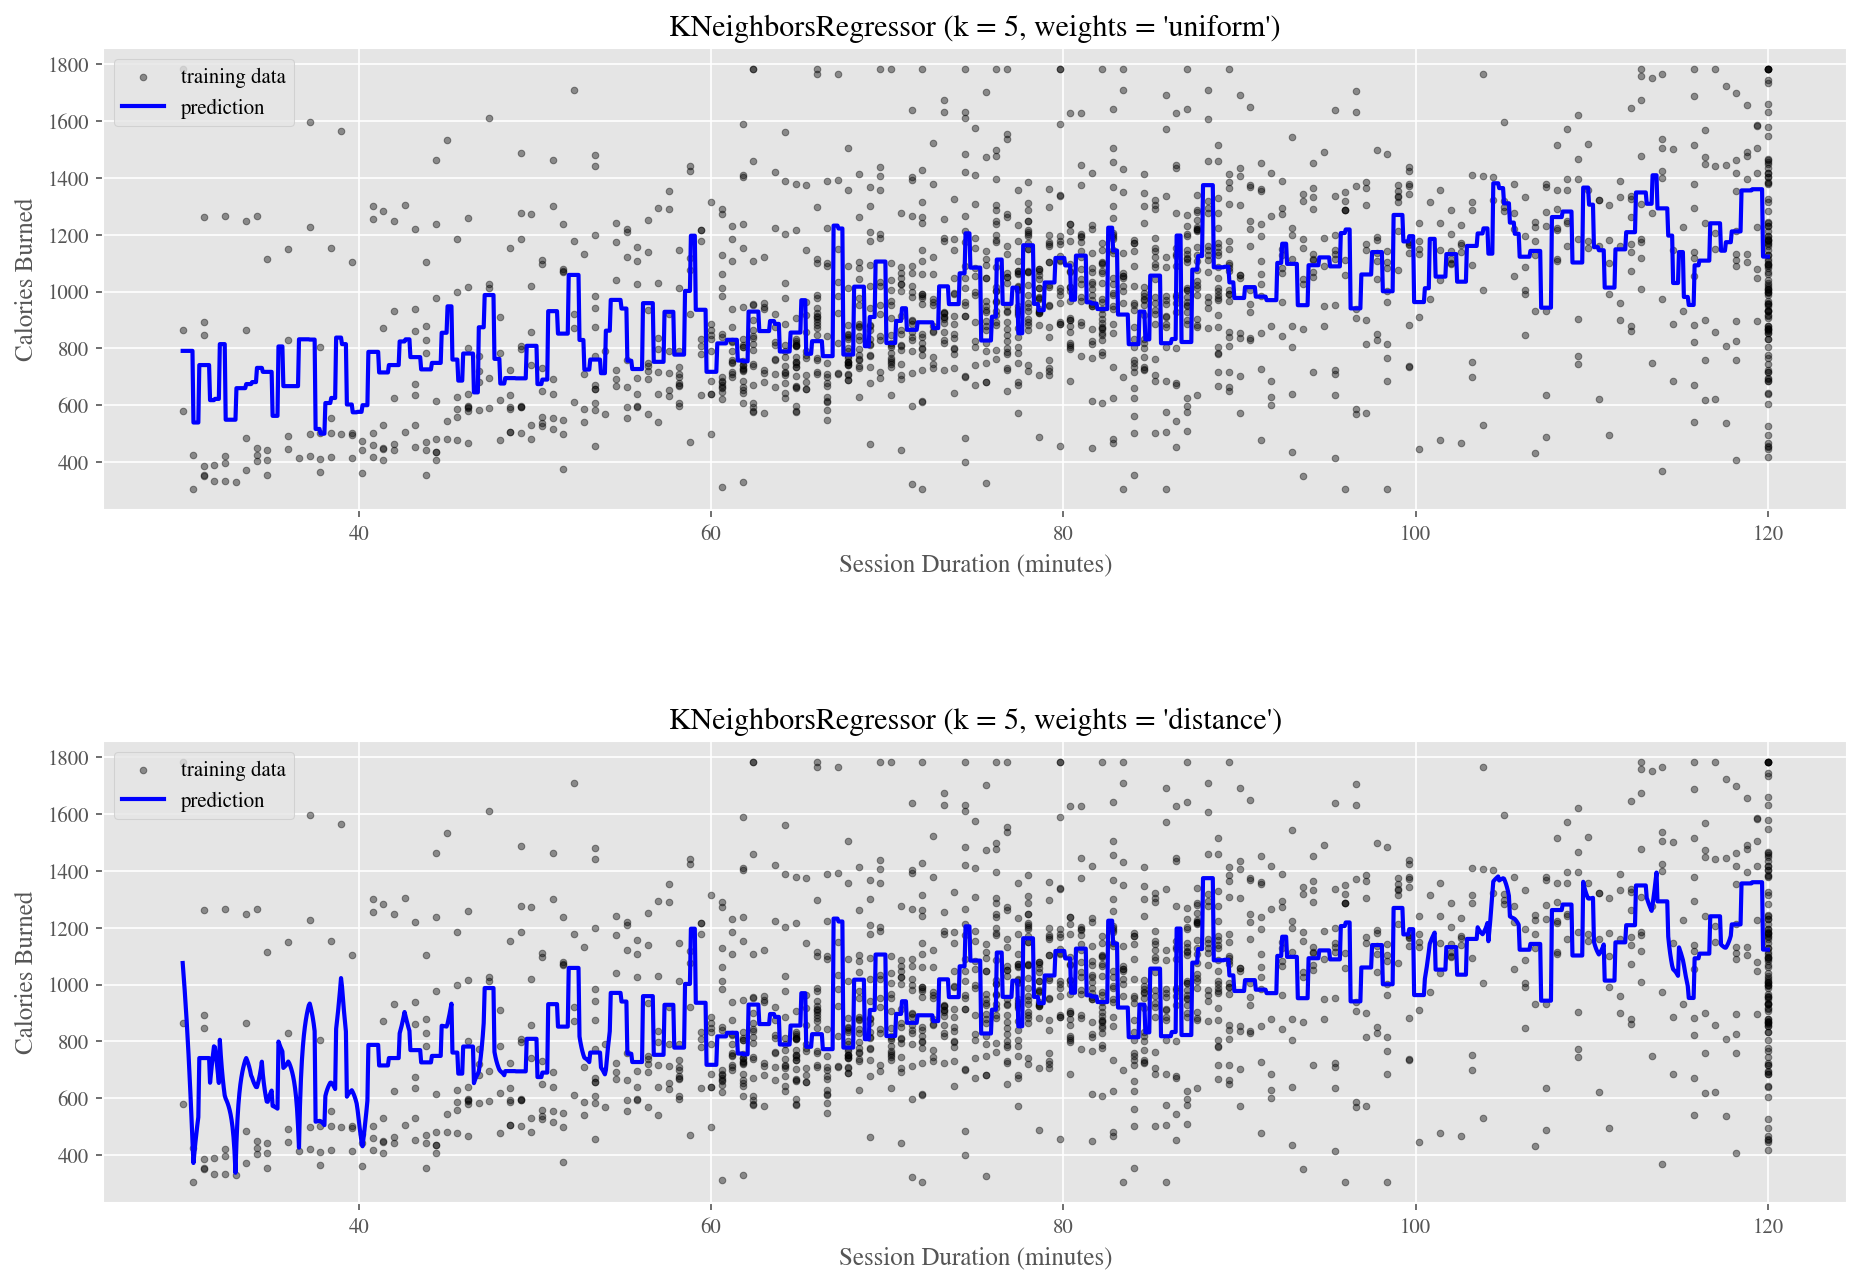

In [108]:
Xknn = train_df["Session_Duration_Minutes"].values
Xknn = np.reshape(Xknn, (len(train_df["Session_Duration_Minutes"]), 1))
yknn = train_df["Calories_Burned"].values
yknn = np.reshape(yknn, (len(train_df["Calories_Burned"]), 1))
xknn = np.linspace(train_df["Session_Duration_Minutes"].min(),train_df["Session_Duration_Minutes"].max(),len(train_df))[:, np.newaxis]
n_neighbors = 5
for i, weights in enumerate(["uniform", "distance"]):
    knn = neighbors.KNeighborsRegressor(n_neighbors=n_neighbors,weights=weights)
    y_hat = knn.fit(Xknn, yknn).predict(xknn)
    plt.subplot(2, 1, i + 1)
    plt.scatter(Xknn,yknn,c="k",s=10,alpha=0.4,label="training data")
    plt.plot(xknn,y_hat,c="b",label="prediction")
    plt.axis("tight")
    plt.xlabel("Session Duration (minutes)")
    plt.ylabel("Calories Burned")
    plt.legend(loc="upper left")
    plt.title("KNeighborsRegressor (k = %i, weights = '%s')" % (n_neighbors, weights))
plt.subplots_adjust(hspace=0.5)
plt.show()

In [109]:
rsquare_arr = []
rmse_arr = []
k_arr = []

X_train_knn = train_df[["Session_Duration_Minutes"]]
y_train_knn = train_df["Calories_Burned"]

X_test_knn = test_df[["Session_Duration_Minutes"]]
y_test_knn = test_df["Calories_Burned"]

for k in range(2, 30):
    knn = neighbors.KNeighborsRegressor(n_neighbors=k)
    y_hat = knn.fit(X_train_knn, y_train_knn).predict(X_test_knn)
    ss_total = np.sum((y_test_knn - np.mean(y_test_knn)) ** 2)
    ss_residual = np.sum((y_test_knn - y_hat) ** 2)
    
    rsquare = 1 - (ss_residual / ss_total)
    rmse = np.sqrt(np.mean((y_test_knn - y_hat) ** 2))
    k_arr.append(k)
    rsquare_arr.append(rsquare)
    rmse_arr.append(rmse)
knn_single_results = pd.DataFrame({
    "k": k_arr,
    "Test_R2": rsquare_arr,
    "Test_RMSE": rmse_arr
}).round(3)
knn_single_results.sort_values("Test_RMSE")

,k,Test_R2,Test_RMSE
24,26,0.055,294.243
23,25,0.053,294.549
27,29,0.053,294.561
26,28,0.052,294.717
25,27,0.051,294.845
22,24,0.049,295.137
21,23,0.043,296.006
20,22,0.039,296.684
18,20,0.038,296.830
19,21,0.036,297.118


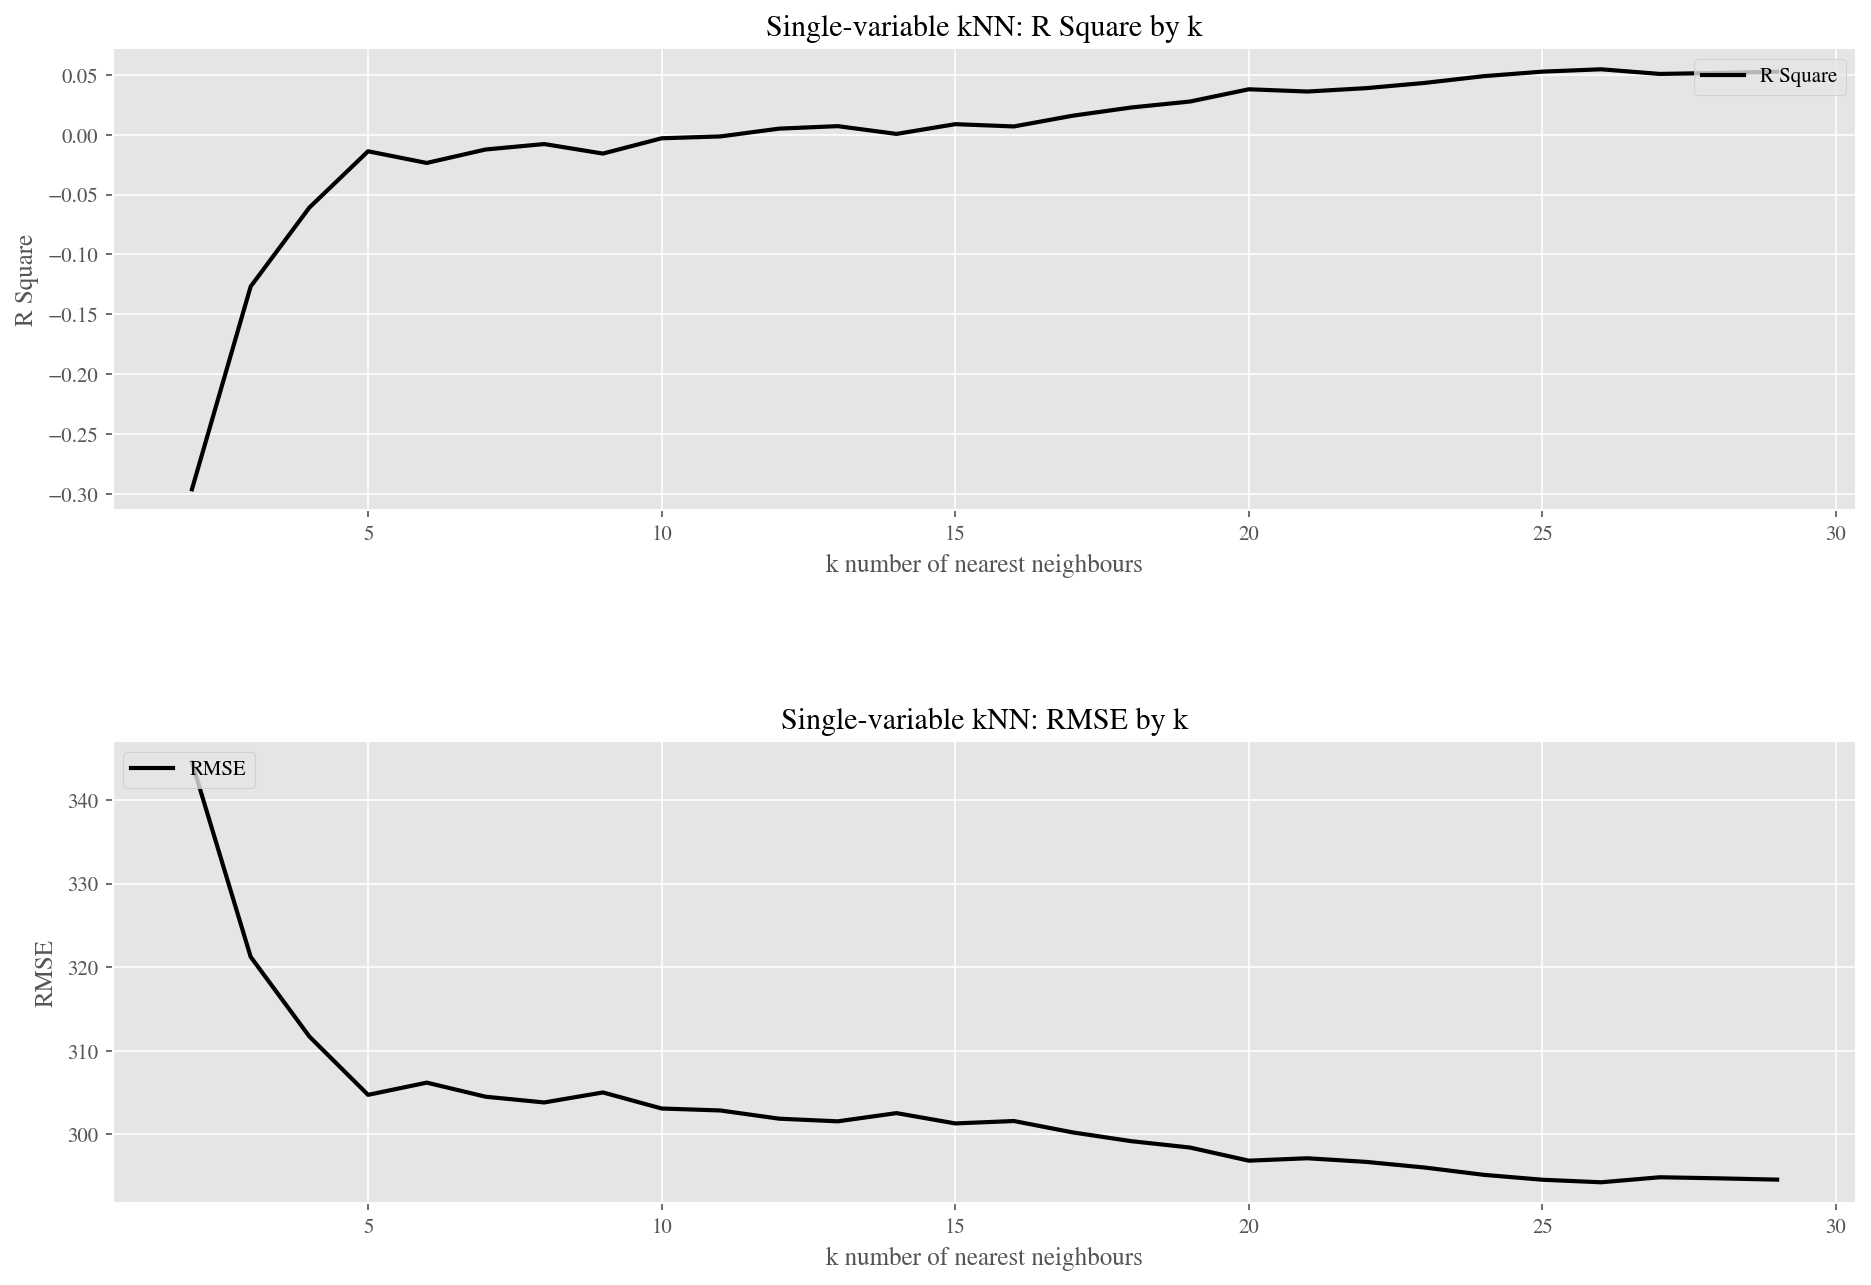

In [110]:
plt.subplot(2, 1, 1)
plt.plot(range(2, 30), rsquare_arr, c="k", label="R Square")
plt.axis("tight")
plt.xlabel("k number of nearest neighbours")
plt.ylabel("R Square")
plt.legend(loc="upper right")
plt.title("Single-variable kNN: R Square by k")
plt.subplots_adjust(hspace=0.5)

plt.subplot(2, 1, 2)
plt.plot(range(2, 30), rmse_arr, c="k", label="RMSE")
plt.axis("tight")
plt.xlabel("k number of nearest neighbours")
plt.ylabel("RMSE")
plt.legend(loc="upper left")
plt.title("Single-variable kNN: RMSE by k")

plt.show()

The single-variable kNN model using only Session_Duration_Minutes as the input feature. The best result was achieved when k = 26, with a Test R² of 0.055 and a Test RMSE of 294.243.

This result shows that using workout duration alone is not enough for accurate calorie burn prediction. Therefore, a multi-variable kNN model was built later using more physical and workout-related features.

In [111]:
numeric_features = [
    "Age",
    "Weight (kg)",
    "Height (m)",
    "BMI",
    "Max_BPM",
    "Avg_BPM",
    "Session_Duration_Minutes",
    "Fat_Percentage",
    "Workout_Frequency (days/week)",
    "Experience_Level",
    "BPM_Increase",
    "MET"
]

X_train = train_df[numeric_features]
y_train = train_df["Calories_Burned"]

X_test = test_df[numeric_features]
y_test = test_df["Calories_Burned"]

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

rsquare_arr = []
rmse_arr = []
k_arr = []

for k in range(2, 30):
    knn = KNeighborsRegressor(n_neighbors=k,weights="distance")
    y_hat = knn.fit(X_train_scaled, y_train).predict(X_test_scaled)
    
    ss_total = np.sum((y_test - np.mean(y_test)) ** 2)
    ss_residual = np.sum((y_test - y_hat) ** 2)
    
    rsquare = 1 - (ss_residual / ss_total)
    rmse = np.sqrt(np.mean((y_test - y_hat) ** 2))
    
    k_arr.append(k)
    rsquare_arr.append(rsquare)
    rmse_arr.append(rmse)

knn_numeric_results = pd.DataFrame({
    "k": k_arr,
    "Test_R2": rsquare_arr,
    "Test_RMSE": rmse_arr
}).round(3)

knn_numeric_results.sort_values("Test_RMSE")

,k,Test_R2,Test_RMSE
24,26,0.172,275.363
26,28,0.172,275.408
25,27,0.171,275.512
23,25,0.171,275.513
27,29,0.170,275.679
22,24,0.168,275.982
21,23,0.168,276.071
20,22,0.167,276.155
19,21,0.164,276.666
18,20,0.164,276.749


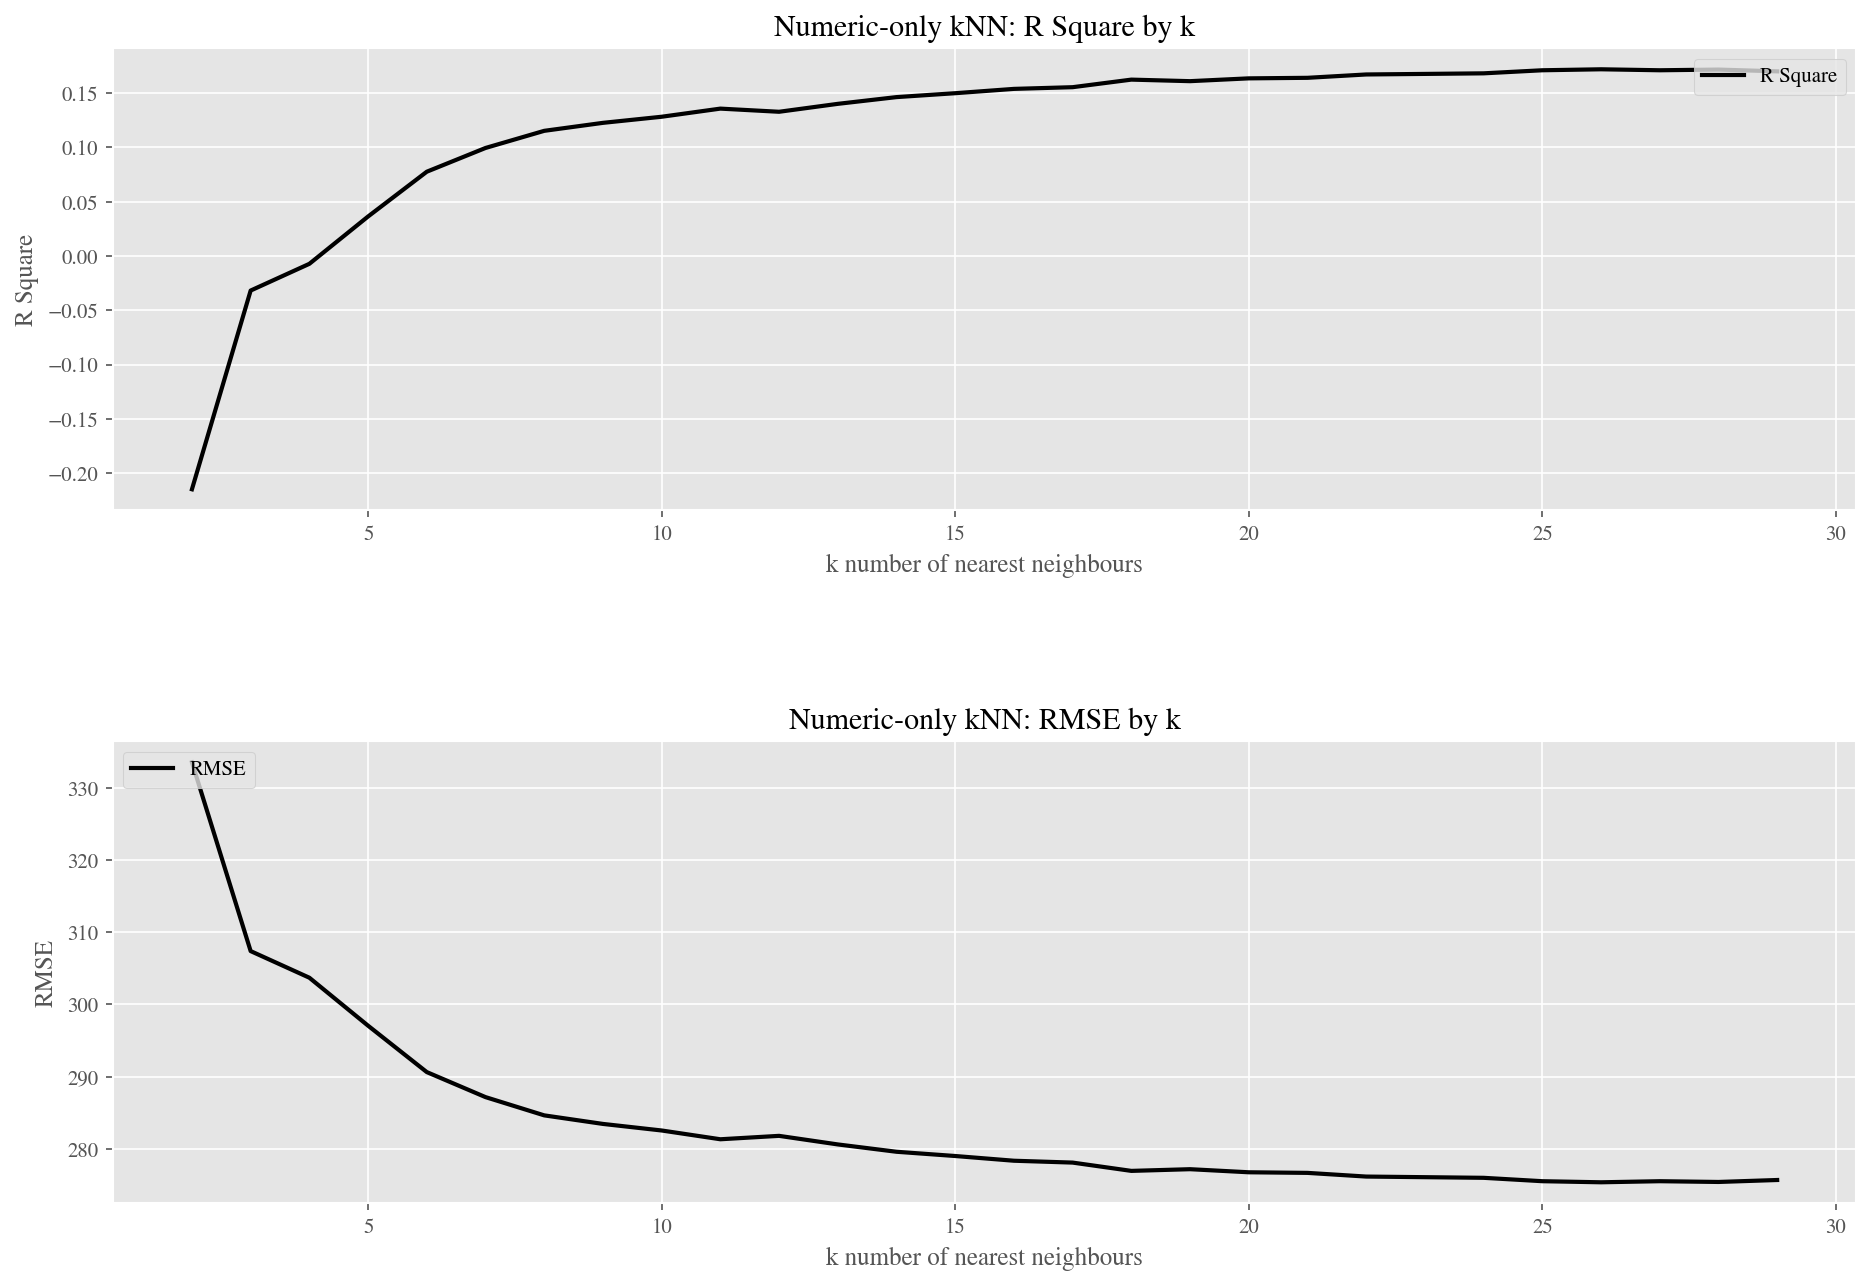

In [112]:
plt.subplot(2, 1, 1)
plt.plot(k_arr,rsquare_arr,c="k",label="R Square")
plt.axis("tight")
plt.xlabel("k number of nearest neighbours")
plt.ylabel("R Square")
plt.legend(loc="upper right")
plt.title("Numeric-only kNN: R Square by k")
plt.subplots_adjust(hspace=0.5)

plt.subplot(2, 1, 2)
plt.plot(k_arr,rmse_arr,c="k",label="RMSE")
plt.axis("tight")
plt.xlabel("k number of nearest neighbours")
plt.ylabel("RMSE")
plt.legend(loc="upper left")
plt.title("Numeric-only kNN: RMSE by k")

plt.show()

The best result was achieved when k = 26, with a Test R² of 0.172 and a Test RMSE of 275.363. This shows that using multiple physical and workout-related features improves calorie burn prediction compared with using workout duration alone.

## 8.3 Random Forest Regression

In [113]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
numeric_features = [
    "Age",
    "Weight (kg)",
    "Height (m)",
    "BMI",
    "Max_BPM",
    "Avg_BPM",
    "Session_Duration_Minutes",
    "Fat_Percentage",
    "Workout_Frequency (days/week)",
    "Experience_Level",
    "BPM_Increase",
    "MET",
    "Gender_Female",
    "Gender_Male",
    "Workout_Type_Cardio",
    "Workout_Type_HIIT",
    "Workout_Type_Strength",
    "Workout_Type_Yoga"
]

X_train = train_df[numeric_features]
y_train = train_df["Calories_Burned"]

X_test = test_df[numeric_features]
y_test = test_df["Calories_Burned"]

rf_model = RandomForestRegressor(n_estimators=200,random_state=42)

rf_model.fit(X_train, y_train)

rf_pred = rf_model.predict(X_test)

rf_r2 = r2_score(y_test, rf_pred)
rf_rmse = mean_squared_error(y_test, rf_pred) ** 0.5
rf_mae = mean_absolute_error(y_test, rf_pred)

print("Random Forest R²:", round(rf_r2, 3))
print("Random Forest RMSE:", round(rf_rmse, 3))
print("Random Forest MAE:", round(rf_mae, 3))

Random Forest R²: 0.182
Random Forest RMSE: 273.737
Random Forest MAE: 195.005


The Random Forest model achieved a Test R² of 0.182, a Test RMSE of 273.737. Compared with the multiple linear regression and kNN regression models, Random Forest had the highest Test R² and the lowest Test RMSE. Therefore, Random Forest Regression was selected as the final calorie burn prediction model for the app prototype.
However, the R² value is still not very high.

## 8.4 Model Comparison

In [114]:
model_comparison = pd.DataFrame({
    "Model": [
        "Polynomial Regression Degree 2",
        "Multiple Linear Regression",
        "kNN Regression",
        "Random Forest Regression"
    ],
    "R2": [
        r2_manual_poly2,
        r2_manual_multi,
        knn_numeric_results.sort_values("Test_RMSE").iloc[0]["Test_R2"],
        rf_r2
    ],
    "RMSE": [
        rmse_manual_poly2,
        rmse_manual_multi,
        knn_numeric_results.sort_values("Test_RMSE").iloc[0]["Test_RMSE"],
        rf_rmse
    ]
}).round(2)

model_comparison.sort_values("RMSE")

,Model,R2,RMSE
3,Random Forest Regression,0.18,273.74
2,kNN Regression,0.17,275.36
1,Multiple Linear Regression,0.12,283.40
0,Polynomial Regression Degree 2,0.08,290.79


Although Random Forest achieved the best performance among the tested models, the Test R² value was still relatively low. Therefore, the calorie prediction should be interpreted as an approximate estimate.

# 9. Fitness Profile Clustering

In [115]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn import metrics

In [116]:
cluster_features = [
    "Age",
    "Weight (kg)",
    "BMI",
    "Avg_BPM",
    "Session_Duration_Minutes",
    "Calories_Burned",
    "Workout_Frequency (days/week)",
    "Experience_Level",
    "BPM_Increase",
    "MET"
]

X_cluster = gym_df[cluster_features]
scaler = StandardScaler()
X_cluster_scaled = scaler.fit_transform(X_cluster)
k_values = range(2, 8)

silhouette_scores = []
davies_bouldin_scores = []
calinski_harabasz_scores = []
for k in k_values:
    kmeans = KMeans(n_clusters=k,random_state=42,n_init=10)
    cluster_labels = kmeans.fit_predict(X_cluster_scaled)
    silhouette_scores.append(metrics.silhouette_score(X_cluster_scaled, cluster_labels))
    davies_bouldin_scores.append(metrics.davies_bouldin_score(X_cluster_scaled, cluster_labels))
    calinski_harabasz_scores.append(metrics.calinski_harabasz_score(X_cluster_scaled, cluster_labels))

cluster_results = pd.DataFrame({
    "k": list(k_values),
    "Silhouette_Score": silhouette_scores,
    "Davies_Bouldin_Score": davies_bouldin_scores,
    "Calinski_Harabasz_Score": calinski_harabasz_scores
}).round(2)

cluster_results

,k,Silhouette_Score,Davies_Bouldin_Score,Calinski_Harabasz_Score
0,2,0.14,2.36,392.66
1,3,0.13,2.05,358.10
2,4,0.13,1.88,332.69
3,5,0.11,1.97,292.55
4,6,0.12,2.03,264.15
5,7,0.11,2.10,245.08


k = 2 was selected as the final number of clusters. This is because k = 2 had the highest Silhouette Score and the highest Calinski-Harabasz Score.
Therefore, the final KMeans model used 2 clusters to create two broad fitness profiles. But he Silhouette Score was not very high, so the clusters rather than very clearly separated groups.

In [117]:
final_kmeans = KMeans(
    n_clusters=2,
    random_state=42,
    n_init=10
)
gym_df["Fitness_Profile"] = final_kmeans.fit_predict(X_cluster_scaled)
gym_df[cluster_features + ["Fitness_Profile"]].head()

,Age,Weight (kg),BMI,Avg_BPM,Session_Duration_Minutes,Calories_Burned,Workout_Frequency (days/week),Experience_Level,BPM_Increase,MET,Fitness_Profile
0,56.0,88.3,30.20,157.0,101.4,1313.0,4.0,3.0,97.0,3.0,0
1,46.0,74.9,32.00,151.0,78.0,883.0,4.0,2.0,85.0,8.5,0
2,32.0,68.1,24.71,122.0,66.6,677.0,4.0,2.0,68.0,7.0,1
3,25.0,53.2,18.41,164.0,35.4,532.0,3.0,1.0,108.0,5.0,0
4,38.0,46.1,14.39,158.0,38.4,556.0,3.0,1.0,90.0,5.0,0


In [118]:
profile_summary = gym_df.groupby("Fitness_Profile")[cluster_features].mean().round(2)
profile_summary

,Age,Weight (kg),BMI,Avg_BPM,Session_Duration_Minutes,Calories_Burned,Workout_Frequency (days/week),Experience_Level,BPM_Increase,MET
Fitness_Profile,,,,,,,,,,
0,36.09,71.39,24.10,158.02,82.90,1057.01,3.42,1.87,95.86,5.72
1,36.48,69.29,23.29,132.77,77.38,907.82,3.26,1.77,68.62,5.91


In [119]:
profile_names = {
    0: "High Intensity Fitness Profile",
    1: "Moderate Fitness Profile"
}

gym_df["Fitness_Profile_Name"] = gym_df["Fitness_Profile"].map(profile_names)
profile_counts = gym_df["Fitness_Profile_Name"].value_counts()
profile_counts

Fitness_Profile_Name
Moderate Fitness Profile          1184
High Intensity Fitness Profile    1135
Name: count, dtype: int64

The KMeans clustering result selected 2 clusters
Fitness Profile 0 can be interpreted as a High Intensity Fitness Profile. This group has a higher average heart rate, longer workout duration, higher calories burned and a larger BPM increase. This suggests that users in this profile generally perform more intense workout sessions.

Fitness Profile 1 can be interpreted as a Moderate Fitness Profile. This group has a lower average heart rate, slightly shorter workout duration, lower calories burned and a smaller BPM increase. This suggests that users in this profile generally perform less intense or more moderate workout sessions.

# 10. Rule-Based Meal Recommendation System

In [120]:
def burn_level(calories):
    if calories < 700:
        return "Low Burn"
    elif calories < 1100:
        return "Medium Burn"
    else:
        return "High Burn"

gym_df["Burn_Level"] = gym_df["Calories_Burned"].apply(burn_level)
gym_df[["Calories_Burned", "Burn_Level"]].head()

,Calories_Burned,Burn_Level
0,1313.0,High Burn
1,883.0,Medium Burn
2,677.0,Low Burn
3,532.0,Low Burn
4,556.0,Low Burn


Fitness_Profile based on several physical and workout-related variables, so it represents the user's overall workout pattern. Burn_Level was created using a simple rule based only on Calories_Burned, so it represents the calorie burn level of a workout.
In the meal recommendation system, both features are used together.  Combining these two features makes the recommendation more personalised.

In [121]:
meal_df = pd.read_csv("data/healthy_eating_dataset.csv")
meal_df.head()
meal_df.columns

Index(['meal_id', 'meal_name', 'cuisine', 'meal_type', 'diet_type', 'calories',
       'protein_g', 'carbs_g', 'fat_g', 'fiber_g', 'sugar_g', 'sodium_mg',
       'cholesterol_mg', 'serving_size_g', 'cooking_method', 'prep_time_min',
       'cook_time_min', 'rating', 'is_healthy', 'image_url'],
      dtype='object')

In [122]:
text_cols = [
    "meal_name",
    "cuisine",
    "meal_type",
    "diet_type",
    "cooking_method"
]
for col in text_cols:
    if col in meal_df.columns:
        meal_df[col] = meal_df[col].astype(str).str.strip()

numeric_cols = [
    "calories",
    "protein_g",
    "carbs_g",
    "fat_g",
    "fiber_g",
    "sugar_g",
    "sodium_mg",
    "cholesterol_mg",
    "serving_size_g"
]
for col in numeric_cols:
    meal_df[col] = pd.to_numeric(meal_df[col], errors="coerce")
meal_df = meal_df.dropna()
meal_df = meal_df[meal_df["calories"] > 0]
meal_df = meal_df[meal_df["is_healthy"] == 1]
print(meal_df.shape)
meal_df.head()

(187, 20)


,meal_id,meal_name,cuisine,meal_type,diet_type,calories,protein_g,carbs_g,fat_g,fiber_g,sugar_g,sodium_mg,cholesterol_mg,serving_size_g,cooking_method,prep_time_min,cook_time_min,rating,is_healthy,image_url
5,6,Arm Stew,Italian,Dinner,Balanced,484,55.3,130.3,0.1,29.7,1.6,411,162,209,Steamed,56,112,1.6,1,https://example.com/images/meal_6.jpg
6,7,Item Rice,Thai,Snack,Keto,114,60.9,6.7,6.7,23.4,8.3,1107,60,291,Roasted,41,90,2.8,1,https://example.com/images/meal_7.jpg
21,22,Despite Rice,Italian,Snack,Keto,578,33.5,135.3,7.4,10.6,18.7,1156,110,484,Fried,53,12,3.7,1,https://example.com/images/meal_22.jpg
31,32,Ready Rice,Thai,Dinner,Vegan,333,78.2,130.0,16.6,0.3,19.0,2416,167,220,Roasted,9,94,1.6,1,https://example.com/images/meal_32.jpg
35,36,Which Soup,Indian,Snack,Paleo,249,79.5,91.2,11.3,29.4,3.5,2354,120,376,Boiled,47,29,2.5,1,https://example.com/images/meal_36.jpg


In [123]:
def meal_category(row):
    if row["calories"] < 350:
        return "Light Meal"
    elif row["calories"] < 650:
        return "Balanced Meal"
    else:
        return "High Energy Meal"
meal_df["Meal_Category"] = meal_df.apply(meal_category, axis=1)
meal_keep = [
    "meal_name",
    "cuisine",
    "meal_type",
    "diet_type",
    "calories",
    "protein_g",
    "carbs_g",
    "fat_g",
    "fiber_g",
    "Meal_Category"
]
meal_df = meal_df[meal_keep]
meal_df.head()

,meal_name,cuisine,meal_type,diet_type,calories,protein_g,carbs_g,fat_g,fiber_g,Meal_Category
5,Arm Stew,Italian,Dinner,Balanced,484,55.3,130.3,0.1,29.7,Balanced Meal
6,Item Rice,Thai,Snack,Keto,114,60.9,6.7,6.7,23.4,Light Meal
21,Despite Rice,Italian,Snack,Keto,578,33.5,135.3,7.4,10.6,Balanced Meal
31,Ready Rice,Thai,Dinner,Vegan,333,78.2,130.0,16.6,0.3,Light Meal
35,Which Soup,Indian,Snack,Paleo,249,79.5,91.2,11.3,29.4,Light Meal


In [124]:
recommendation_map = {
    "Low Burn": ["Light Meal"],
    "Medium Burn": ["Balanced Meal"],
    "High Burn": ["Balanced Meal", "High Energy Meal"]
}
profile_meal_map = {
    "High Intensity Fitness Profile": ["Balanced Meal", "High Energy Meal"],
    "Moderate Fitness Profile": ["Light Meal", "Balanced Meal"]
}

In [125]:
def apply_filters(df, diet_type="Autofill", meal_type="Autofill", cuisine="Autofill"):
    if diet_type != "Autofill":
        df = df[df["diet_type"] == diet_type]
    if meal_type != "Autofill":
        df = df[df["meal_type"] == meal_type]
    if cuisine != "Autofill":
        df = df[df["cuisine"] == cuisine]
    return df
def random_recommend_meals(
    predicted_calories,
    fitness_profile_name,
    meal_df,
    top_n=5,
    diet_type="Autofill",
    meal_type="Autofill",
    cuisine="Autofill"
):
    user_burn_level = burn_level(predicted_calories)
    burn_categories = recommendation_map[user_burn_level]
    profile_categories = profile_meal_map[fitness_profile_name]
    suitable_categories = list(set(burn_categories + profile_categories))
    lower_calorie = predicted_calories * 0.6
    upper_calorie = predicted_calories * 1.1
    recommendations = meal_df[
        (meal_df["Meal_Category"].isin(suitable_categories)) &
        (meal_df["calories"] >= lower_calorie) &
        (meal_df["calories"] <= upper_calorie)
    ].copy()
    recommendations = apply_filters(recommendations,diet_type,meal_type,cuisine)
    if len(recommendations) < top_n:
        lower_calorie = predicted_calories * 0.4
        upper_calorie = predicted_calories * 1.4
        recommendations = meal_df[
            (meal_df["Meal_Category"].isin(suitable_categories)) &
            (meal_df["calories"] >= lower_calorie) &
            (meal_df["calories"] <= upper_calorie)
        ].copy()
        recommendations = apply_filters(recommendations,diet_type,meal_type,cuisine)
    if len(recommendations) == 0:
        recommendations = meal_df[
            meal_df["Meal_Category"].isin(suitable_categories)
        ].copy()
    if len(recommendations) == 0:
        recommendations = meal_df.copy()
    recommended_meals = recommendations.sample(
        n=min(top_n, len(recommendations)),
        random_state=42
    )
    return  user_burn_level, fitness_profile_name, suitable_categories, recommended_meals

In [126]:
result = random_recommend_meals(
    predicted_calories=750,
    fitness_profile_name="High Intensity Fitness Profile",
    meal_df=meal_df,
    top_n=5
)

user_burn_level = result[0]
user_fitness_profile = result[1]
suitable_categories = result[2]
recommended_meals = result[3]

print("Burn level:", user_burn_level)
print("Fitness profile:", user_fitness_profile)
print("Suitable meal categories:", suitable_categories)

recommended_meals

Burn level: Medium Burn
Fitness profile: High Intensity Fitness Profile
Suitable meal categories: ['Balanced Meal', 'High Energy Meal']


,meal_name,cuisine,meal_type,diet_type,calories,protein_g,carbs_g,fat_g,fiber_g,Meal_Category
122,Raise Stew,Indian,Lunch,Vegan,471,62.3,56.5,19.9,0.9,Balanced Meal
1856,Small Rice,Thai,Dinner,Balanced,657,58.4,88.0,6.8,28.8,High Energy Meal
657,Finally Stew,Chinese,Breakfast,Balanced,641,74.9,27.2,14.6,21.4,Balanced Meal
5,Arm Stew,Italian,Dinner,Balanced,484,55.3,130.3,0.1,29.7,Balanced Meal
838,Popular Salad,American,Snack,Keto,501,64.2,127.6,10.4,28.0,Balanced Meal
